### Data Preprocessing

In [7]:
from fairchem.core.datasets.ase_datasets import AseReadMultiStructureDataset
from fairchem.core.models.model_registry import model_name_to_local_file
from fairchem.core.common.relaxation.ase_utils import OCPCalculator

import yaml
import ase
import os

import torch
from ase import Atoms
from torch_geometric.data import Data
import ase.data
import numpy as np
from fairchem.core.datasets.ase_datasets import AseReadMultiStructureDataset
from fairchem.core.models.model_registry import model_name_to_local_file
from fairchem.core.common.relaxation.ase_utils import OCPCalculator
from fairchem.core.common.relaxation.ase_utils import OCPCalculator

import yaml
import typing

In [8]:
import numpy as np
from rich.console import Console
from rich.table import Table

def calculate_force_metrics(labels, preds):
    """
    Calculate MAE, Cosine Similarity, and Force Magnitude for each model.
    
    Args:
        labels (list): List of true forces for each molecule.
        preds (list): List of predicted forces for each model.
    
    Returns:
        dict: Dictionary with metrics for each model
    """
    # metrics = {}
    # model_names = [key for key in results.keys() if key != "labels"]
    
    # for model_name in model_names:
        # Initialize accumulators
    molecule_mae = []
    atom_cosine_sim = []
    atom_pred_magnitudes = []
    atom_true_magnitudes = []
        
    # Process each molecule
    for i in range(len(labels)):
        pred_forces = preds[i]
        true_forces = labels[i]
        
        # MAE calculation for this molecule
        mae = np.mean(np.abs(pred_forces - true_forces))
        molecule_mae.append(mae)
        
        # Force magnitude calculation (vectorized)
        pred_mags = np.linalg.norm(pred_forces, axis=1)
        true_mags = np.linalg.norm(true_forces, axis=1)
        atom_pred_magnitudes.extend(pred_mags)
        atom_true_magnitudes.extend(true_mags)
        
        # Cosine similarity calculation (vectorized)
        dot_products = np.sum(pred_forces * true_forces, axis=1)
        # Avoid division by zero
        valid_indices = (pred_mags > 1e-10) & (true_mags > 1e-10)
        if np.any(valid_indices):
            cos_sims = np.zeros(len(pred_mags))
            cos_sims[valid_indices] = dot_products[valid_indices] / (pred_mags[valid_indices] * true_mags[valid_indices])
            atom_cosine_sim.extend(cos_sims[valid_indices])
    
        # Compute final metrics
        metrics = {
            "MAE": np.mean(molecule_mae),
            "Mean_Pred_Magnitude": np.mean(atom_pred_magnitudes),
            "Mean_True_Magnitude": np.mean(atom_true_magnitudes),
            "MAE_Magnitude": np.mean(np.abs(np.array(atom_pred_magnitudes) - np.array(atom_true_magnitudes))),
            "Mean_Cosine_Similarity": np.mean(atom_cosine_sim) if atom_cosine_sim else np.nan
        }
    
    return metrics

# Display results in a nice table
def display_metrics_table(metrics):
    console = Console()
    table = Table(title="Force Prediction Metrics")
    
    table.add_column("Model", style="cyan")
    table.add_column("MAE (eV)", style="green")
    table.add_column("Mean Cosine Sim", style="yellow")
    table.add_column("Mean Force Mag", style="magenta")
    
    for model_name, model_metrics in metrics.items():
        table.add_row(
            model_name,
            f"{model_metrics['MAE']:.4f}",
            f"{model_metrics['Mean_Cosine_Similarity']:.4f}",
            f"{model_metrics['Mean_Pred_Magnitude']:.4f}"
        )
    
    console.print(table)

In [9]:
# Calculate energy metrics
def calculate_energy_metrics(labels, preds):
    """
    Calculate MAE for energy predictions.
    
    Args:
        labels (list): List of true energies for each molecule.
        preds (list): List of predicted energies for each model.
    """
    mae = np.mean(np.abs(np.array(labels) - np.array(preds)))
    return {"MAE": mae}

# Display energy results in a nice table
def display_energy_metrics_table(metrics):
    console = Console()
    table = Table(title="Energy Prediction Metrics")
    
    table.add_column("Model", style="cyan")
    table.add_column("MAE (eV)", style="green")
    
    for model_name, model_metrics in metrics.items():
        table.add_row(
            model_name,
            f"{model_metrics['MAE']:.4f}"
        )
    
    console.print(table)

In [10]:
models_dict = {
    "EquiFormerV2": {
        "config": "generalisation_checkpoints/cross_length_functionality/configs/equiformer2.yml",
        "ckpt": "generalisation_checkpoints/cross_length_functionality/EquiFormerV2/checkpoint.pt"
    },
    "PAINN": {
        "config": "generalisation_checkpoints/cross_length_functionality/configs/painn.yml",
        "ckpt": "generalisation_checkpoints/cross_length_functionality/PAINN/checkpoint.pt"
    },
    "DimeNet++": {
        "config": "generalisation_checkpoints/cross_length_functionality/configs/dpp10.7M.yml",
        "ckpt": "generalisation_checkpoints/cross_length_functionality/DPP/checkpoint.pt"
    },
    # "eSCN": {
    #     "config": "generalisation_checkpoints/cross_length_functionality/configs/escn.yml",
    #     "ckpt": "generalisation_checkpoints/cross_length_functionality/eSCN/checkpoint.pt"
    # },
    "SchNet": {
        "config": "generalisation_checkpoints/cross_length_functionality/configs/schnet.yml",
        "ckpt": "generalisation_checkpoints/cross_length_functionality/SchNet/checkpoint.pt"
    },
    "GemNet": {
        "config": "generalisation_checkpoints/cross_length_functionality/configs/gemnet.yml",
        "ckpt": "generalisation_checkpoints/cross_length_functionality/GemNet/checkpoint.pt"
    },
}

In [11]:
for i in os.listdir("databases/Experiment-4-analysing"):
    print(i)

test


In [13]:
# Loading the dataset per each molecule
from collections import defaultdict
carboxylic_dataset_dict = defaultdict(lambda: defaultdict(dict))
alcohol_dataset_dict = defaultdict(lambda: defaultdict(dict))
for i in os.listdir("databases/Experiment-4-analysing/test"):
    for j in os.listdir(f"databases/Experiment-4-analysing/test/{i}"):
        if j.startswith("O2"):

            carboxylic_dataset_dict[f"{i}"]["dataset"] = AseReadMultiStructureDataset({"src": f"databases/Experiment-4-analysing/test/{i}/{j}",
                                            'pattern': '*.traj',
                                            'a2g_args': {'r_energy': True, 'r_forces': True},
                                        'key_mapping': {'atoms': 'atomic_numbers'}})
            carboxylic_dataset_dict[f"{i}"]["symbols"] = [ase.data.chemical_symbols[z.item()] for z in carboxylic_dataset_dict[f"{i}"]["dataset"][0].atomic_numbers]
        elif j.startswith("OC"):

            alcohol_dataset_dict[f"{i}"]["dataset"] = AseReadMultiStructureDataset({"src": f"databases/Experiment-4-analysing/test/{i}/{j}",
                                            'pattern': '*.traj',
                                            'a2g_args': {'r_energy': True, 'r_forces': True},
                                        'key_mapping': {'atoms': 'atomic_numbers'}})
            alcohol_dataset_dict[f"{i}"]["symbols"] = [ase.data.chemical_symbols[z.item()] for z in alcohol_dataset_dict[f"{i}"]["dataset"][0].atomic_numbers]

100%|██████████| 1/1 [00:00<00:00, 60.35it/s]


In [14]:
for model_setting in models_dict:
    print(f"Loading model: {model_setting}")
    model = OCPCalculator(
        config_yml= models_dict[model_setting]["config"],
        checkpoint_path= models_dict[model_setting]["ckpt"],
        cpu=False,
        trainer="equiformerv2_forces"
    )
    models_dict[model_setting]["model"] = model

Loading model: EquiFormerV2


/home/masoud/Projects/SCAI/src/fairchem/core/models/scn/spherical_harmonics.py:23: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  _Jd = torch.load(os.path.join(os.path.dirnam

Loading model: PAINN


/home/masoud/Projects/SCAI/src/fairchem/core/modules/scaling/compat.py:37: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  scale_dict = torch.load(path)
INFO:root:Loaded PaiNN

Loading model: DimeNet++


INFO:root:Loaded DimeNetPlusPlusWrap with 10718342 parameters.
INFO:root:Loading checkpoint from: generalisation_checkpoints/cross_length_functionality/DPP/checkpoint.pt
/home/masoud/Projects/SCAI/src/fairchem/core/trainers/base_trainer.py:607: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have f

Loading model: SchNet
Loading model: GemNet


/home/masoud/Projects/SCAI/src/fairchem/core/modules/scaling/compat.py:37: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  scale_dict = torch.load(path)
INFO:root:Loaded GemNe

In [16]:
# Apply each model to each dataset and collect results
alcohol_results = {}
for model_setting in models_dict:
    model = models_dict[model_setting]["model"]
    alcohol_results[model_setting] = {"forces": [], "force_preds": [], "energy": [], "energy_preds": []}

    for molecule_name, molecule_data in alcohol_dataset_dict.items():
        dataset = molecule_data["dataset"]
        symbols = molecule_data["symbols"]
        
        for data in dataset:
            # Convert ASE Atoms to PyG Data
            atoms = Atoms(symbols=symbols,
                          positions=data.pos.numpy(),
                          cell=data.cell.numpy().reshape(3, 3))

            alcohol_results[model_setting]["forces"].append(data.forces.numpy())
            alcohol_results[model_setting]["energy"].append(data.energy)

            atoms.calc = model
            # These next two lines are needed for GemNet because it uses Quadruplets
            tags = np.ones(len(atoms))
            atoms.set_tags(tags)
            # energy = atoms.get_potential_energy()
            forces = atoms.get_forces()
            energy = atoms.get_potential_energy()

            # Store results
            alcohol_results[model_setting]["force_preds"].append(forces)
            alcohol_results[model_setting]["energy_preds"].append(energy)

/home/masoud/Projects/SCAI/src/fairchem/core/models/dimenet_plus_plus.py:445: UserWarning: Using torch.cross without specifying the dim arg is deprecated.
Please either pass the dim explicitly or simply use torch.linalg.cross.
The default value of dim will change to agree with that of linalg.cross in a future release. (Triggered internally at /opt/conda/conda-bld/pytorch_1720538456841/work/aten/src/ATen/native/Cross.cpp:62.)
  b = torch.cross(pos_ji, pos_kj).norm(dim=-1)


In [17]:
# Apply each model to each dataset and collect results
carboxylic_results = {}
for model_setting in models_dict:
    model = models_dict[model_setting]["model"]
    carboxylic_results[model_setting] = {"forces": [], "force_preds": [], "energy": [], "energy_preds": []}

    for molecule_name, molecule_data in carboxylic_dataset_dict.items():
        dataset = molecule_data["dataset"]
        symbols = molecule_data["symbols"]
        
        for data in dataset:
            # Convert ASE Atoms to PyG Data
            atoms = Atoms(symbols=symbols,
                          positions=data.pos.numpy(),
                          cell=data.cell.numpy().reshape(3, 3))

            carboxylic_results[model_setting]["forces"].append(data.forces.numpy())
            carboxylic_results[model_setting]["energy"].append(data.energy)

            atoms.calc = model
            # These next two lines are needed for GemNet because it uses Quadruplets
            tags = np.ones(len(atoms))
            atoms.set_tags(tags)
            # energy = atoms.get_potential_energy()
            forces = atoms.get_forces()
            energy = atoms.get_potential_energy()

            # Store results
            carboxylic_results[model_setting]["force_preds"].append(forces)
            carboxylic_results[model_setting]["energy_preds"].append(energy)

In [21]:
len(alcohol_results["PAINN"]["energy"]) / 14

100.0

In [22]:
# Convertiing results to metrics
from collections import defaultdict
carboxylic_forces_metrics = defaultdict(list)
carboxylic_energy_metrics = defaultdict(list)
for model_name, model_results in carboxylic_results.items():
    if len(model_results["forces"]) > 0 and len(model_results["energy"]) > 0:
        forces = model_results["forces"]
        force_preds = model_results["force_preds"]
        energy = model_results["energy"]
        energy_preds = model_results["energy_preds"]

        # split the list into chunks of 100
        forces_chunks = [forces[i:i + 100] for i in range(0, len(forces), 100)]
        force_preds_chunks = [force_preds[i:i + 100] for i in range(0, len(force_preds), 100)]
        energy_chunks = [energy[i:i + 100] for i in range(0, len(energy), 100)]
        energy_preds_chunks = [energy_preds[i:i + 100] for i in range(0, len(energy_preds), 100)]
        # Calculate metrics for each chunk
        for forces_chunk, force_preds_chunk in zip(forces_chunks, force_preds_chunks):
            metrics_chunk = calculate_force_metrics(forces_chunk, force_preds_chunk)
            carboxylic_forces_metrics[model_name].append(metrics_chunk)

        for energy_chunk, energy_preds_chunk in zip(energy_chunks, energy_preds_chunks):
            metrics_chunk = calculate_energy_metrics(energy_chunk, energy_preds_chunk)
            carboxylic_energy_metrics[model_name].append(metrics_chunk)


In [23]:
# Convertiing results to metrics
from collections import defaultdict
alcohol_forces_metrics = defaultdict(list)
alcohol_energy_metrics = defaultdict(list)
for model_name, model_results in alcohol_results.items():
    if len(model_results["forces"]) > 0 and len(model_results["energy"]) > 0:
        forces = model_results["forces"]
        force_preds = model_results["force_preds"]
        energy = model_results["energy"]
        energy_preds = model_results["energy_preds"]

        # split the list into chunks of 100
        forces_chunks = [forces[i:i + 100] for i in range(0, len(forces), 100)]
        force_preds_chunks = [force_preds[i:i + 100] for i in range(0, len(force_preds), 100)]
        energy_chunks = [energy[i:i + 100] for i in range(0, len(energy), 100)]
        energy_preds_chunks = [energy_preds[i:i + 100] for i in range(0, len(energy_preds), 100)]
        # Calculate metrics for each chunk
        for forces_chunk, force_preds_chunk in zip(forces_chunks, force_preds_chunks):
            metrics_chunk = calculate_force_metrics(forces_chunk, force_preds_chunk)
            alcohol_forces_metrics[model_name].append(metrics_chunk)

        for energy_chunk, energy_preds_chunk in zip(energy_chunks, energy_preds_chunks):
            metrics_chunk = calculate_energy_metrics(energy_chunk, energy_preds_chunk)
            alcohol_energy_metrics[model_name].append(metrics_chunk)

In [26]:
# Updated data processing to include the new model
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np
import itertools
from typing import List

# Extract data from the updated results dictionary
alcohol_energy_plot_data = []
# molecule_names = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]
# molecule_names.extend([f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)])
alcohol_molecule_names: List[str] = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]
# acids: List[str] = [f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)]

# molecule_names: List[str] = list(itertools.chain.from_iterable(zip(acids, alcohols)))

for model_name, model_results in alcohol_energy_metrics.items():
    for i, result in enumerate(model_results):

        alcohol_energy_plot_data.append({
            'Model': model_name,
            'Molecule_Index': i + 1,
            'Molecule': alcohol_molecule_names[i],
            'MAE': result['MAE'],
        })

alcohol_energy_df_updated = pd.DataFrame(alcohol_energy_plot_data)

# Extended color palette for more models
colors_extended = ['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
model_colors_updated = {model: colors_extended[i] for i, model in enumerate(alcohol_energy_df_updated['Model'].unique())}

print("Updated data processed successfully!")
print(f"Total data points: {len(alcohol_energy_df_updated)}")
print(f"Models: {alcohol_energy_df_updated['Model'].unique()}")
print(f"Model colors: {model_colors_updated}")
alcohol_energy_df_updated.head(10)

Updated data processed successfully!
Total data points: 70
Models: ['EquiFormerV2' 'PAINN' 'DimeNet++' 'SchNet' 'GemNet']
Model colors: {'EquiFormerV2': 'blue', 'PAINN': 'red', 'DimeNet++': 'green', 'SchNet': 'orange', 'GemNet': 'purple'}


,Model,Molecule_Index,Molecule,MAE
0,EquiFormerV2,1,C2H5OH,0.011585
1,EquiFormerV2,2,C3H7OH,0.013796
2,EquiFormerV2,3,C4H9OH,0.242660
3,EquiFormerV2,4,C5H11OH,0.259950
4,EquiFormerV2,5,C6H13OH,0.177497
5,EquiFormerV2,6,C7H15OH,0.111548
6,EquiFormerV2,7,C8H17OH,0.018813
7,EquiFormerV2,8,C9H19OH,0.030810
8,EquiFormerV2,9,C10H21OH,0.032760
9,EquiFormerV2,10,C11H23OH,0.036271


In [27]:
# Updated data processing to include the new model
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np
import itertools
from typing import List

# Extract data from the updated results dictionary
carboxylic_energy_plot_data = []
# molecule_names = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]
# molecule_names.extend([f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)])
# alcohol_molecule_names: List[str] = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]
carboxylic_molecule_names: List[str] = [f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)]

# molecule_names: List[str] = list(itertools.chain.from_iterable(zip(acids, alcohols)))

for model_name, model_results in carboxylic_energy_metrics.items():
    for i, result in enumerate(model_results):

        carboxylic_energy_plot_data.append({
            'Model': model_name,
            'Molecule_Index': i + 1,
            'Molecule': carboxylic_molecule_names[i],
            'MAE': result['MAE'],
        })

carboxylic_energy_df_updated = pd.DataFrame(carboxylic_energy_plot_data)

# Extended color palette for more models
colors_extended = ['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
model_colors_updated = {model: colors_extended[i] for i, model in enumerate(carboxylic_energy_df_updated['Model'].unique())}

print("Updated data processed successfully!")
print(f"Total data points: {len(carboxylic_energy_df_updated)}")
print(f"Models: {carboxylic_energy_df_updated['Model'].unique()}")
print(f"Model colors: {model_colors_updated}")
carboxylic_energy_df_updated.head(10)

Updated data processed successfully!
Total data points: 70
Models: ['EquiFormerV2' 'PAINN' 'DimeNet++' 'SchNet' 'GemNet']
Model colors: {'EquiFormerV2': 'blue', 'PAINN': 'red', 'DimeNet++': 'green', 'SchNet': 'orange', 'GemNet': 'purple'}


,Model,Molecule_Index,Molecule,MAE
0,EquiFormerV2,1,C1H3COOH,32.906507
1,EquiFormerV2,2,C2H5COOH,16.289255
2,EquiFormerV2,3,C3H7COOH,0.023895
3,EquiFormerV2,4,C4H9COOH,0.019379
4,EquiFormerV2,5,C5H11COOH,0.017369
5,EquiFormerV2,6,C6H13COOH,0.022899
6,EquiFormerV2,7,C7H15COOH,0.024832
7,EquiFormerV2,8,C8H17COOH,0.109115
8,EquiFormerV2,9,C9H19COOH,0.297759
9,EquiFormerV2,10,C10H21COOH,0.346519


In [28]:
# Updated data processing to include the new model
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np
import itertools
from typing import List

# Extract data from the updated results dictionary
alcohol_forces_plot_data = []
# molecule_names = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]
# molecule_names.extend([f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)])
alcohol_molecule_names: List[str] = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]




for model_name, model_results in alcohol_forces_metrics.items():
    for i, result in enumerate(model_results):

        alcohol_forces_plot_data.append({
            'Model': model_name,
            'Molecule_Index': i + 1,
            'Molecule': alcohol_molecule_names[i],
            'MAE': result['MAE'],
            'Cosine_Similarity': result['Mean_Cosine_Similarity'],
            'Magnitude_MAE': result['MAE_Magnitude']
        })

alcohol_forces_df_updated = pd.DataFrame(alcohol_forces_plot_data)

# Extended color palette for more models
colors_extended = ['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
model_colors_updated = {model: colors_extended[i] for i, model in enumerate(alcohol_forces_df_updated['Model'].unique())}

print("Updated data processed successfully!")
print(f"Total data points: {len(alcohol_forces_df_updated)}")
print(f"Models: {alcohol_forces_df_updated['Model'].unique()}")
print(f"Model colors: {model_colors_updated}")
alcohol_forces_df_updated.head(10)

Updated data processed successfully!
Total data points: 70
Models: ['EquiFormerV2' 'PAINN' 'DimeNet++' 'SchNet' 'GemNet']
Model colors: {'EquiFormerV2': 'blue', 'PAINN': 'red', 'DimeNet++': 'green', 'SchNet': 'orange', 'GemNet': 'purple'}


,Model,Molecule_Index,Molecule,MAE,Cosine_Similarity,Magnitude_MAE
0,EquiFormerV2,1,C2H5OH,0.001765,0.999307,0.002285
1,EquiFormerV2,2,C3H7OH,0.001284,0.999996,0.001493
2,EquiFormerV2,3,C4H9OH,0.002102,0.999989,0.002333
3,EquiFormerV2,4,C5H11OH,0.002117,0.999985,0.002257
4,EquiFormerV2,5,C6H13OH,0.001966,0.999992,0.002136
5,EquiFormerV2,6,C7H15OH,0.001834,0.999991,0.001983
6,EquiFormerV2,7,C8H17OH,0.001683,0.999992,0.001877
7,EquiFormerV2,8,C9H19OH,0.001274,0.999995,0.001387
8,EquiFormerV2,9,C10H21OH,0.001327,0.999994,0.001435
9,EquiFormerV2,10,C11H23OH,0.001261,0.999996,0.001395


In [29]:
# Updated data processing to include the new model
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np
import itertools
from typing import List

# Extract data from the updated results dictionary
carboxylic_forces_plot_data = []
# molecule_names = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]
# molecule_names.extend([f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)])
carboxylic_molecule_names: List[str] = [f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)]



for model_name, model_results in carboxylic_forces_metrics.items():
    for i, result in enumerate(model_results):

        carboxylic_forces_plot_data.append({
            'Model': model_name,
            'Molecule_Index': i + 1,
            'Molecule': carboxylic_molecule_names[i],
            'MAE': result['MAE'],
            'Cosine_Similarity': result['Mean_Cosine_Similarity'],
            'Magnitude_MAE': result['MAE_Magnitude']
        })

carboxylic_forces_df_updated = pd.DataFrame(carboxylic_forces_plot_data)

# Extended color palette for more models
colors_extended = ['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']
model_colors_updated = {model: colors_extended[i] for i, model in enumerate(carboxylic_forces_df_updated['Model'].unique())}

print("Updated data processed successfully!")
print(f"Total data points: {len(carboxylic_forces_df_updated)}")
print(f"Models: {carboxylic_forces_df_updated['Model'].unique()}")
print(f"Model colors: {model_colors_updated}")
carboxylic_forces_df_updated.head(10)

Updated data processed successfully!
Total data points: 70
Models: ['EquiFormerV2' 'PAINN' 'DimeNet++' 'SchNet' 'GemNet']
Model colors: {'EquiFormerV2': 'blue', 'PAINN': 'red', 'DimeNet++': 'green', 'SchNet': 'orange', 'GemNet': 'purple'}


,Model,Molecule_Index,Molecule,MAE,Cosine_Similarity,Magnitude_MAE
0,EquiFormerV2,1,C1H3COOH,0.015576,0.999297,0.019361
1,EquiFormerV2,2,C2H5COOH,0.006549,0.999930,0.007471
2,EquiFormerV2,3,C3H7COOH,0.001769,0.999994,0.002059
3,EquiFormerV2,4,C4H9COOH,0.001598,0.999994,0.001809
4,EquiFormerV2,5,C5H11COOH,0.001475,0.999994,0.001666
5,EquiFormerV2,6,C6H13COOH,0.001460,0.999983,0.001697
6,EquiFormerV2,7,C7H15COOH,0.001445,0.999996,0.001598
7,EquiFormerV2,8,C8H17COOH,0.002476,0.999984,0.002683
8,EquiFormerV2,9,C9H19COOH,0.002423,0.999986,0.002740
9,EquiFormerV2,10,C10H21COOH,0.002549,0.999987,0.003032


### Updated Figures

/tmp/ipykernel_832116/3528825216.py:61: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend(fontsize=9)


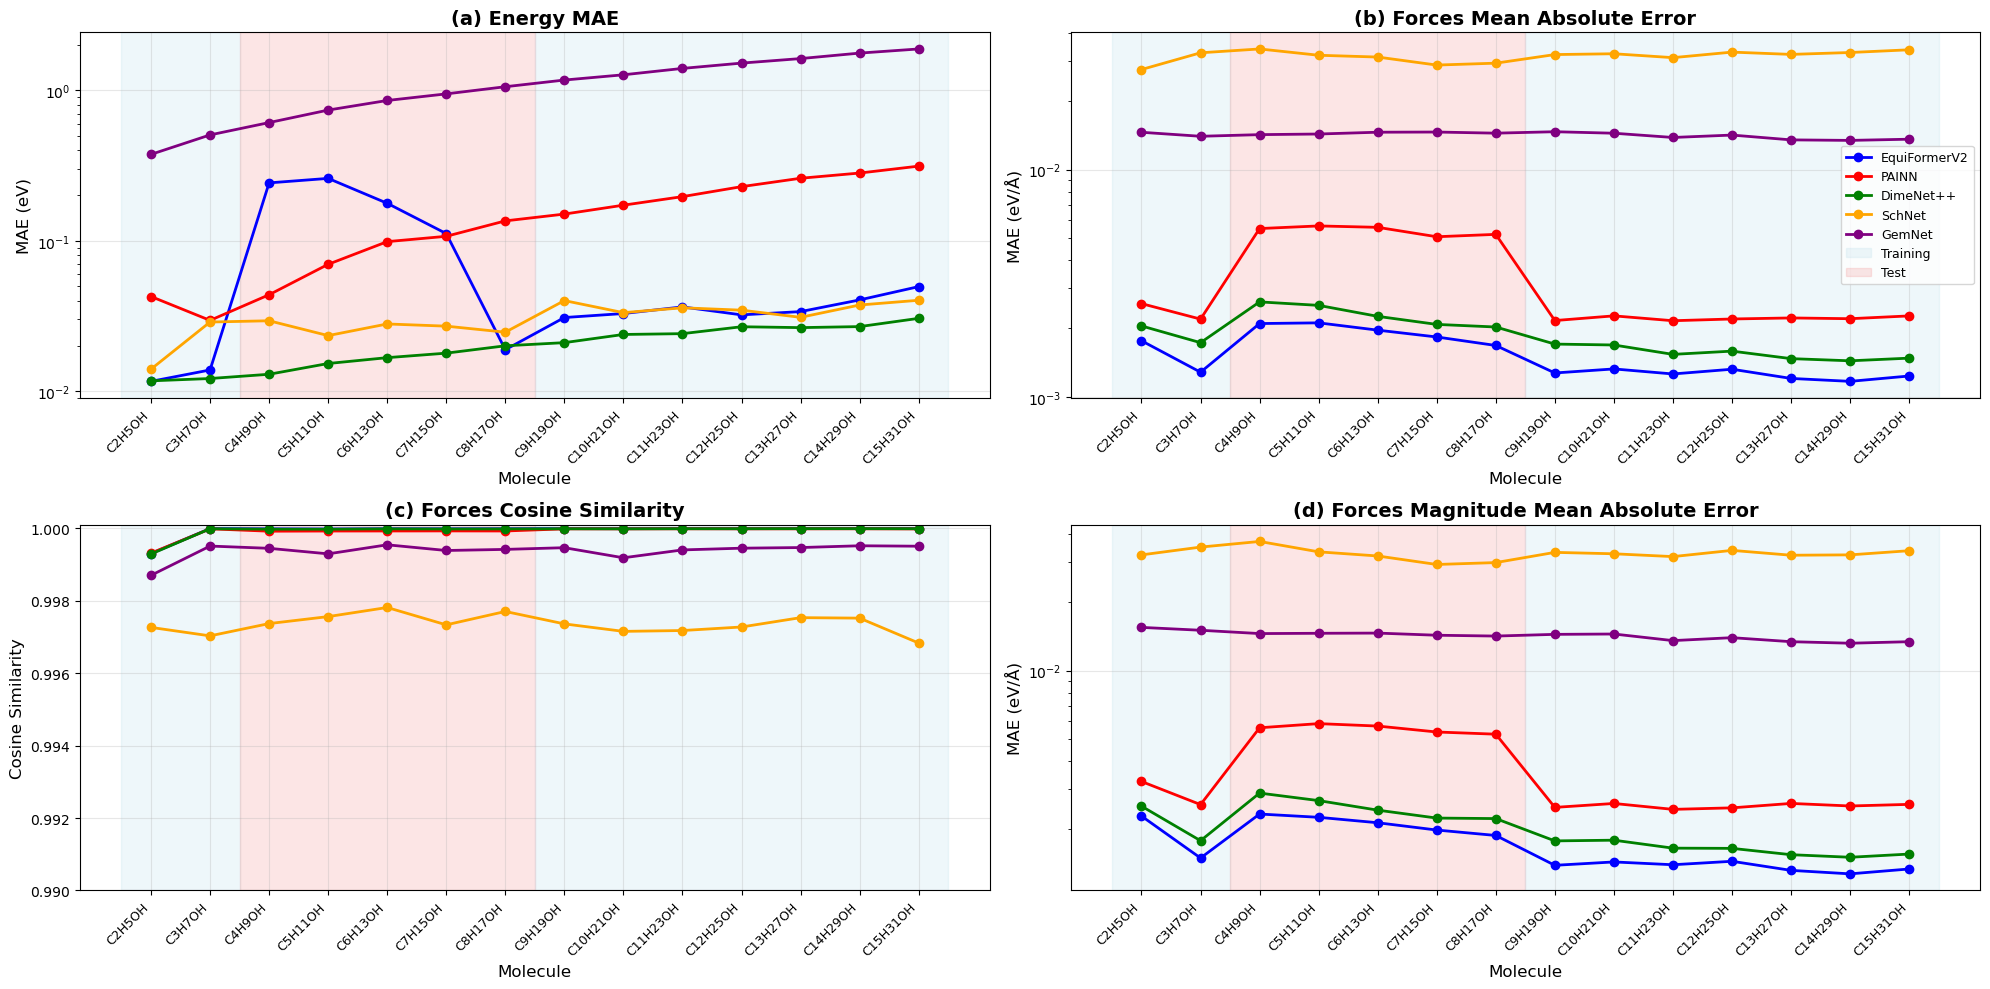

In [41]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import itertools
from typing import List

# Set up the figure with three subplots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 10))

# Define molecule names
alcohol_molecule_names: List[str] = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]

# Define training and test indices based on your description
# Training: C2H5OH (index 0), C3H7OH (index 1), C7H15OH onwards (index 5-13)
# Test: C4H9OH through C6H13OH (index 2-4)
training_indices: List[int] = [0, 1] + list(range(5, 14))  # C2, C3, C7-C15
test_indices: List[int] = list(range(2, 5))  # C4, C5, C6

# Function to add correct background coloring
def add_background_coloring(ax) -> None:
    # Add training regions (C2, C3)
    ax.axvspan(-0.5, 1.5, alpha=0.2, color='lightblue')
    # Add test region (C4, C5, C6)
    ax.axvspan(1.5, 6.5, alpha=0.2, color='lightcoral')
    # Add training region (C7 onwards)
    ax.axvspan(6.5, 13.5, alpha=0.2, color='lightblue')

# Subplot 1: Energy MAE
add_background_coloring(ax1)
for model in alcohol_energy_df_updated['Model'].unique():
    model_data = alcohol_energy_df_updated[alcohol_energy_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(alcohol_molecule_names))
        y_coords = model_data['MAE'].values
        ax1.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model], label=model)
ax1.set_xlabel('Molecule', fontsize=12)
ax1.set_ylabel('MAE (eV)', fontsize=12)
ax1.set_title('(a) Energy MAE', fontsize=14, fontweight='bold')
ax1.set_xticks(range(len(alcohol_molecule_names)))
ax1.set_xticklabels(alcohol_molecule_names, rotation=45, ha='right', fontsize=9)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)

# Subplot 2: Forces MAE
add_background_coloring(ax2)
for model in alcohol_forces_df_updated['Model'].unique():
    model_data = alcohol_forces_df_updated[alcohol_forces_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(alcohol_molecule_names))
        y_coords = model_data['MAE'].values
        ax2.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model])
ax2.set_xlabel('Molecule', fontsize=12)
ax2.set_ylabel('MAE (eV/Å)', fontsize=12)
ax2.set_title('(b) Forces Mean Absolute Error', fontsize=14, fontweight='bold')
ax2.set_xticks(range(len(alcohol_molecule_names)))
ax2.set_xticklabels(alcohol_molecule_names, rotation=45, ha='right', fontsize=9)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=9)

# Subplot 3: Cosine Similarity
add_background_coloring(ax3)
for model in alcohol_forces_df_updated['Model'].unique():
    model_data = alcohol_forces_df_updated[alcohol_forces_df_updated['Model'] == model]
    x_coords = range(len(alcohol_molecule_names))
    y_coords = model_data['Cosine_Similarity'].values
    ax3.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax3.set_xlabel('Molecule', fontsize=12)
ax3.set_ylabel('Cosine Similarity', fontsize=12)
ax3.set_title('(c) Forces Cosine Similarity', fontsize=14, fontweight='bold')
ax3.set_xticks(range(len(alcohol_molecule_names)))
ax3.set_xticklabels(alcohol_molecule_names, rotation=45, ha='right', fontsize=9)
ax3.set_ylim(0.99, 1.0001)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax3.grid(True, alpha=0.3)

# Subplot 4: Force Magnitude MAE
add_background_coloring(ax4)
for model in alcohol_forces_df_updated['Model'].unique():
    model_data = alcohol_forces_df_updated[alcohol_forces_df_updated['Model'] == model]
    x_coords = range(len(alcohol_molecule_names))
    y_coords = model_data['Magnitude_MAE'].values
    ax4.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax4.set_xlabel('Molecule', fontsize=12)
ax4.set_ylabel('MAE (eV/Å)', fontsize=12)
ax4.set_title('(d) Forces Magnitude Mean Absolute Error', fontsize=14, fontweight='bold')
ax4.set_xticks(range(len(alcohol_molecule_names)))
ax4.set_xticklabels(alcohol_molecule_names, rotation=45, ha='right', fontsize=9)
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax4.grid(True, alpha=0.3)
ax4.set_yscale('log')

# Add background color patches to legend
from matplotlib.patches import Patch
training_patch = Patch(color='lightblue', alpha=0.2, label='Training')
test_patch = Patch(color='lightcoral', alpha=0.2, label='Test')

# Get existing legend handles and labels
handles, labels = ax1.get_legend_handles_labels()

# Add background patches to legend
handles.extend([training_patch, test_patch])
labels.extend(['Training', 'Test'])

# Update legend with background patches
ax2.legend(handles, labels, fontsize=9)

plt.tight_layout()

# Save to PDF with selectable text
plt.savefig('generalisation_checkpoints/cross_length_functionality/cross_length_functionality_figure_alcohol.pdf', 
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')

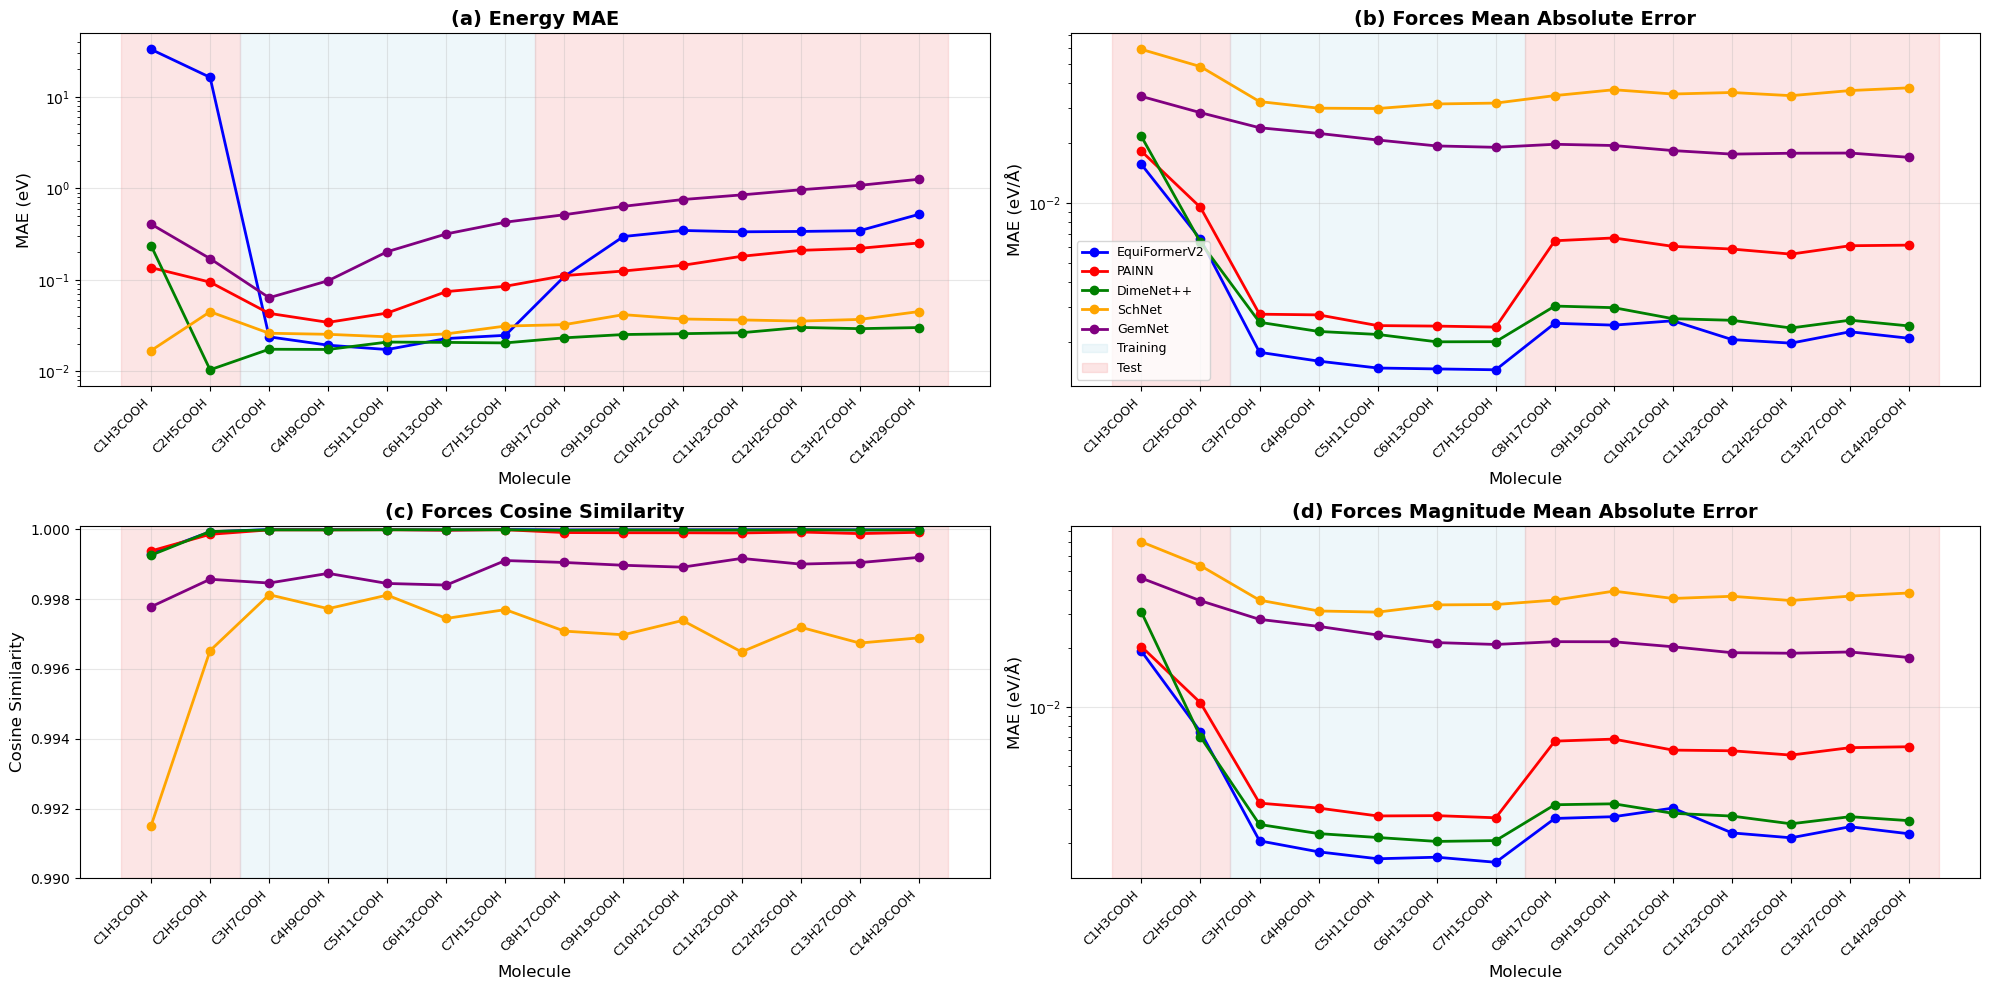

In [42]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import itertools
from typing import List

# Set up the figure with three subplots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 10))

# Define molecule names
carboxylic_molecule_names: List[str] = [f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)]

# Define training and test indices based on your description
# Training: C3H5COOH through C7H15COOH (indices 2-6)
# Test: C1H1COOH, C2H3COOH (indices 0-1) and C8H17COOH onwards (indices 7-13)
training_indices: List[int] = list(range(2, 7))  # C3-C7 (indices 2-6)
test_indices: List[int] = [0, 1] + list(range(7, 14))  # C1, C2, C8-C15

# Function to add correct background coloring
def add_background_coloring(ax) -> None:
    # Add test region (C1, C2)
    ax.axvspan(-0.5, 1.5, alpha=0.2, color='lightcoral')
    # Add training region (C3-C7)
    ax.axvspan(1.5, 6.5, alpha=0.2, color='lightblue')
    # Add test region (C8 onwards)
    ax.axvspan(6.5, 13.5, alpha=0.2, color='lightcoral')

# Subplot 1: Energy MAE
add_background_coloring(ax1)
for model in carboxylic_energy_df_updated['Model'].unique():
    model_data = carboxylic_energy_df_updated[carboxylic_energy_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(carboxylic_molecule_names))
        y_coords = model_data['MAE'].values
        ax1.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model], label=model)
ax1.set_xlabel('Molecule', fontsize=12)
ax1.set_ylabel('MAE (eV)', fontsize=12)
ax1.set_title('(a) Energy MAE', fontsize=14, fontweight='bold')
ax1.set_xticks(range(len(carboxylic_molecule_names)))
ax1.set_xticklabels(carboxylic_molecule_names, rotation=45, ha='right', fontsize=9)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)

# Subplot 2: Forces MAE
add_background_coloring(ax2)
for model in carboxylic_forces_df_updated['Model'].unique():
    model_data = carboxylic_forces_df_updated[carboxylic_forces_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(carboxylic_molecule_names))
        y_coords = model_data['MAE'].values
        ax2.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model])
ax2.set_xlabel('Molecule', fontsize=12)
ax2.set_ylabel('MAE (eV/Å)', fontsize=12)
ax2.set_title('(b) Forces Mean Absolute Error', fontsize=14, fontweight='bold')
ax2.set_xticks(range(len(carboxylic_molecule_names)))
ax2.set_xticklabels(carboxylic_molecule_names, rotation=45, ha='right', fontsize=9)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)

# Subplot 3: Cosine Similarity
add_background_coloring(ax3)
for model in carboxylic_forces_df_updated['Model'].unique():
    model_data = carboxylic_forces_df_updated[carboxylic_forces_df_updated['Model'] == model]
    x_coords = range(len(carboxylic_molecule_names))
    y_coords = model_data['Cosine_Similarity'].values
    ax3.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax3.set_xlabel('Molecule', fontsize=12)
ax3.set_ylabel('Cosine Similarity', fontsize=12)
ax3.set_title('(c) Forces Cosine Similarity', fontsize=14, fontweight='bold')
ax3.set_xticks(range(len(carboxylic_molecule_names)))
ax3.set_xticklabels(carboxylic_molecule_names, rotation=45, ha='right', fontsize=9)
ax3.set_ylim(0.99, 1.0001)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax3.grid(True, alpha=0.3)

# Subplot 4: Force Magnitude MAE
add_background_coloring(ax4)
for model in carboxylic_forces_df_updated['Model'].unique():
    model_data = carboxylic_forces_df_updated[carboxylic_forces_df_updated['Model'] == model]
    x_coords = range(len(carboxylic_molecule_names))
    y_coords = model_data['Magnitude_MAE'].values
    ax4.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax4.set_xlabel('Molecule', fontsize=12)
ax4.set_ylabel('MAE (eV/Å)', fontsize=12)
ax4.set_title('(d) Forces Magnitude Mean Absolute Error', fontsize=14, fontweight='bold')
ax4.set_xticks(range(len(carboxylic_molecule_names)))
ax4.set_xticklabels(carboxylic_molecule_names, rotation=45, ha='right', fontsize=9)
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax4.grid(True, alpha=0.3)
ax4.set_yscale('log')

# Add background color patches to legend
from matplotlib.patches import Patch
training_patch = Patch(color='lightblue', alpha=0.2, label='Training')
test_patch = Patch(color='lightcoral', alpha=0.2, label='Test')

# Get existing legend handles and labels from ax1
handles, labels = ax1.get_legend_handles_labels()

# Add background patches to legend
handles.extend([training_patch, test_patch])
labels.extend(['Training', 'Test'])

# Update legend with background patches on ax2
ax2.legend(handles, labels, fontsize=9)

plt.tight_layout()

# Save to PDF with selectable text
plt.savefig('generalisation_checkpoints/cross_length_functionality/cross_length_functionality_figure_carboxylic.pdf', 
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')

/tmp/ipykernel_1057550/3744899134.py:73: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticks(), fontsize=fontsize, fontweight='bold')
/tmp/ipykernel_1057550/3744899134.py:73: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticks(), fontsize=fontsize, fontweight='bold')
/tmp/ipykernel_1057550/3744899134.py:73: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticks(), fontsize=fontsize, fontweight='bold')
/tmp/ipykernel_1057550/3744899134.py:73: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticks(), fontsize=fontsize, fontweight='bold')


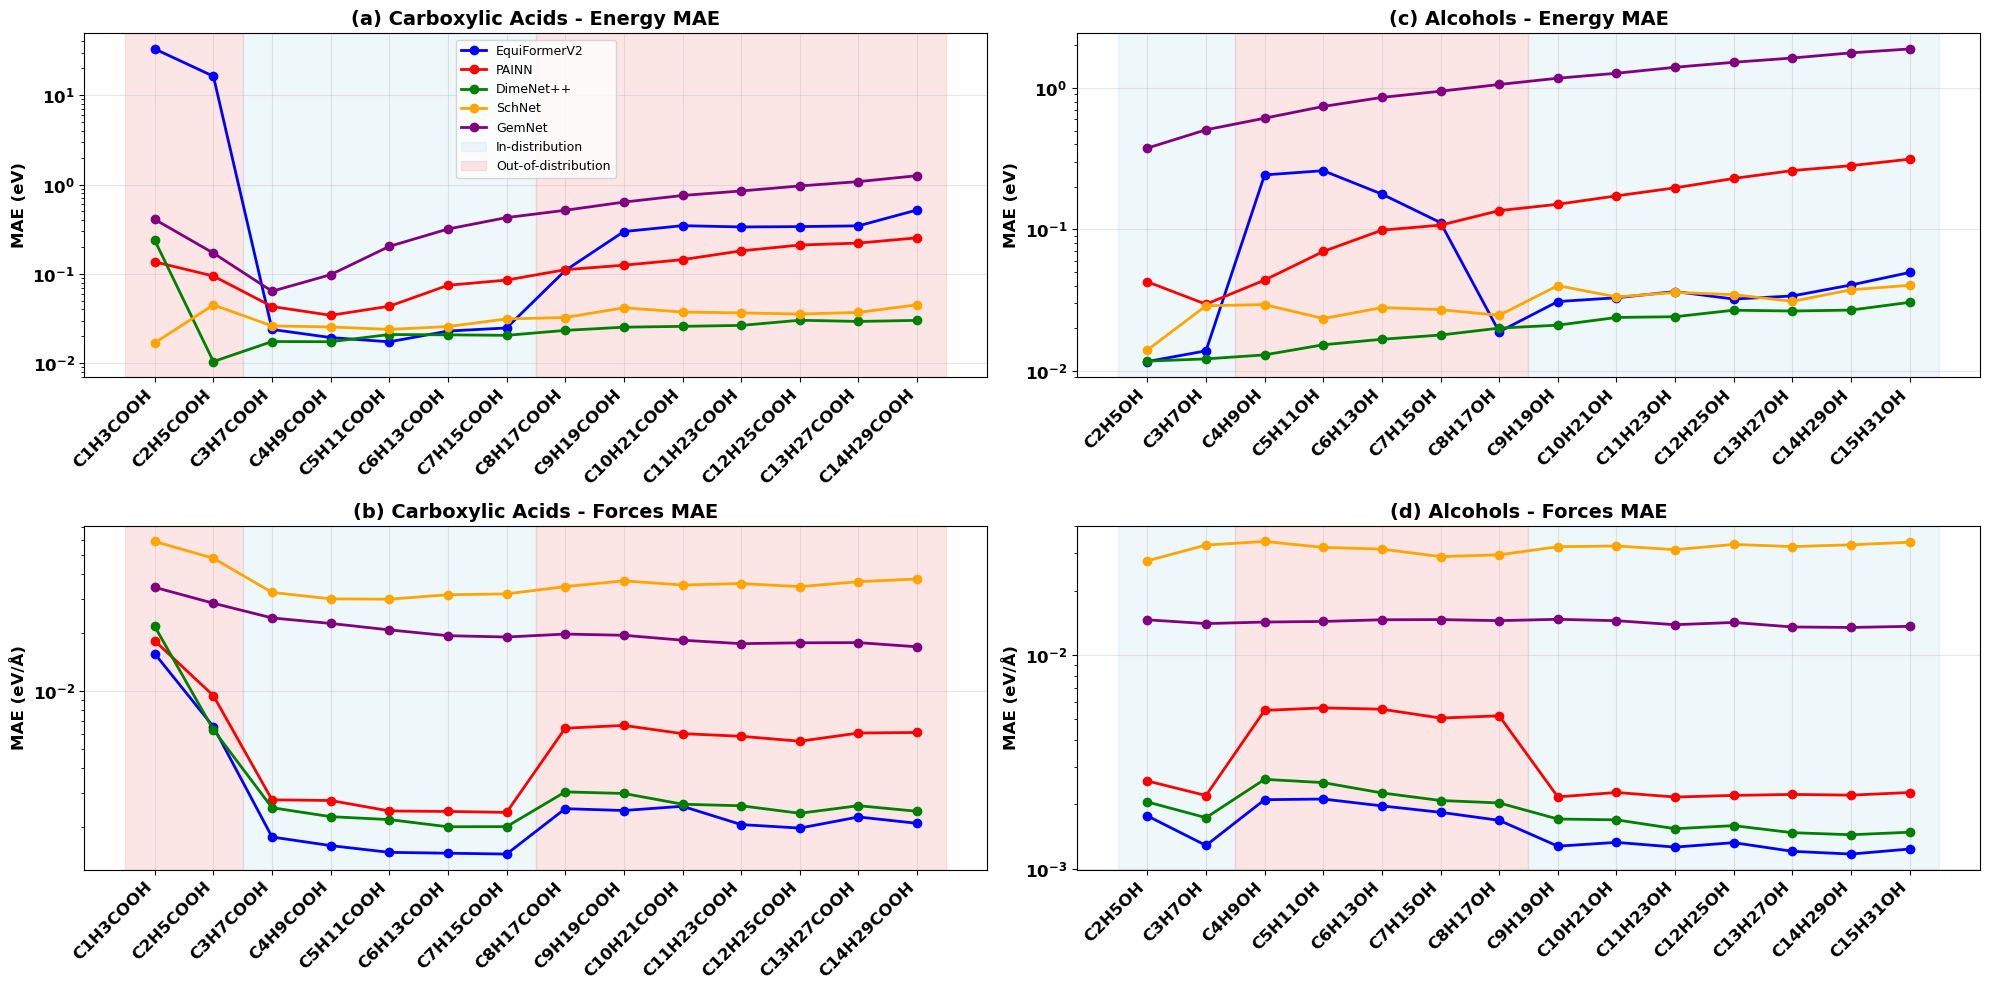

/tmp/ipykernel_1057550/3744899134.py:73: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticks(), fontsize=fontsize, fontweight='bold')
/tmp/ipykernel_1057550/3744899134.py:73: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticks(), fontsize=fontsize, fontweight='bold')
/tmp/ipykernel_1057550/3744899134.py:73: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticks(), fontsize=fontsize, fontweight='bold')
/tmp/ipykernel_1057550/3744899134.py:73: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(ax.get_yticks(), fontsize=fontsize, fontweight='bold')


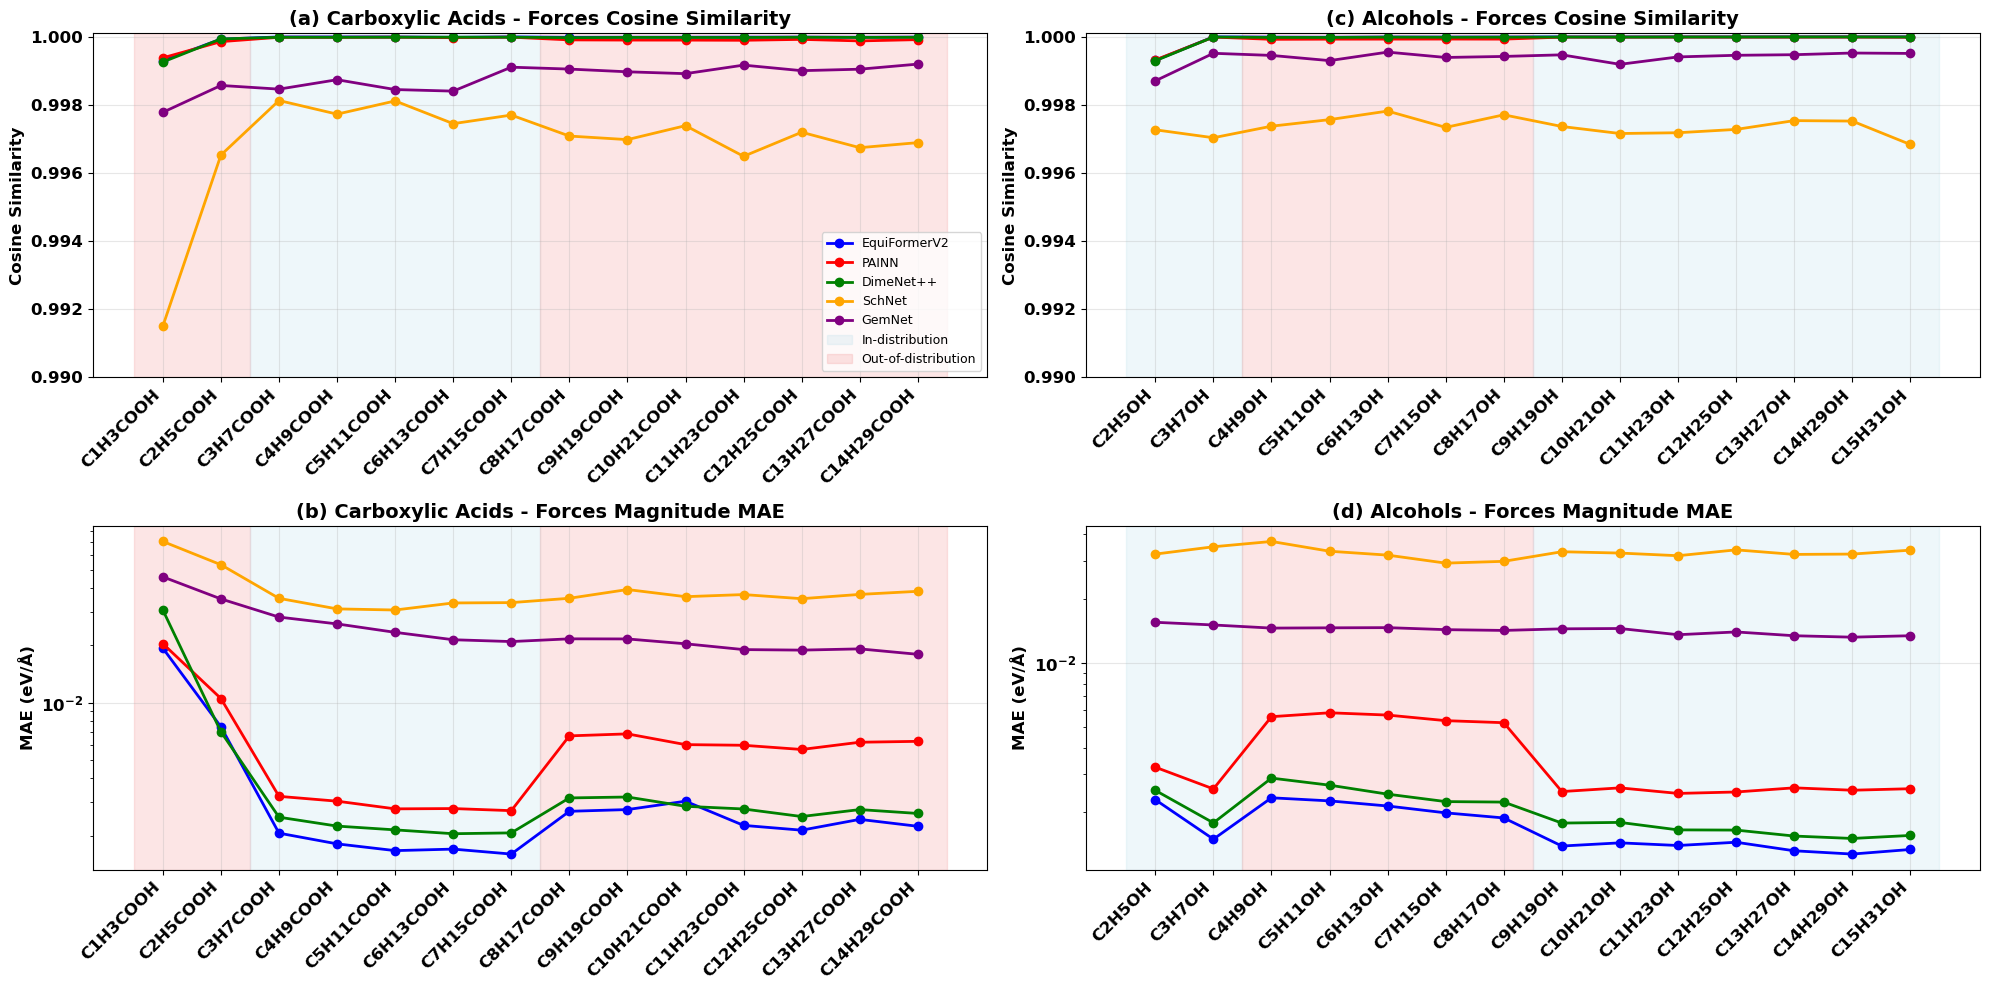

Figures saved successfully:
- Main figure: combined_main.pdf
- Appendix figure: combined_appendix.pdf


In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from typing import List, Dict, Any
from matplotlib.patches import Patch
from matplotlib.axes import Axes


class MoleculeDataGenerator:
    """Generator for molecule names and training/test indices."""
    
    @staticmethod
    def generate_carboxylic_molecule_names(start_range: int = 2, end_range: int = 16) -> List[str]:
        """Generate carboxylic acid molecule names."""
        return [f"C{i-1}H{2*i-1}COOH" for i in range(start_range, end_range)]
    
    @staticmethod
    def generate_alcohol_molecule_names(start_range: int = 2, end_range: int = 16) -> List[str]:
        """Generate alcohol molecule names."""
        return [f"C{i}H{2*i+1}OH" for i in range(start_range, end_range)]
    
    @staticmethod
    def get_carboxylic_indices() -> tuple[List[int], List[int]]:
        """Get training and test indices for carboxylic acids."""
        training_indices = list(range(2, 7))  # C3-C7 (indices 2-6)
        test_indices = [0, 1] + list(range(7, 14))  # C1, C2, C8-C15
        return training_indices, test_indices
    
    @staticmethod
    def get_alcohol_indices() -> tuple[List[int], List[int]]:
        """Get training and test indices for alcohols."""
        training_indices = [0, 1] + list(range(5, 14))  # C2, C3, C7-C15
        test_indices = list(range(2, 5))  # C4, C5, C6
        return training_indices, test_indices


class BackgroundColoringManager:
    """Manager for adding background coloring to plots."""
    
    @staticmethod
    def add_carboxylic_background_coloring(ax: Axes) -> None:
        """Add background coloring for carboxylic acid plots."""
        # Test region (C1, C2)
        ax.axvspan(-0.5, 1.5, alpha=0.2, color='lightcoral')
        # Training region (C3-C7)
        ax.axvspan(1.5, 6.5, alpha=0.2, color='lightblue')
        # Test region (C8 onwards)
        ax.axvspan(6.5, 13.5, alpha=0.2, color='lightcoral')
    
    @staticmethod
    def add_alcohol_background_coloring(ax: Axes) -> None:
        """Add background coloring for alcohol plots."""
        # Training regions (C2, C3)
        ax.axvspan(-0.5, 1.5, alpha=0.2, color='lightblue')
        # Test region (C4, C5, C6)
        ax.axvspan(1.5, 6.5, alpha=0.2, color='lightcoral')
        # Training region (C7 onwards)
        ax.axvspan(6.5, 13.5, alpha=0.2, color='lightblue')


class PlotStyleManager:
    """Manager for plot styling and formatting."""
    
    @staticmethod
    def apply_common_styling(ax: Axes, xlabel: str, ylabel: str, title: str, 
                           molecule_names: List[str], fontsize: int = 12) -> None:
        """Apply common styling to axes."""
        # ax.set_xlabel(xlabel, fontsize=fontsize, fontweight='bold')
        ax.set_ylabel(ylabel, fontsize=fontsize, fontweight='bold')
        ax.set_title(title, fontsize=14, fontweight='bold')
        ax.set_xticks(range(len(molecule_names)))
        ax.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=fontsize, fontweight='bold')
        ax.set_yticklabels(ax.get_yticks(), fontsize=fontsize, fontweight='bold')
        ax.grid(True, alpha=0.3)
    
    @staticmethod
    def apply_log_scale(ax: Axes) -> None:
        """Apply logarithmic scale to y-axis."""
        ax.set_yscale('log')
    
    @staticmethod
    def apply_cosine_similarity_formatting(ax: Axes) -> None:
        """Apply specific formatting for cosine similarity plots."""
        ax.set_ylim(0.99, 1.0001)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
    
    @staticmethod
    def apply_magnitude_formatting(ax: Axes) -> None:
        """Apply specific formatting for magnitude plots."""
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))


class DataPlotter:
    """Plotter for model data."""
    
    @staticmethod
    def plot_model_data(ax: Axes, dataframe: pd.DataFrame, column: str, 
                       molecule_names: List[str], model_colors: Dict[str, Any], 
                       add_labels: bool = False) -> None:
        """Plot model data on given axes."""
        for model in dataframe['Model'].unique():
            model_data = dataframe[dataframe['Model'] == model]
            if not model_data[column].isna().all():
                x_coords = range(len(molecule_names))
                y_coords = model_data[column].values
                label = model if add_labels else None
                ax.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                       color=model_colors[model], label=label)


class LegendManager:
    """Manager for legend creation and updates."""
    
    @staticmethod
    def create_combined_legend(ax: Axes) -> None:
        """Create legend with training/test background patches."""
        training_patch = Patch(color='lightblue', alpha=0.2, label='Training')
        test_patch = Patch(color='lightcoral', alpha=0.2, label='Test')
        
        handles, labels = ax.get_legend_handles_labels()
        handles.extend([training_patch, test_patch])
        labels.extend(['In-distribution', 'Out-of-distribution'])
        
        ax.legend(handles, labels, fontsize=9)


def create_main_figure(carboxylic_energy_df: pd.DataFrame, carboxylic_forces_df: pd.DataFrame,
                      alcohol_energy_df: pd.DataFrame, alcohol_forces_df: pd.DataFrame,
                      model_colors: Dict[str, Any]) -> None:
    """Create main figure with energy and forces MAE plots."""
    
    # Initialize data generators
    data_gen = MoleculeDataGenerator()
    carboxylic_names = data_gen.generate_carboxylic_molecule_names()
    alcohol_names = data_gen.generate_alcohol_molecule_names()
    
    # Initialize managers
    bg_manager = BackgroundColoringManager()
    style_manager = PlotStyleManager()
    plotter = DataPlotter()
    legend_manager = LegendManager()
    
    # Create figure
    fig, ((ax1, ax3), (ax2, ax4)) = plt.subplots(2, 2, figsize=(20, 10))
    
    # First row: Carboxylic acids
    # Energy MAE
    bg_manager.add_carboxylic_background_coloring(ax1)
    plotter.plot_model_data(ax1, carboxylic_energy_df, 'MAE', carboxylic_names, 
                           model_colors, add_labels=True)
    style_manager.apply_common_styling(ax1, 'Molecule', 'MAE (eV)', 
                                     '(a) Carboxylic Acids - Energy MAE', carboxylic_names)
    style_manager.apply_log_scale(ax1)
    
    # Forces MAE
    bg_manager.add_carboxylic_background_coloring(ax2)
    plotter.plot_model_data(ax2, carboxylic_forces_df, 'MAE', carboxylic_names, model_colors)
    style_manager.apply_common_styling(ax2, 'Molecule', 'MAE (eV/Å)', 
                                     '(b) Carboxylic Acids - Forces MAE', carboxylic_names)
    style_manager.apply_log_scale(ax2)
    legend_manager.create_combined_legend(ax1)
    
    # Second row: Alcohols
    # Energy MAE
    bg_manager.add_alcohol_background_coloring(ax3)
    plotter.plot_model_data(ax3, alcohol_energy_df, 'MAE', alcohol_names, model_colors)
    style_manager.apply_common_styling(ax3, 'Molecule', 'MAE (eV)', 
                                     '(c) Alcohols - Energy MAE', alcohol_names)
    style_manager.apply_log_scale(ax3)
    
    # Forces MAE
    bg_manager.add_alcohol_background_coloring(ax4)
    plotter.plot_model_data(ax4, alcohol_forces_df, 'MAE', alcohol_names, model_colors)
    style_manager.apply_common_styling(ax4, 'Molecule', 'MAE (eV/Å)', 
                                     '(d) Alcohols - Forces MAE', alcohol_names)
    style_manager.apply_log_scale(ax4)
    
    plt.tight_layout()
    
    # Save main figure
    plt.savefig('generalisation_checkpoints/cross_length_functionality/combined_main.pdf', 
                format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
    plt.show()
    plt.close()


def create_appendix_figure(carboxylic_forces_df: pd.DataFrame, alcohol_forces_df: pd.DataFrame,
                          model_colors: Dict[str, Any]) -> None:
    """Create appendix figure with cosine similarity and magnitude MAE plots."""
    
    # Initialize data generators
    data_gen = MoleculeDataGenerator()
    carboxylic_names = data_gen.generate_carboxylic_molecule_names()
    alcohol_names = data_gen.generate_alcohol_molecule_names()
    
    # Initialize managers
    bg_manager = BackgroundColoringManager()
    style_manager = PlotStyleManager()
    plotter = DataPlotter()
    legend_manager = LegendManager()
    
    # Create figure
    fig, ((ax1, ax3), (ax2, ax4)) = plt.subplots(2, 2, figsize=(20, 10))
    
    # First row: Carboxylic acids
    # Cosine Similarity
    bg_manager.add_carboxylic_background_coloring(ax1)
    plotter.plot_model_data(ax1, carboxylic_forces_df, 'Cosine_Similarity', 
                           carboxylic_names, model_colors, add_labels=True)
    style_manager.apply_common_styling(ax1, 'Molecule', 'Cosine Similarity', 
                                     '(a) Carboxylic Acids - Forces Cosine Similarity', carboxylic_names)
    style_manager.apply_cosine_similarity_formatting(ax1)
    
    # Force Magnitude MAE
    bg_manager.add_carboxylic_background_coloring(ax2)
    plotter.plot_model_data(ax2, carboxylic_forces_df, 'Magnitude_MAE', carboxylic_names, model_colors)
    style_manager.apply_common_styling(ax2, 'Molecule', 'MAE (eV/Å)', 
                                     '(b) Carboxylic Acids - Forces Magnitude MAE', carboxylic_names)
    style_manager.apply_magnitude_formatting(ax2)
    style_manager.apply_log_scale(ax2)
    legend_manager.create_combined_legend(ax1)
    
    # Second row: Alcohols
    # Cosine Similarity
    bg_manager.add_alcohol_background_coloring(ax3)
    plotter.plot_model_data(ax3, alcohol_forces_df, 'Cosine_Similarity', alcohol_names, model_colors)
    style_manager.apply_common_styling(ax3, 'Molecule', 'Cosine Similarity', 
                                     '(c) Alcohols - Forces Cosine Similarity', alcohol_names)
    style_manager.apply_cosine_similarity_formatting(ax3)
    
    # Force Magnitude MAE
    bg_manager.add_alcohol_background_coloring(ax4)
    plotter.plot_model_data(ax4, alcohol_forces_df, 'Magnitude_MAE', alcohol_names, model_colors)
    style_manager.apply_common_styling(ax4, 'Molecule', 'MAE (eV/Å)', 
                                     '(d) Alcohols - Forces Magnitude MAE', alcohol_names)
    style_manager.apply_magnitude_formatting(ax4)
    style_manager.apply_log_scale(ax4)
    
    plt.tight_layout()
    
    # Save appendix figure
    plt.savefig('generalisation_checkpoints/cross_length_functionality/combined_appendix.pdf', 
                format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
    plt.show()
    plt.close()


def main(carboxylic_energy_df_updated: pd.DataFrame, carboxylic_forces_df_updated: pd.DataFrame,
         alcohol_energy_df_updated: pd.DataFrame, alcohol_forces_df_updated: pd.DataFrame,
         model_colors_updated: Dict[str, Any]) -> None:
    """Main function to create both figures."""
    
    # Create main figure (ax1, ax2 from both original figures)
    create_main_figure(carboxylic_energy_df_updated, carboxylic_forces_df_updated,
                      alcohol_energy_df_updated, alcohol_forces_df_updated, 
                      model_colors_updated)
    
    # Create appendix figure (ax3, ax4 from both original figures)
    create_appendix_figure(carboxylic_forces_df_updated, alcohol_forces_df_updated, 
                          model_colors_updated)
    
    print("Figures saved successfully:")
    print("- Main figure: combined_main.pdf")
    print("- Appendix figure: combined_appendix.pdf")


# Example usage:
main(carboxylic_energy_df_updated, carboxylic_forces_df_updated,
     alcohol_energy_df_updated, alcohol_forces_df_updated, model_colors_updated)

In [50]:
import pickle
# Save updated dataframes and model colors to a pickle file
with open('generalisation_checkpoints/cross_length_functionality/updated_data.pkl', 'wb') as f:
    pickle.dump({
        'carboxylic_energy_df_updated': carboxylic_energy_df_updated,
        'carboxylic_forces_df_updated': carboxylic_forces_df_updated,
        'alcohol_energy_df_updated': alcohol_energy_df_updated,
        'alcohol_forces_df_updated': alcohol_forces_df_updated,
        'model_colors_updated': model_colors_updated
    }, f)


In [1]:
%cd ..
import pickle

# Load updated dataframes and model colors from the pickle file
with open('generalisation_checkpoints/cross_length_functionality/updated_data.pkl', 'rb') as f:
    data = pickle.load(f)
    carboxylic_energy_df_updated = data['carboxylic_energy_df_updated']
    carboxylic_forces_df_updated = data['carboxylic_forces_df_updated']
    alcohol_energy_df_updated = data['alcohol_energy_df_updated']
    alcohol_forces_df_updated = data['alcohol_forces_df_updated']
    model_colors_updated = data['model_colors_updated']

/home/masoud/Projects/SCAI


In [9]:
import json

# Save each dataframe as both CSV and JSON files for backup and sharing

# Save alcohol energy dataframe
alcohol_energy_df_updated.to_csv('generalisation_checkpoints/cross_length_functionality/json/alcohol_energy_data.csv', index=False)
alcohol_energy_df_updated.to_json('generalisation_checkpoints/cross_length_functionality/json/alcohol_energy_data.json', orient='records', indent=2)

# Save alcohol forces dataframe
alcohol_forces_df_updated.to_csv('generalisation_checkpoints/cross_length_functionality/json/alcohol_forces_data.csv', index=False)
alcohol_forces_df_updated.to_json('generalisation_checkpoints/cross_length_functionality/json/alcohol_forces_data.json', orient='records', indent=2)

# Save carboxylic energy dataframe
carboxylic_energy_df_updated.to_csv('generalisation_checkpoints/cross_length_functionality/json/carboxylic_energy_data.csv', index=False)
carboxylic_energy_df_updated.to_json('generalisation_checkpoints/cross_length_functionality/json/carboxylic_energy_data.json', orient='records', indent=2)

# Save carboxylic forces dataframe
carboxylic_forces_df_updated.to_csv('generalisation_checkpoints/cross_length_functionality/json/carboxylic_forces_data.csv', index=False)
carboxylic_forces_df_updated.to_json('generalisation_checkpoints/cross_length_functionality/json/carboxylic_forces_data.json', orient='records', indent=2)

# Save model colors as JSON
with open('generalisation_checkpoints/cross_length_functionality/model_colors.json', 'w') as f:
    json.dump(model_colors_updated, f, indent=2)

print("All dataframes saved successfully!")
print("Files saved:")
print("- alcohol_energy_data.csv/.json")
print("- alcohol_forces_data.csv/.json") 
print("- carboxylic_energy_data.csv/.json")
print("- carboxylic_forces_data.csv/.json")
print("- model_colors.json")

All dataframes saved successfully!
Files saved:
- alcohol_energy_data.csv/.json
- alcohol_forces_data.csv/.json
- carboxylic_energy_data.csv/.json
- carboxylic_forces_data.csv/.json
- model_colors.json


In [11]:
import pandas as pd

def create_latex_table_per_molecule():
    """Generate LaTeX table with metrics per molecule"""
    
    # Combine all dataframes
    all_data = []
    
    # Process alcohol data
    for _, row in alcohol_energy_df_updated.iterrows():
        model_energy = row['MAE']
        
        # Find corresponding forces data
        forces_row = alcohol_forces_df_updated[
            (alcohol_forces_df_updated['Model'] == row['Model']) & 
            (alcohol_forces_df_updated['Molecule'] == row['Molecule'])
        ].iloc[0]
        
        all_data.append({
            'Molecule': row['Molecule'],
            'Model': row['Model'],
            'Forces_MAE': forces_row['MAE'],
            'Cosine_Similarity': forces_row['Cosine_Similarity'],
            'Forces_Magnitude': forces_row['Magnitude_MAE'],
            'Energy_MAE': model_energy,
            'Type': 'Alcohol'
        })
    
    # Process carboxylic acid data
    for _, row in carboxylic_energy_df_updated.iterrows():
        model_energy = row['MAE']
        
        # Find corresponding forces data
        forces_row = carboxylic_forces_df_updated[
            (carboxylic_forces_df_updated['Model'] == row['Model']) & 
            (carboxylic_forces_df_updated['Molecule'] == row['Molecule'])
        ].iloc[0]
        
        all_data.append({
            'Molecule': row['Molecule'],
            'Model': row['Model'],
            'Forces_MAE': forces_row['MAE'],
            'Cosine_Similarity': forces_row['Cosine_Similarity'],
            'Forces_Magnitude': forces_row['Magnitude_MAE'],
            'Energy_MAE': model_energy,
            'Type': 'Carboxylic'
        })
    
    df_all = pd.DataFrame(all_data)
    
    # Get unique molecules and models
    molecules = sorted(df_all['Molecule'].unique(), key=lambda x: (len(x), x))
    models = ['EquiFormerV2', 'PAINN', 'DimeNet++', 'SchNet', 'GemNet']
    
    # Create LaTeX table
    latex_table = []
    latex_table.append("\\begin{table}[t!]")
    latex_table.append("\\footnotesize")
    latex_table.append("\\setlength\\tabcolsep{2pt}")
    latex_table.append("    \\centering")
    latex_table.append("    \\caption{Model performance metrics per molecule for cross-length functionality generalization.}")
    latex_table.append("    \\begin{tabular}{lllllll}")
    latex_table.append("        \\toprule")
    latex_table.append("        \\textbf{Molecule} & \\textbf{Model} & \\textbf{Forces MAE} & \\textbf{Cosine Sim.} & \\textbf{Forces Mag.} & \\textbf{Energy MAE} & \\textbf{Distribution} \\\\")
    latex_table.append("        \\midrule")
    
    # Define distribution for each molecule
    alcohol_training = ['C2H5OH', 'C3H7OH'] + [f'C{i}H{2*i+1}OH' for i in range(7, 16)]
    alcohol_test = [f'C{i}H{2*i+1}OH' for i in range(4, 7)]
    carboxylic_training = [f'C{i-1}H{2*i-1}COOH' for i in range(4, 8)]
    carboxylic_test = ['C1H3COOH', 'C2H5COOH'] + [f'C{i-1}H{2*i-1}COOH' for i in range(9, 16)]
    
    def get_distribution(molecule):
        if molecule in alcohol_training or molecule in carboxylic_training:
            return "ID"
        else:
            return "OOD"
    
    # Group by molecule
    for i, molecule in enumerate(molecules):
        molecule_data = df_all[df_all['Molecule'] == molecule]
        distribution = get_distribution(molecule)
        
        for j, model in enumerate(models):
            model_data = molecule_data[molecule_data['Model'] == model]
            
            if not model_data.empty:
                row_data = model_data.iloc[0]
                
                if j == 0:  # First model for this molecule
                    latex_table.append(f"        \\multirow{{5}}{{*}}{{{molecule}}} ")
                else:
                    latex_table.append("         ")
                
                latex_table[-1] += f"& {model} & {row_data['Forces_MAE']:.5f} & {row_data['Cosine_Similarity']:.4f} & {row_data['Forces_Magnitude']:.5f} & {row_data['Energy_MAE']:.5f} & {distribution} \\\\"
        
        if i < len(molecules) - 1:  # Add midrule between molecules except for the last one
            latex_table.append("        \\midrule")
    
    latex_table.append("        \\bottomrule")
    latex_table.append("    \\end{tabular}")
    latex_table.append("\\end{table}")
    
    return '\n'.join(latex_table)

# Generate and save the table
latex_table_content = create_latex_table_per_molecule()

# Save to file
with open('generalisation_checkpoints/cross_length_functionality/molecule_metrics_table.tex', 'w') as f:
    f.write(latex_table_content)

# Print the table
print(latex_table_content)

\begin{table}[t!]
\footnotesize
\setlength\tabcolsep{2pt}
    \centering
    \caption{Model performance metrics per molecule for cross-length functionality generalization.}
    \begin{tabular}{lllllll}
        \toprule
        \textbf{Molecule} & \textbf{Model} & \textbf{Forces MAE} & \textbf{Cosine Sim.} & \textbf{Forces Mag.} & \textbf{Energy MAE} & \textbf{Distribution} \\
        \midrule
        \multirow{5}{*}{C2H5OH} & EquiFormerV2 & 0.00177 & 0.9993 & 0.00229 & 0.01159 & ID \\
         & PAINN & 0.00257 & 0.9993 & 0.00325 & 0.04252 & ID \\
         & DimeNet++ & 0.00205 & 0.9993 & 0.00253 & 0.01168 & ID \\
         & SchNet & 0.02756 & 0.9973 & 0.03234 & 0.01397 & ID \\
         & GemNet & 0.01460 & 0.9987 & 0.01550 & 0.37562 & ID \\
        \midrule
        \multirow{5}{*}{C3H7OH} & EquiFormerV2 & 0.00128 & 1.0000 & 0.00149 & 0.01380 & ID \\
         & PAINN & 0.00220 & 1.0000 & 0.00257 & 0.02950 & ID \\
         & DimeNet++ & 0.00173 & 1.0000 & 0.00178 & 0.01210 & ID \\
     

### Old Figures

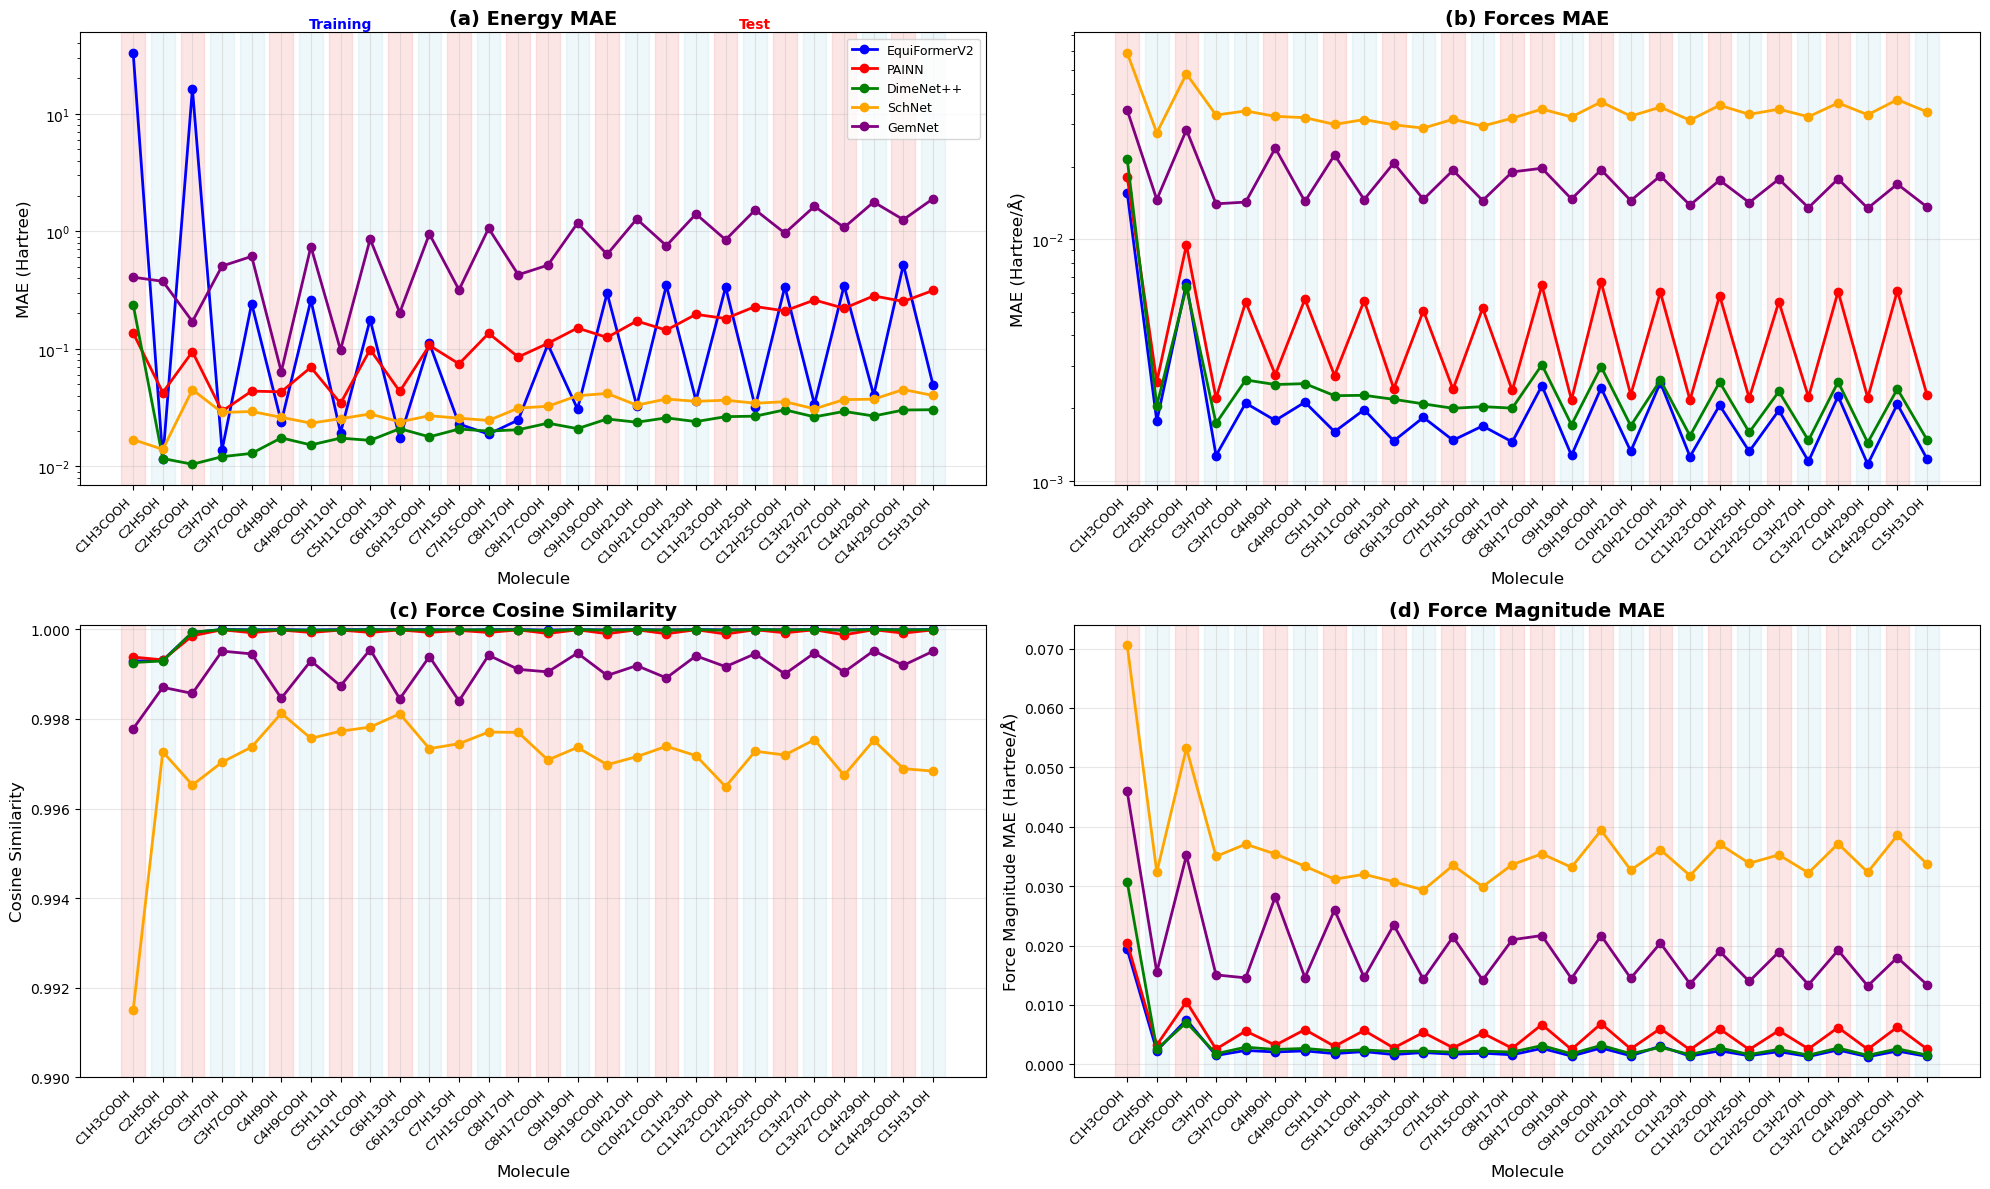

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import itertools
from typing import List

# Set up the figure with three subplots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 12))

# Define molecule names
alcohols: List[str] = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]
acids: List[str] = [f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)]

molecule_names: List[str] = list(itertools.chain.from_iterable(zip(acids, alcohols)))

# Define training indices based on your specification
# Training: carboxylic acids from C3H7COOH to C7H15COOH (indices 2,4,6,8,10 in molecule_names)
# Training: all alcohols except C4H9OH to C8H17OH (exclude indices 5,7,9,11,13 in molecule_names)
training_indices = []
test_indices = []

for i, molecule in enumerate(molecule_names):
    if 'COOH' in molecule:
        # Carboxylic acids
        carbon_count = int(molecule.split('H')[0][1:]) + 1  # +1 because COOH adds one carbon
        if 4 <= carbon_count <= 8:  # C3H7COOH to C7H15COOH corresponds to 4-8 total carbons
            training_indices.append(i)
        else:
            test_indices.append(i)
    else:
        # Alcohols
        carbon_count = int(molecule.split('H')[0][1:])
        if 4 <= carbon_count <= 8:  # C4H9OH to C8H17OH
            test_indices.append(i)
        else:
            training_indices.append(i)

# Add background highlighting for all subplots
for ax in [ax1, ax2, ax3, ax4]:
    # Highlight training regions in blue
    for idx in training_indices:
        ax.axvspan(idx-0.4, idx+0.4, alpha=0.2, color='lightblue')
    
    # Highlight test regions in red
    for idx in test_indices:
        ax.axvspan(idx-0.4, idx+0.4, alpha=0.2, color='lightcoral')

# Subplot 1: Energy MAE
for model in energy_df_updated['Model'].unique():
    model_data = energy_df_updated[energy_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(molecule_names))
        y_coords = model_data['MAE'].values
        ax1.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model], label=model)
ax1.set_xlabel('Molecule', fontsize=12)
ax1.set_ylabel('MAE (eV)', fontsize=12)
ax1.set_title('(a) Energy MAE', fontsize=14, fontweight='bold')
ax1.set_xticks(range(len(molecule_names)))
ax1.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=9)

# Subplot 2: Forces MAE
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(molecule_names))
        y_coords = model_data['MAE'].values
        ax2.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model])
ax2.set_xlabel('Molecule', fontsize=12)
ax2.set_ylabel('MAE (eV/Å)', fontsize=12)
ax2.set_title('(b) Forces MAE', fontsize=14, fontweight='bold')
ax2.set_xticks(range(len(molecule_names)))
ax2.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)

# Subplot 3: Cosine Similarity
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    x_coords = range(len(molecule_names))
    y_coords = model_data['Cosine_Similarity'].values
    ax3.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax3.set_xlabel('Molecule', fontsize=12)
ax3.set_ylabel('Cosine Similarity', fontsize=12)
ax3.set_title('(c) Force Cosine Similarity', fontsize=14, fontweight='bold')
ax3.set_xticks(range(len(molecule_names)))
ax3.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax3.set_ylim(0.99, 1.0001)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax3.grid(True, alpha=0.3)

# Subplot 4: Force Magnitude MAE
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    x_coords = range(len(molecule_names))
    y_coords = model_data['Magnitude_MAE'].values
    ax4.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax4.set_xlabel('Molecule', fontsize=12)
ax4.set_ylabel('Force Magnitude MAE (eV/Å)', fontsize=12)
ax4.set_title('(d) Force Magnitude MAE', fontsize=14, fontweight='bold')
ax4.set_xticks(range(len(molecule_names)))
ax4.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax4.grid(True, alpha=0.3)

# Add training/test labels
ax1.text(len(training_indices)//2, ax1.get_ylim()[1]*1.09, 'Training', ha='center', fontsize=10, fontweight='bold', color='blue')
ax1.text(len(molecule_names) - len(test_indices)//2, ax1.get_ylim()[1]*1.09, 'Test', ha='center', fontsize=10, fontweight='bold', color='red')

plt.tight_layout()
# Save to PDF with selectable text
plt.savefig('generalisation_checkpoints/cross_length_functionality/cross_length_functionality_figure_1.pdf', format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

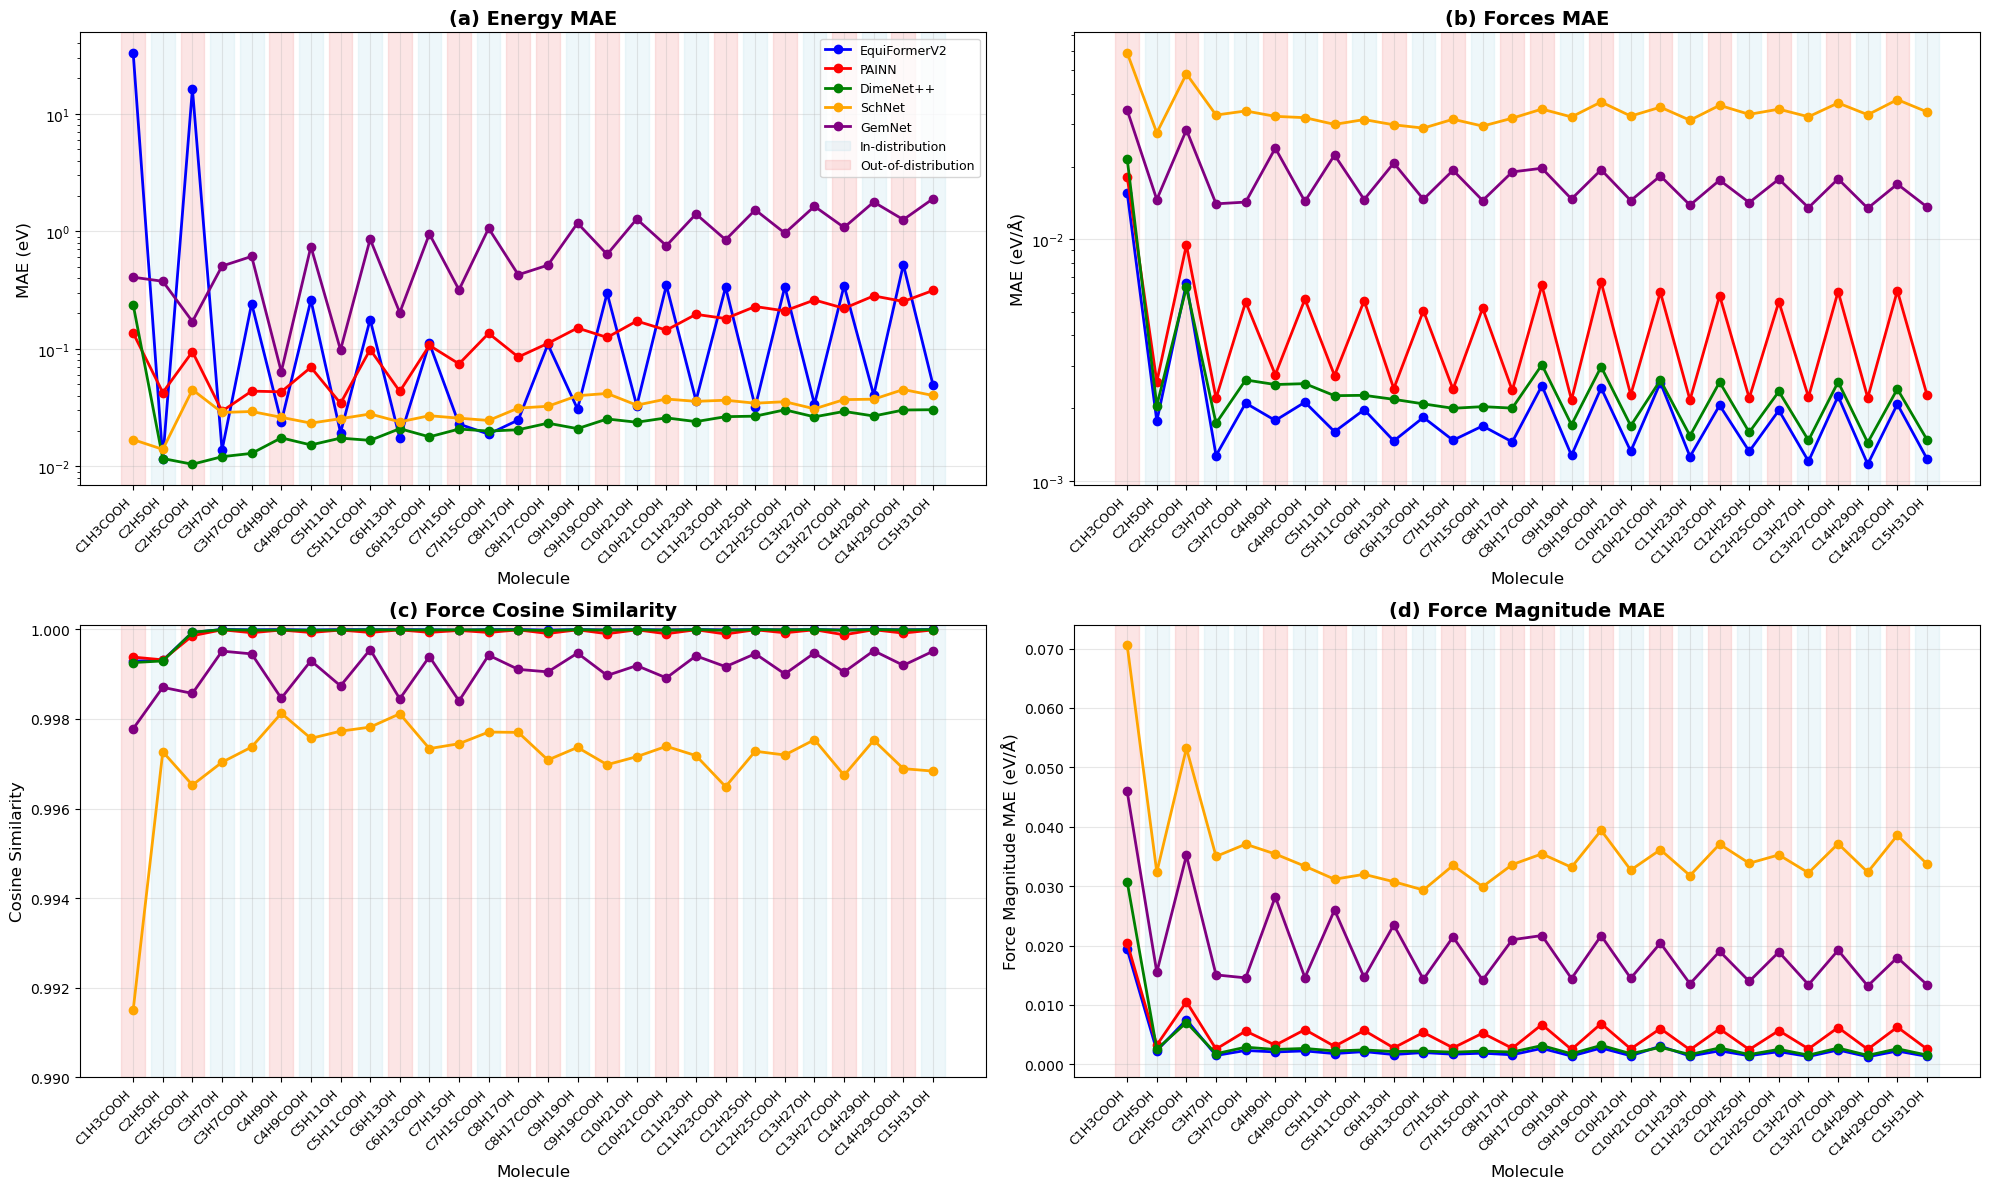

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import itertools
from typing import List

# Set up the figure with three subplots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 12))

# Define molecule names
alcohols: List[str] = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]
acids: List[str] = [f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)]

molecule_names: List[str] = list(itertools.chain.from_iterable(zip(acids, alcohols)))

# Define training indices based on your specification
# Training: carboxylic acids from C3H7COOH to C7H15COOH (indices 2,4,6,8,10 in molecule_names)
# Training: all alcohols except C4H9OH to C8H17OH (exclude indices 5,7,9,11,13 in molecule_names)
training_indices = []
test_indices = []

for i, molecule in enumerate(molecule_names):
    if 'COOH' in molecule:
        # Carboxylic acids
        carbon_count = int(molecule.split('H')[0][1:]) + 1  # +1 because COOH adds one carbon
        if 4 <= carbon_count <= 8:  # C3H7COOH to C7H15COOH corresponds to 4-8 total carbons
            training_indices.append(i)
        else:
            test_indices.append(i)
    else:
        # Alcohols
        carbon_count = int(molecule.split('H')[0][1:])
        if 4 <= carbon_count <= 8:  # C4H9OH to C8H17OH
            test_indices.append(i)
        else:
            training_indices.append(i)

# Add background highlighting for all subplots
for ax in [ax1, ax2, ax3, ax4]:
    # Highlight training regions in blue
    for idx in training_indices:
        ax.axvspan(idx-0.4, idx+0.4, alpha=0.2, color='lightblue')
    
    # Highlight test regions in red
    for idx in test_indices:
        ax.axvspan(idx-0.4, idx+0.4, alpha=0.2, color='lightcoral')

# Subplot 1: Energy MAE
for model in energy_df_updated['Model'].unique():
    model_data = energy_df_updated[energy_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(molecule_names))
        y_coords = model_data['MAE'].values
        ax1.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model], label=model)
ax1.set_xlabel('Molecule', fontsize=12)
ax1.set_ylabel('MAE (eV)', fontsize=12)
ax1.set_title('(a) Energy MAE', fontsize=14, fontweight='bold')
ax1.set_xticks(range(len(molecule_names)))
ax1.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=9)

# Subplot 2: Forces MAE
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(molecule_names))
        y_coords = model_data['MAE'].values
        ax2.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model])
ax2.set_xlabel('Molecule', fontsize=12)
ax2.set_ylabel('MAE (eV/Å)', fontsize=12)
ax2.set_title('(b) Forces MAE', fontsize=14, fontweight='bold')
ax2.set_xticks(range(len(molecule_names)))
ax2.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)

# Subplot 3: Cosine Similarity
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    x_coords = range(len(molecule_names))
    y_coords = model_data['Cosine_Similarity'].values
    ax3.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax3.set_xlabel('Molecule', fontsize=12)
ax3.set_ylabel('Cosine Similarity', fontsize=12)
ax3.set_title('(c) Force Cosine Similarity', fontsize=14, fontweight='bold')
ax3.set_xticks(range(len(molecule_names)))
ax3.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax3.set_ylim(0.99, 1.0001)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax3.grid(True, alpha=0.3)

# Subplot 4: Force Magnitude MAE
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    x_coords = range(len(molecule_names))
    y_coords = model_data['Magnitude_MAE'].values
    ax4.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax4.set_xlabel('Molecule', fontsize=12)
ax4.set_ylabel('Force Magnitude MAE (eV/Å)', fontsize=12)
ax4.set_title('(d) Force Magnitude MAE', fontsize=14, fontweight='bold')
ax4.set_xticks(range(len(molecule_names)))
ax4.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax4.grid(True, alpha=0.3)

# Add training/test indicators to legend
from matplotlib.patches import Patch
training_patch = Patch(color='lightblue', alpha=0.2, label='Training')
test_patch = Patch(color='lightcoral', alpha=0.2, label='Test')

# Get existing handles and labels, then add training/test patches
handles, labels = ax1.get_legend_handles_labels()
handles.extend([training_patch, test_patch])
labels.extend(['In-distribution', 'Out-of-distribution'])
ax1.legend(handles=handles, labels=labels, fontsize=9)

plt.tight_layout()
# Save to PDF with selectable text
plt.savefig('generalisation_checkpoints/cross_length_functionality/cross_length_functionality_figure_1.pdf', format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

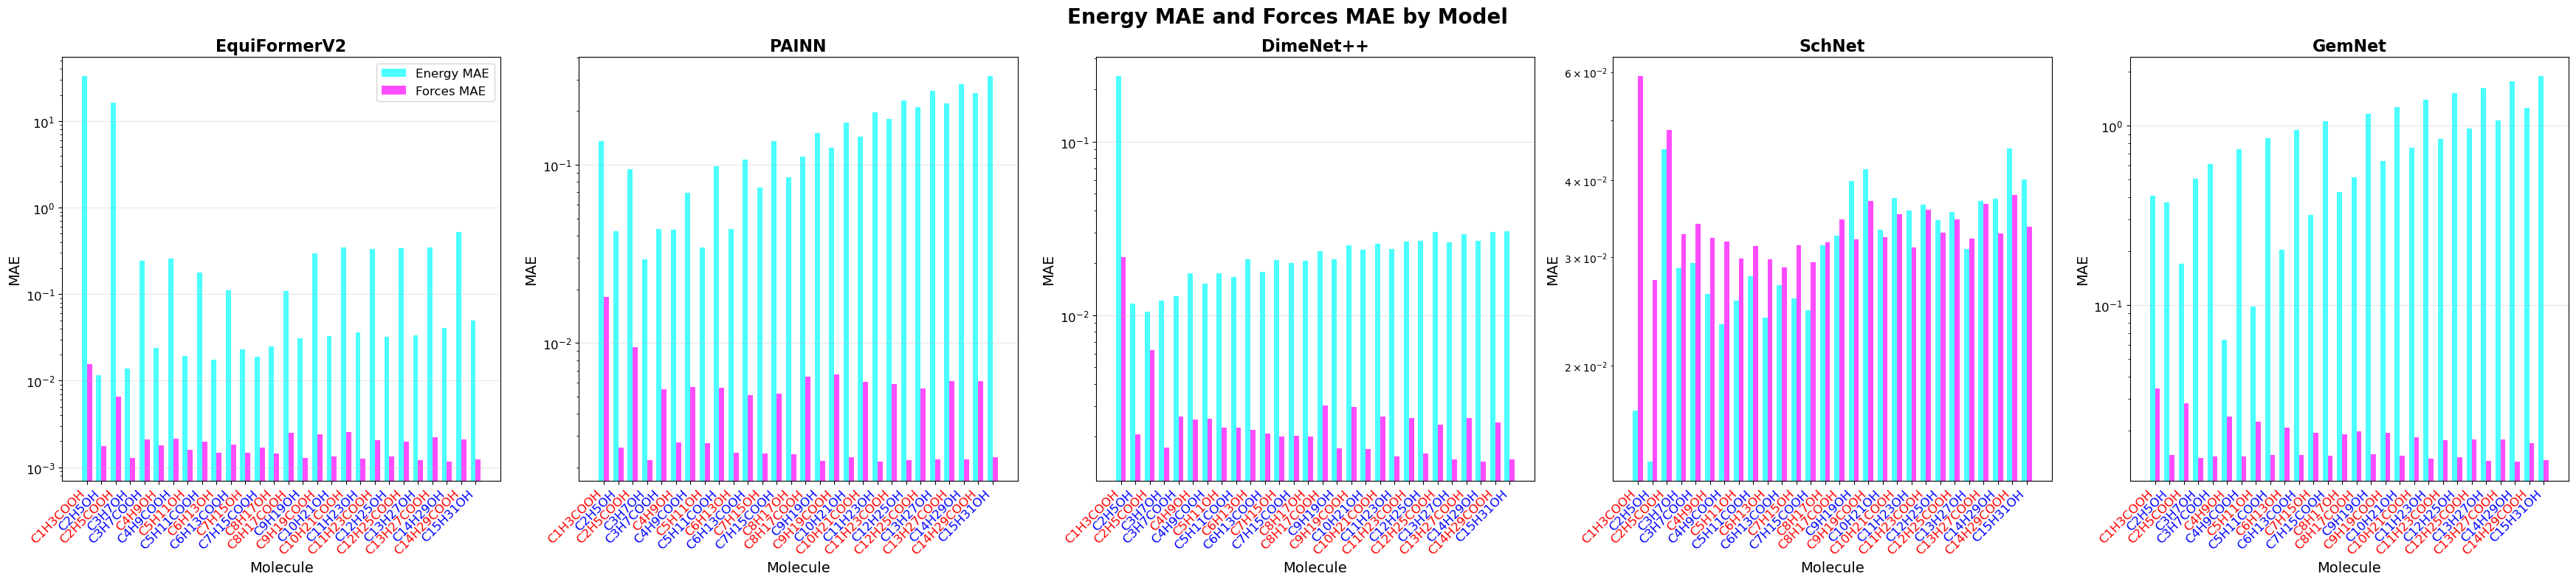

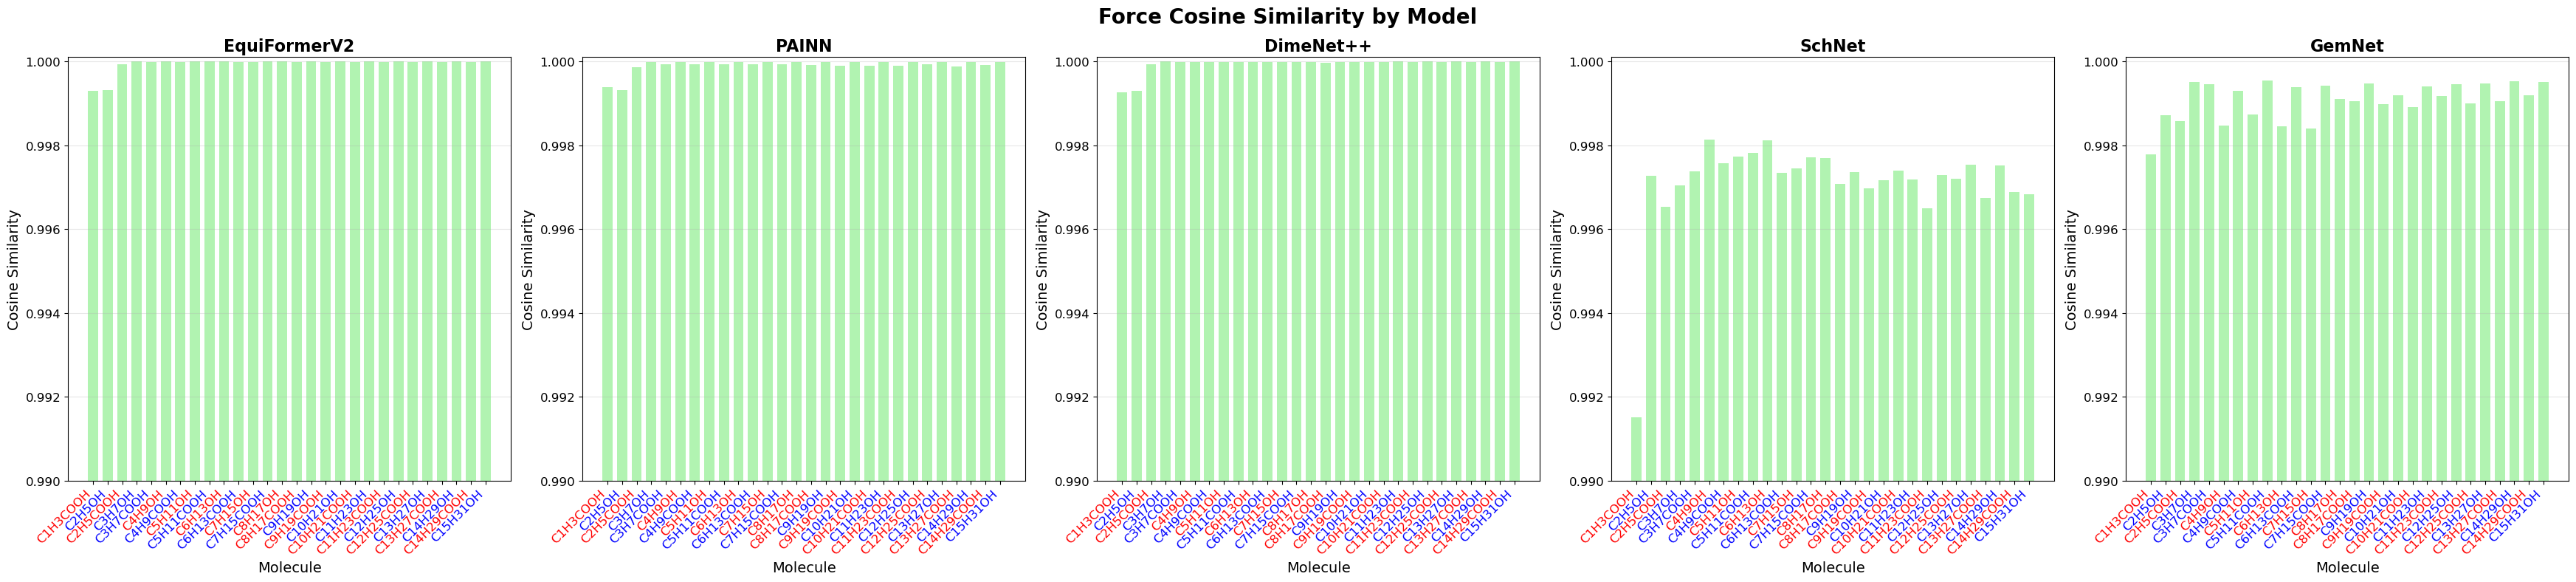

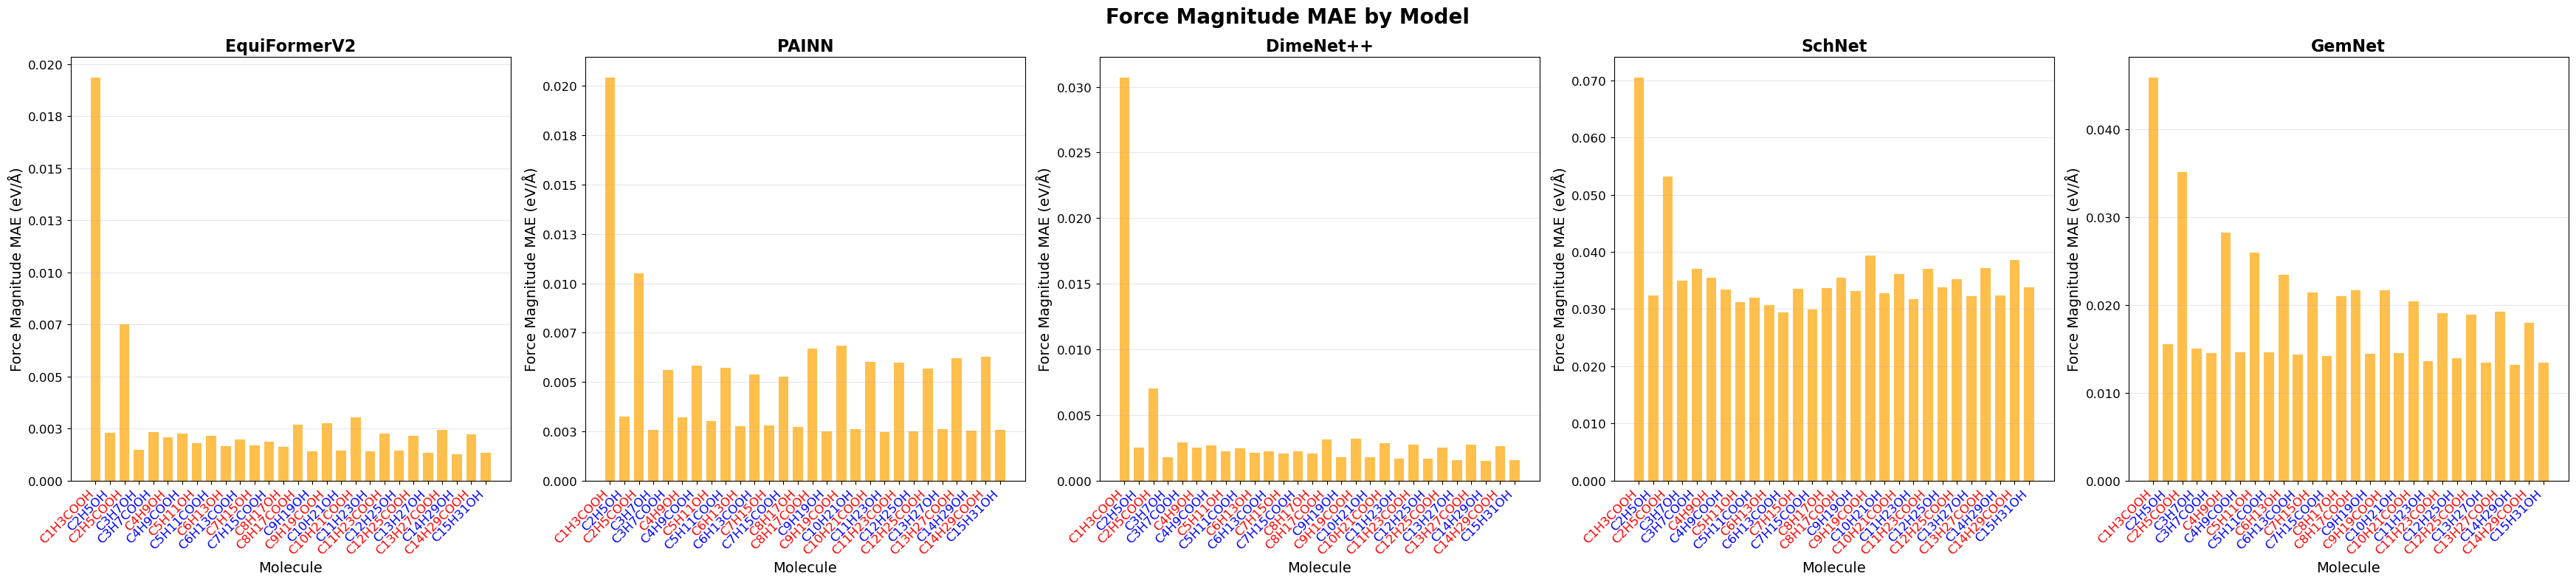

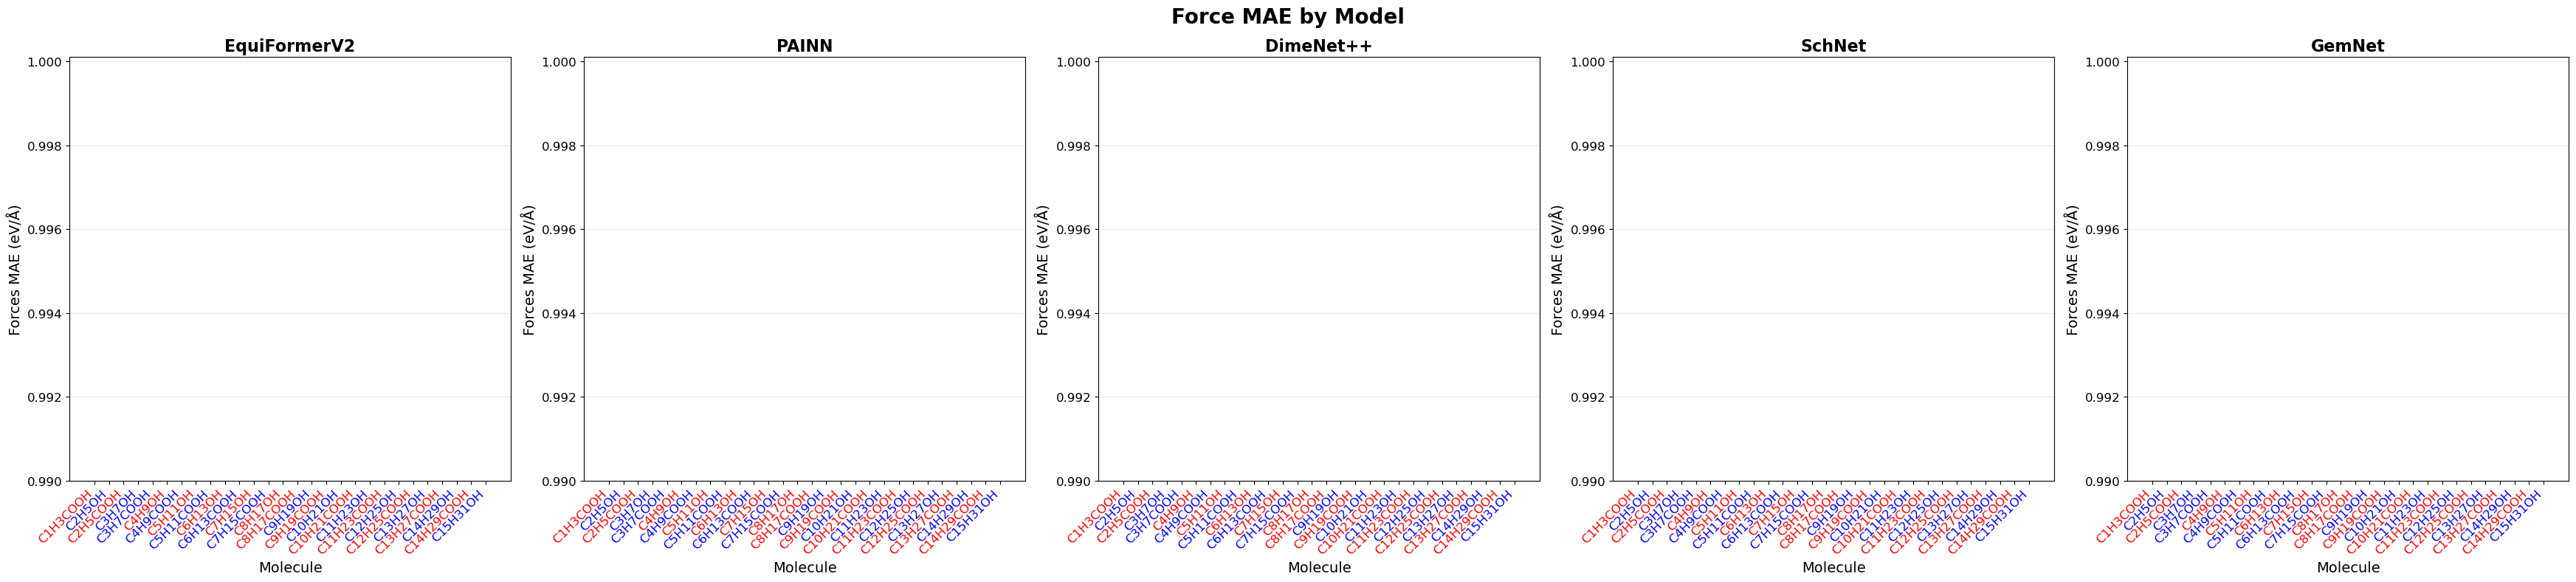

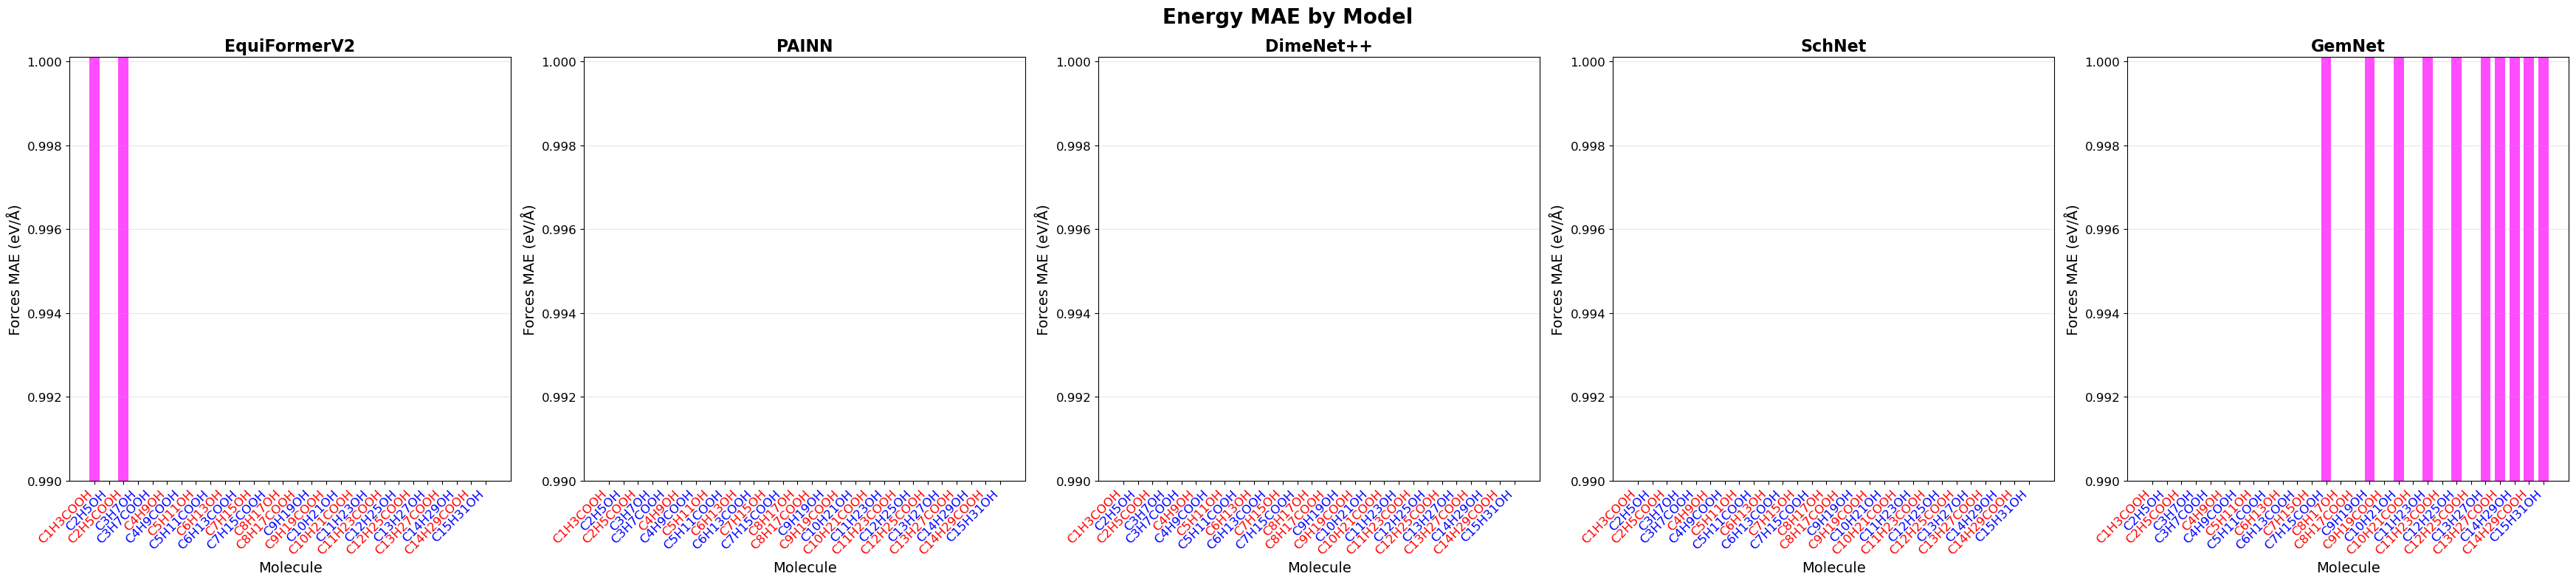

Legend:
Blue molecule names = In-distribution (training data)
Red molecule names = Out-of-distribution (test data)
Figure 1: Cyan bars = Energy MAE, Magenta bars = Forces MAE
Figure 2: Light green bars = Cosine Similarity
Figure 3: Orange bars = Force Magnitude MAE


In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import itertools
from typing import List

# Define molecule names
alcohols: List[str] = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]
acids: List[str] = [f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)]
molecule_names: List[str] = list(itertools.chain.from_iterable(zip(acids, alcohols)))

# Define training indices based on your specification
training_indices = []
test_indices = []

for i, molecule in enumerate(molecule_names):
    if 'COOH' in molecule:
        # Carboxylic acids
        carbon_count = int(molecule.split('H')[0][1:]) + 1  # +1 because COOH adds one carbon
        if 4 <= carbon_count <= 8:  # C3H7COOH to C7H15COOH corresponds to 4-8 total carbons
            training_indices.append(i)
        else:
            test_indices.append(i)
    else:
        # Alcohols
        carbon_count = int(molecule.split('H')[0][1:])
        if 4 <= carbon_count <= 8:  # C4H9OH to C8H17OH
            test_indices.append(i)
        else:
            training_indices.append(i)

# Get unique models
models = list(energy_df_updated['Model'].unique())
n_molecules = len(molecule_names)
bar_width = 0.35
x = np.arange(n_molecules)

# Define colors for molecule names based on distribution
def get_molecule_name_colors():
    return ['blue' if idx in training_indices else 'red' for idx in range(n_molecules)]

# FIGURE 1: Energy MAE and Forces MAE
fig1, axes1 = plt.subplots(1, 5, figsize=(35, 8))
fig1.suptitle('Energy MAE and Forces MAE by Model', fontsize=20, fontweight='bold')

for i, model in enumerate(models):
    ax = axes1[i]
    
    # Get data for this model
    energy_data = energy_df_updated[energy_df_updated['Model'] == model]['MAE'].values
    forces_data = forces_df_updated[forces_df_updated['Model'] == model]['MAE'].values
    
    # Create bars
    bars1 = ax.bar(x - bar_width/2, energy_data, bar_width, label='Energy MAE', color='cyan', alpha=0.7)
    bars2 = ax.bar(x + bar_width/2, forces_data, bar_width, label='Forces MAE', color='magenta', alpha=0.7)
    
    # Set labels and title
    ax.set_xlabel('Molecule', fontsize=14)
    ax.set_ylabel('MAE', fontsize=14)
    ax.set_title(f'{model}', fontsize=16, fontweight='bold')
    ax.set_xticks(x)
    
    # Set molecule names with colors based on distribution
    molecule_colors = get_molecule_name_colors()
    ax.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=10)
    
    # Color the x-axis labels
    for j, (tick_label, color) in enumerate(zip(ax.get_xticklabels(), molecule_colors)):
        tick_label.set_color(color)
    
    ax.set_yscale('log')
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(axis='both', which='major', labelsize=12)
    
    # Add legend only to the first subplot
    if i == 0:
        ax.legend(fontsize=12, loc='upper right')

plt.tight_layout()
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_1_energy_forces_mae.pdf', 
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

# FIGURE 2: Cosine Similarity
fig2, axes2 = plt.subplots(1, 5, figsize=(35, 8))
fig2.suptitle('Force Cosine Similarity by Model', fontsize=20, fontweight='bold')

for i, model in enumerate(models):
    ax = axes2[i]
    
    # Get data for this model
    cosine_data = forces_df_updated[forces_df_updated['Model'] == model]['Cosine_Similarity'].values
    
    # Create bars
    bars = ax.bar(x, cosine_data, bar_width*2, color='lightgreen', alpha=0.7)
    
    # Set labels and title
    ax.set_xlabel('Molecule', fontsize=14)
    ax.set_ylabel('Cosine Similarity', fontsize=14)
    ax.set_title(f'{model}', fontsize=16, fontweight='bold')
    ax.set_xticks(x)
    
    # Set molecule names with colors based on distribution
    molecule_colors = get_molecule_name_colors()
    ax.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=10)
    
    # Color the x-axis labels
    for j, (tick_label, color) in enumerate(zip(ax.get_xticklabels(), molecule_colors)):
        tick_label.set_color(color)
    
    ax.set_ylim(0.99, 1.0001)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_2_cosine_similarity.pdf', 
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

# FIGURE 3: Force Magnitude MAE
fig3, axes3 = plt.subplots(1, 5, figsize=(35, 8))
fig3.suptitle('Force Magnitude MAE by Model', fontsize=20, fontweight='bold')

for i, model in enumerate(models):
    ax = axes3[i]
    
    # Get data for this model
    magnitude_data = forces_df_updated[forces_df_updated['Model'] == model]['Magnitude_MAE'].values
    
    # Create bars
    bars = ax.bar(x, magnitude_data, bar_width*2, color='orange', alpha=0.7)
    
    # Set labels and title
    ax.set_xlabel('Molecule', fontsize=14)
    ax.set_ylabel('Force Magnitude MAE (eV/Å)', fontsize=14)
    ax.set_title(f'{model}', fontsize=16, fontweight='bold')
    ax.set_xticks(x)
    
    # Set molecule names with colors based on distribution
    molecule_colors = get_molecule_name_colors()
    ax.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=10)
    
    # Color the x-axis labels
    for j, (tick_label, color) in enumerate(zip(ax.get_xticklabels(), molecule_colors)):
        tick_label.set_color(color)
    
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_3_force_magnitude_mae.pdf', 
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

# FIGURE 4: Forces MAE
fig4, axes4 = plt.subplots(1, 5, figsize=(35, 8))
fig4.suptitle('Force MAE by Model', fontsize=20, fontweight='bold')

for i, model in enumerate(models):
    ax = axes4[i]
    
    # Get data for this model
    cosine_data = forces_df_updated[forces_df_updated['Model'] == model]['MAE'].values
    
    # Create bars
    bars = ax.bar(x, cosine_data, bar_width*2, color='cyan', alpha=0.7)
    
    # Set labels and title
    ax.set_xlabel('Molecule', fontsize=14)
    ax.set_ylabel('Forces MAE (eV/Å)', fontsize=14)
    ax.set_title(f'{model}', fontsize=16, fontweight='bold')
    ax.set_xticks(x)
    
    # Set molecule names with colors based on distribution
    molecule_colors = get_molecule_name_colors()
    ax.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=10)
    
    # Color the x-axis labels
    for j, (tick_label, color) in enumerate(zip(ax.get_xticklabels(), molecule_colors)):
        tick_label.set_color(color)
    
    ax.set_ylim(0.99, 1.0001)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_4_forces_mae.pdf', 
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()


# FIGURE 5: Energy MAE
fig5, axes5 = plt.subplots(1, 5, figsize=(35, 8))
fig5.suptitle('Energy MAE by Model', fontsize=20, fontweight='bold')

for i, model in enumerate(models):
    ax = axes5[i]
    
    # Get data for this model
    cosine_data = energy_df_updated[energy_df_updated['Model'] == model]['MAE'].values

    # Create bars
    bars = ax.bar(x, cosine_data, bar_width*2, color='magenta', alpha=0.7)
    
    # Set labels and title
    ax.set_xlabel('Molecule', fontsize=14)
    ax.set_ylabel('Forces MAE (eV/Å)', fontsize=14)
    ax.set_title(f'{model}', fontsize=16, fontweight='bold')
    ax.set_xticks(x)
    
    # Set molecule names with colors based on distribution
    molecule_colors = get_molecule_name_colors()
    ax.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=10)
    
    # Color the x-axis labels
    for j, (tick_label, color) in enumerate(zip(ax.get_xticklabels(), molecule_colors)):
        tick_label.set_color(color)
    
    ax.set_ylim(0.99, 1.0001)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_5_energy_mae.pdf', 
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()


# Add distribution legend explanation
print("Legend:")
print("Blue molecule names = In-distribution (training data)")
print("Red molecule names = Out-of-distribution (test data)")
print("Figure 1: Cyan bars = Energy MAE, Magenta bars = Forces MAE")
print("Figure 2: Light green bars = Cosine Similarity")
print("Figure 3: Orange bars = Force Magnitude MAE")

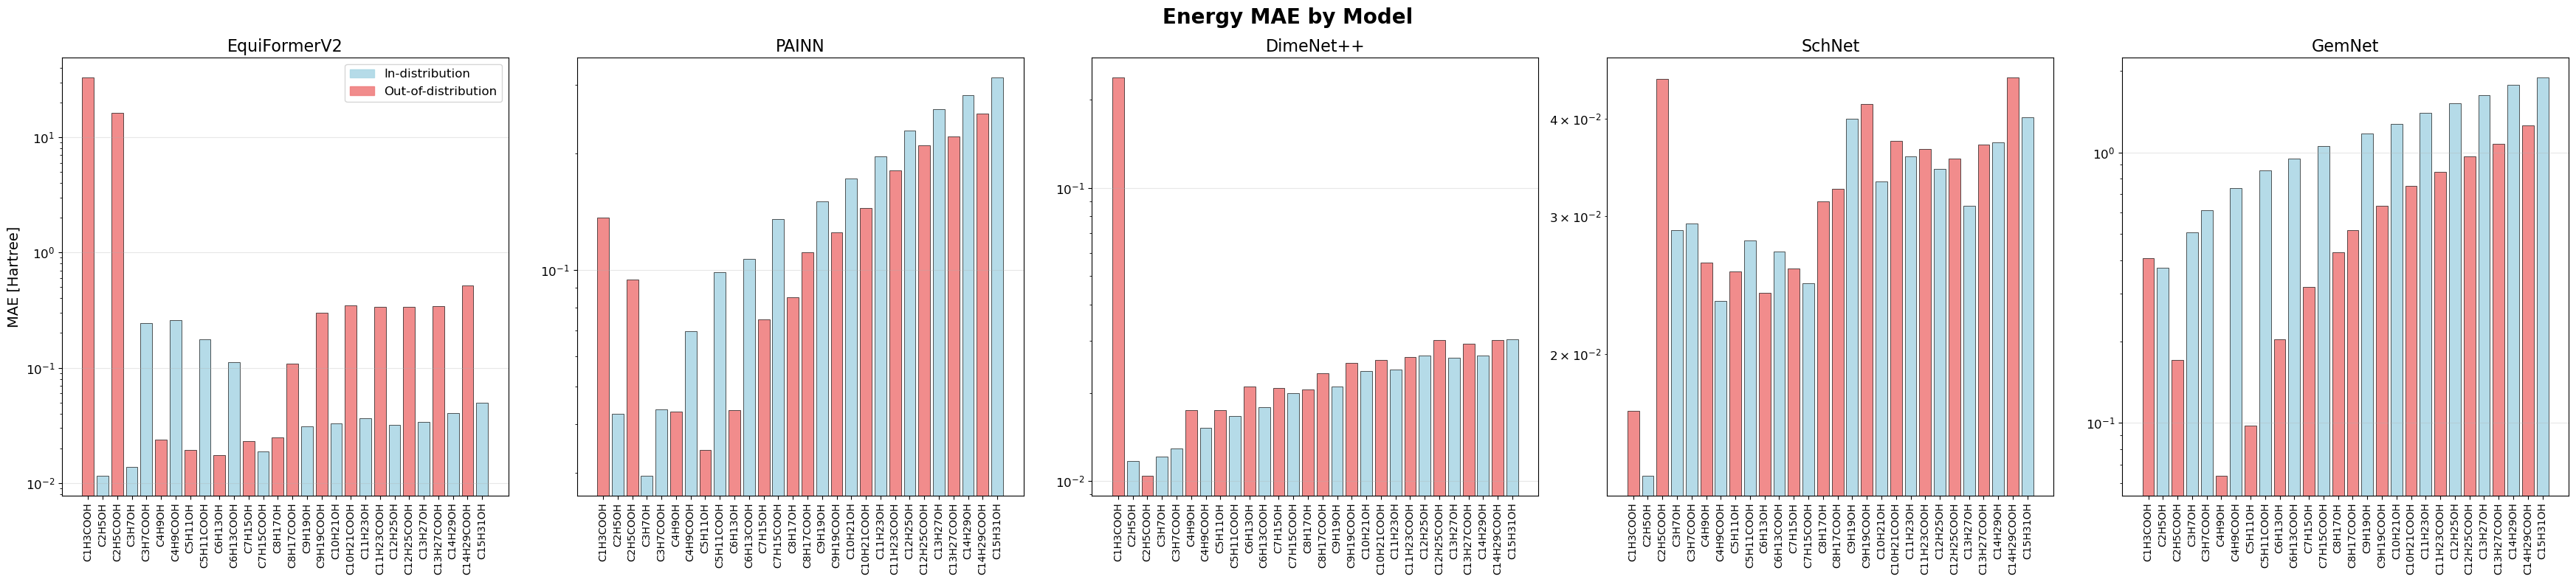

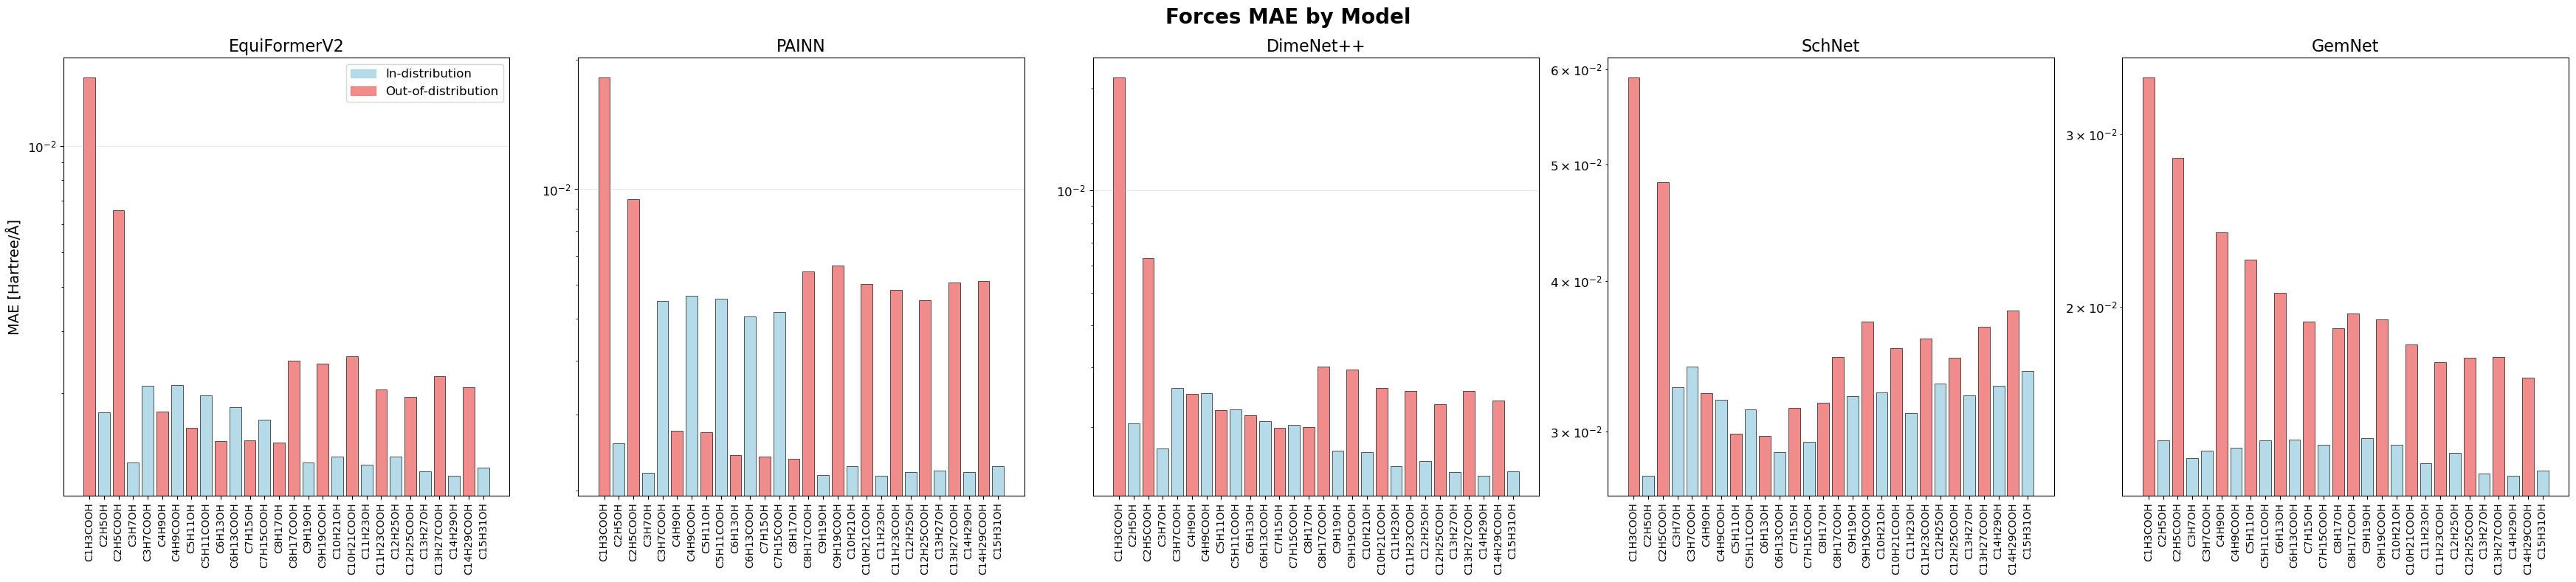

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Academic style fonts
# plt.rcParams.update({
#     "font.family": "serif",
#     "font.serif": ["Times New Roman"],
#     "axes.labelsize": 14,
#     "axes.titlesize": 16,
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 12,
#     "legend.fontsize": 12,
# })

# Softer academic-friendly colors
train_color = "lightblue"#"#CB9D4B"  # muted blue
test_color = "lightcoral"#"#12CA3D"   # muted green

def get_bar_colors():
    return [train_color if idx in training_indices else test_color for idx in range(n_molecules)]

bar_colors = get_bar_colors()


# ---------------- FIGURE 1: Energy MAE ----------------
fig_energy, axes_energy = plt.subplots(1, len(models), figsize=(35, 8))
fig_energy.suptitle('Energy MAE by Model', fontsize=20, fontweight='bold')

if len(models) == 1:
    axes_energy = [axes_energy]

for i, model in enumerate(models):
    ax = axes_energy[i]
    energy_data = energy_df_updated[energy_df_updated['Model'] == model]['MAE'].values
    
    ax.bar(x, energy_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    
    ax.set_title(f'{model}')
    ax.set_xticks(x)
    ax.set_xticklabels(molecule_names, rotation=90)
    ax.set_yscale('log')
    ax.grid(True, alpha=0.3, axis='y')
    
    if i == 0:
        ax.set_ylabel('MAE [eV]')
        handles = [
            plt.Rectangle((0,0),1,1,color=train_color,alpha=0.9,label="In-distribution"),
            plt.Rectangle((0,0),1,1,color=test_color,alpha=0.9,label="Out-of-distribution")
        ]
        ax.legend(handles=handles, loc='upper right')
    else:
        ax.set_ylabel('')

plt.tight_layout()
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_energy_mae.pdf',
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()


# ---------------- FIGURE 2: Forces MAE ----------------
fig_forces, axes_forces = plt.subplots(1, len(models), figsize=(35, 8))
fig_forces.suptitle('Forces MAE by Model', fontsize=20, fontweight='bold')

if len(models) == 1:
    axes_forces = [axes_forces]

for i, model in enumerate(models):
    ax = axes_forces[i]
    forces_data = forces_df_updated[forces_df_updated['Model'] == model]['MAE'].values
    
    ax.bar(x, forces_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    
    ax.set_title(f'{model}')
    ax.set_xticks(x)
    ax.set_xticklabels(molecule_names, rotation=90)
    ax.set_yscale('log')
    ax.grid(True, alpha=0.3, axis='y')
    
    # Only first subplot gets ylabel
    if i == 0:
        ax.set_ylabel('MAE [eV/Å]')
        handles = [
            plt.Rectangle((0,0),1,1,color=train_color,alpha=0.9,label="In-distribution"),
            plt.Rectangle((0,0),1,1,color=test_color,alpha=0.9,label="Out-of-distribution")
        ]
        ax.legend(handles=handles, loc='upper right')
    else:
        ax.set_ylabel('')

plt.tight_layout()
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_forces_mae.pdf',
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()


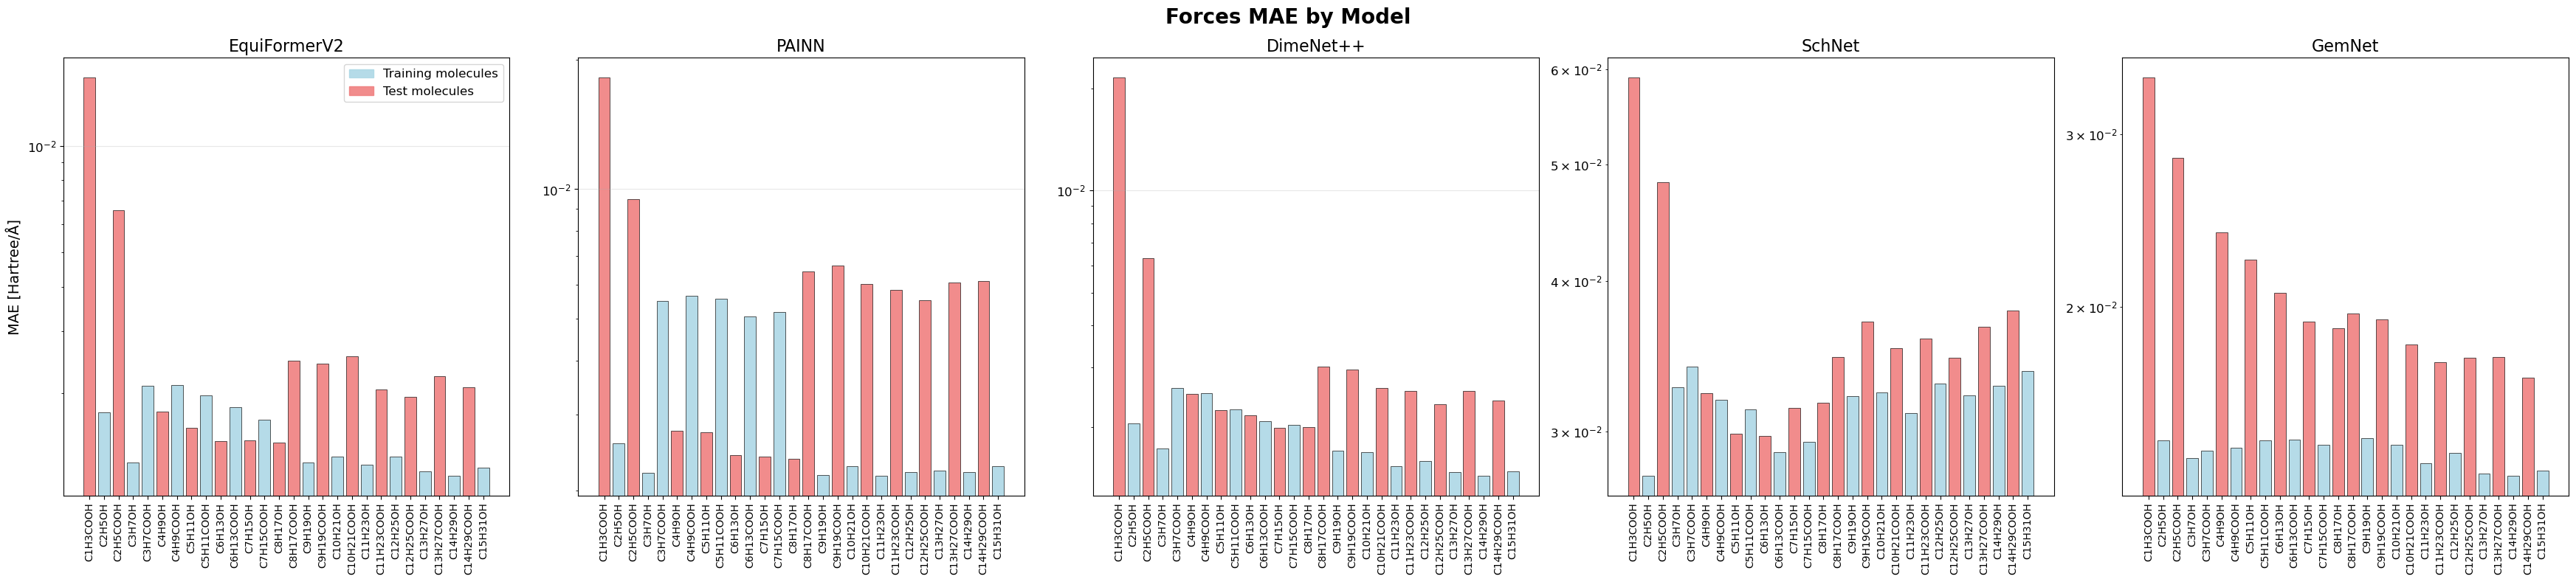

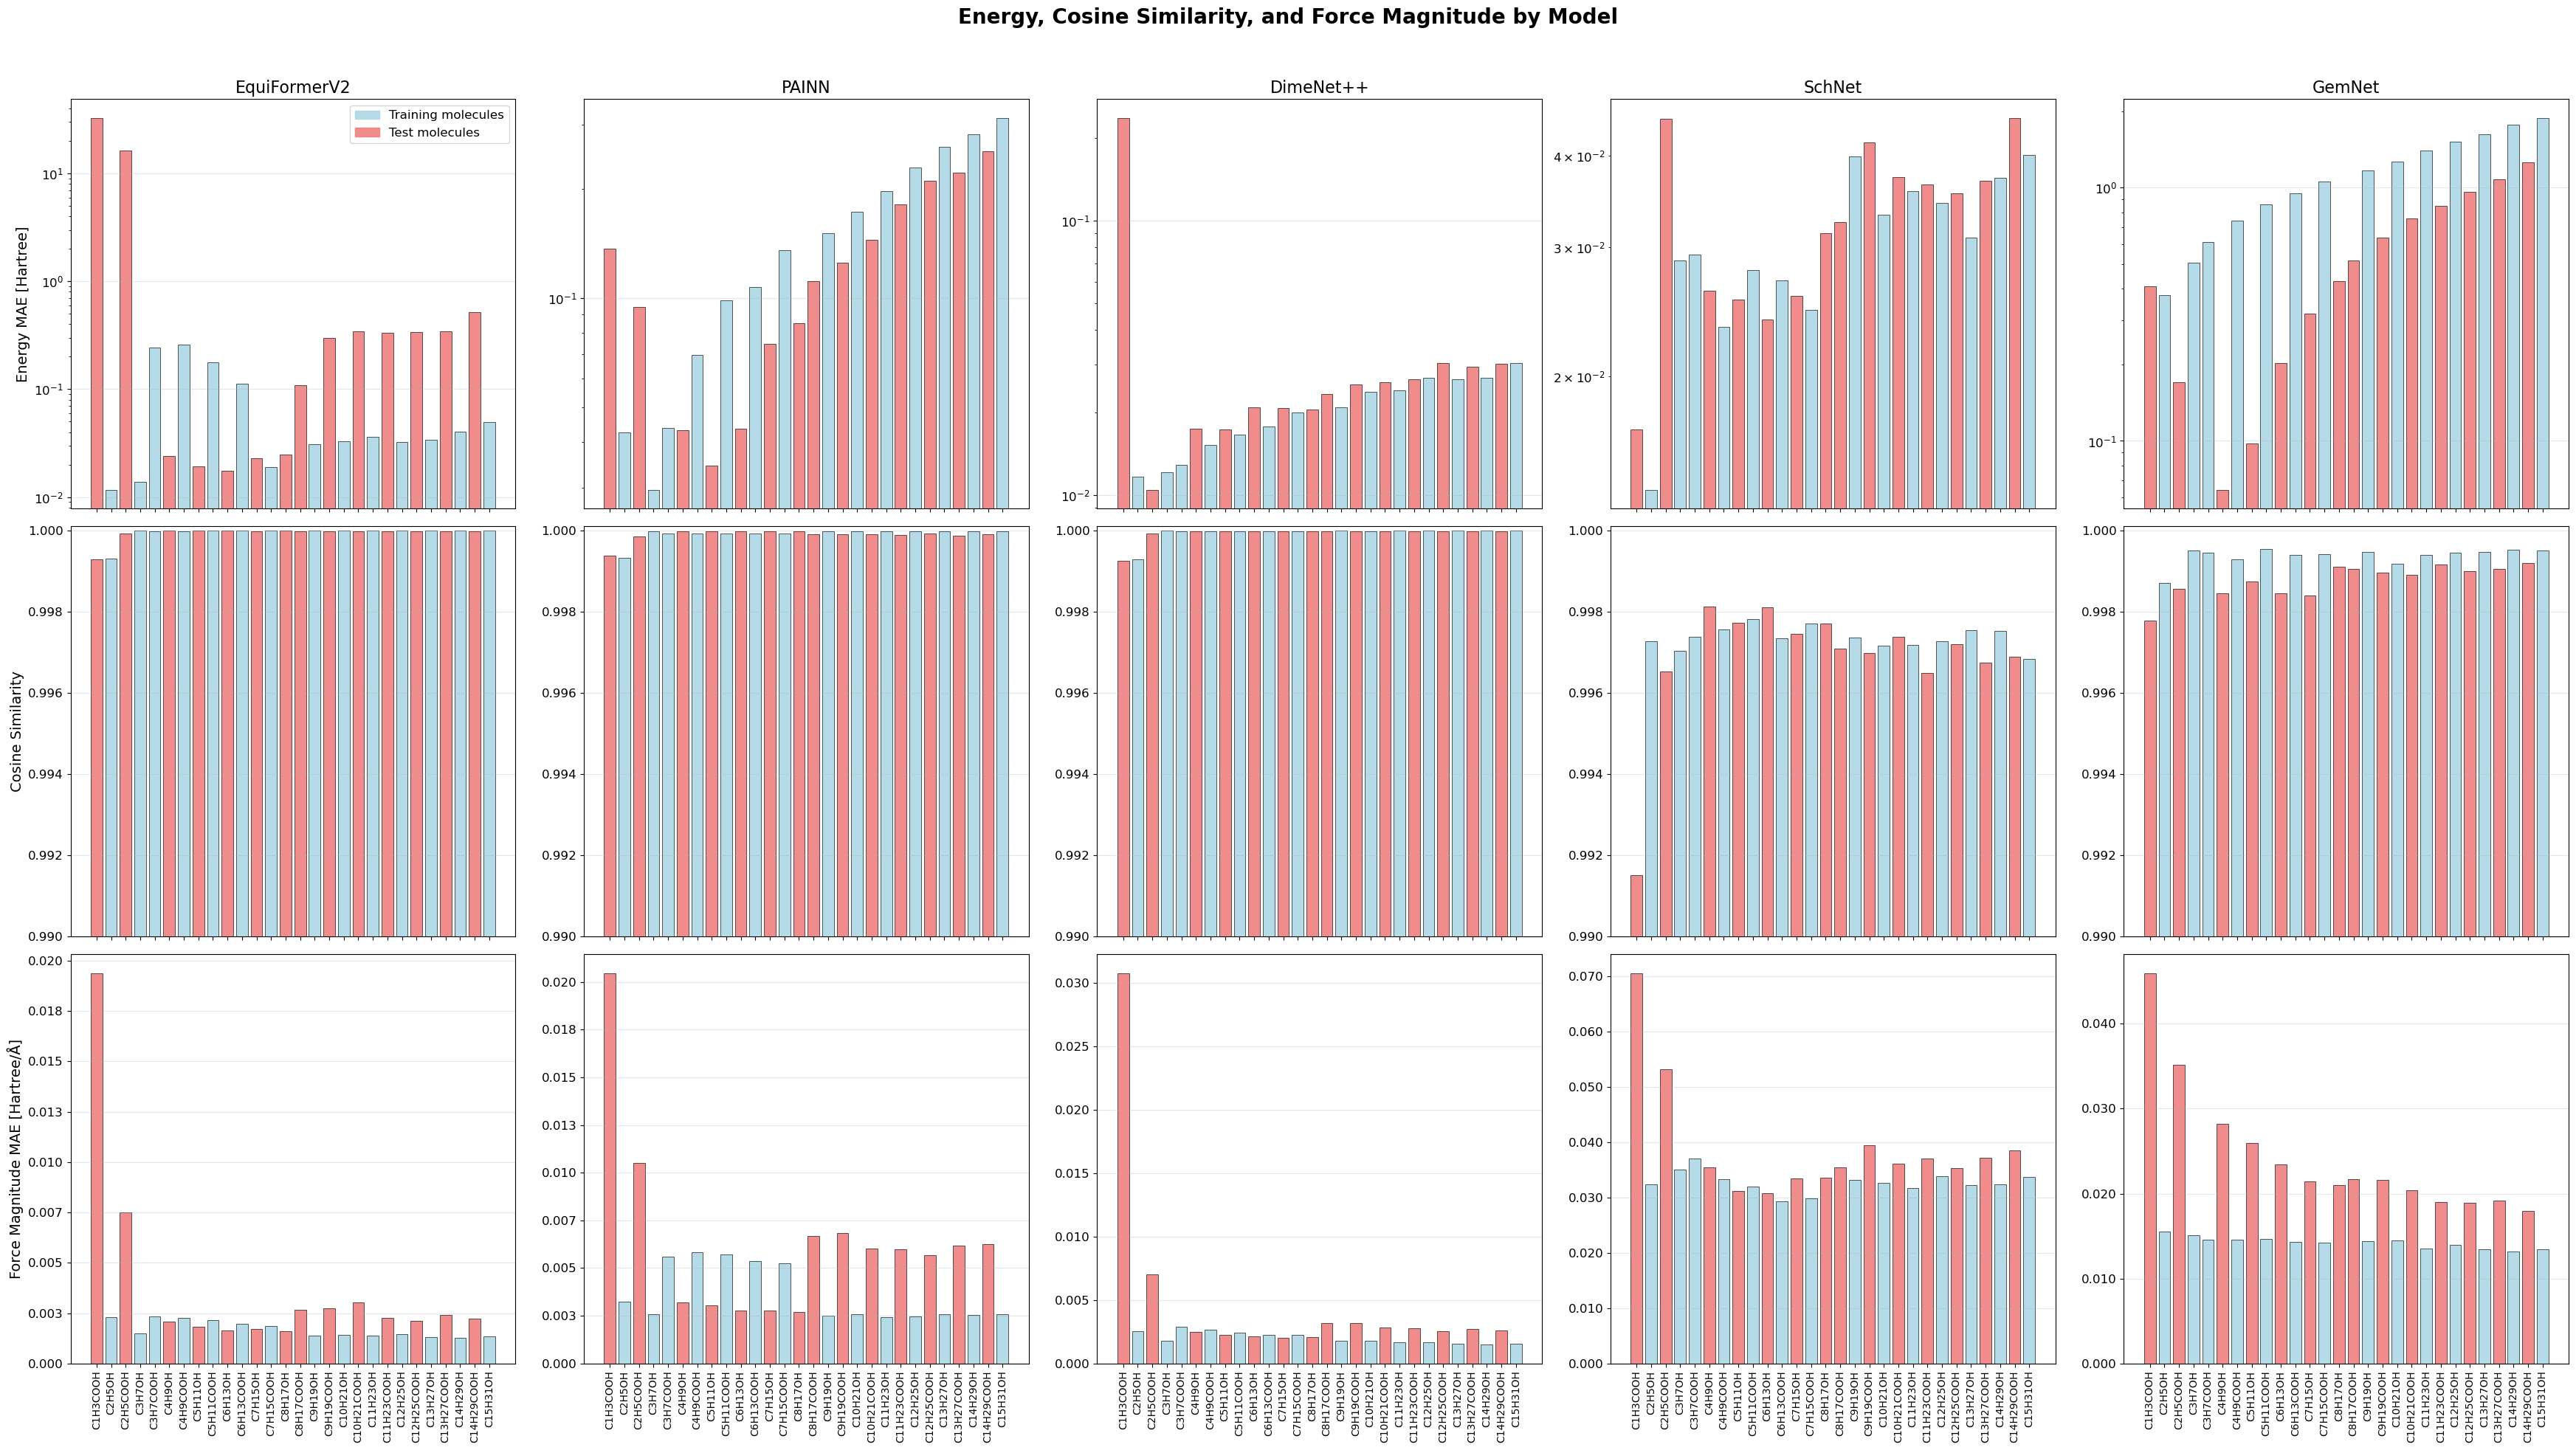

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Academic style
# plt.rcParams.update({
#     "font.family": "serif",
#     "font.serif": ["Times New Roman"],
#     "axes.labelsize": 14,
#     "axes.titlesize": 16,
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 12,
#     "legend.fontsize": 12,
# })

# Colors (use your chosen smooth train/test colors)
train_color = "lightblue"
test_color = "lightcoral"

def get_bar_colors():
    return [train_color if idx in training_indices else test_color for idx in range(n_molecules)]

bar_colors = get_bar_colors()


# ---------------- FIGURE 1: Forces MAE (Main paper) ----------------
fig_forces, axes_forces = plt.subplots(1, len(models), figsize=(35, 8))
fig_forces.suptitle('Forces MAE by Model', fontsize=20, fontweight='bold')

# ensure iterable when len(models)==1
if len(models) == 1:
    axes_forces = [axes_forces]

for i, model in enumerate(models):
    ax = axes_forces[i]
    forces_data = forces_df_updated[forces_df_updated['Model'] == model]['MAE'].values
    
    ax.bar(x, forces_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_title(f'{model}')
    ax.set_xticks(x)
    ax.set_xticklabels(molecule_names, rotation=90)
    ax.set_yscale('log')
    ax.grid(True, alpha=0.3, axis='y')
    
    if i == 0:
        ax.set_ylabel('MAE [eV/Å]')
        handles = [
            plt.Rectangle((0,0),1,1,color=train_color,alpha=0.9,label="Training molecules"),
            plt.Rectangle((0,0),1,1,color=test_color,alpha=0.9,label="Test molecules")
        ]
        ax.legend(handles=handles, loc='upper right')
    else:
        ax.set_ylabel('')

plt.tight_layout()
plt.savefig('generalisation_checkpoints/cross_length_functionality/cross_length_functionality_forces_mae.pdf',
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()



# ---------------- FIGURE 2: Appendix (Energy, Cosine, Magnitude) ----------------
fig, axes = plt.subplots(3, len(models), figsize=(35, 20), sharex='col')

# handle single-model case
if len(models) == 1:
    axes = axes.reshape(3, 1)

# --- Energy MAE (uses train/test colors) ---
for i, model in enumerate(models):
    ax = axes[0, i]
    energy_data = energy_df_updated[energy_df_updated['Model'] == model]['MAE'].values
    ax.bar(x, energy_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_title(f'{model}')
    ax.set_yscale('log')
    ax.grid(True, alpha=0.3, axis='y')
    if i == 0:
        ax.set_ylabel('Energy MAE [eV]')
        # add legend once in top-left
        handles = [
            plt.Rectangle((0,0),1,1,color=train_color,alpha=0.9,label="Training molecules"),
            plt.Rectangle((0,0),1,1,color=test_color,alpha=0.9,label="Test molecules")
        ]
        ax.legend(handles=handles, loc='upper right')
    else:
        ax.set_ylabel('')

# --- Cosine Similarity (now uses train/test colors) ---
for i, model in enumerate(models):
    ax = axes[1, i]
    cosine_data = forces_df_updated[forces_df_updated['Model'] == model]['Cosine_Similarity'].values
    # use train/test coloring per molecule
    ax.bar(x, cosine_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_ylim(0.99, 1.0001)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, pos: f'{val:.3f}'))
    ax.grid(True, alpha=0.3, axis='y')
    if i == 0:
        ax.set_ylabel('Cosine Similarity')
    else:
        ax.set_ylabel('')

# --- Force Magnitude MAE (now uses train/test colors) ---
for i, model in enumerate(models):
    ax = axes[2, i]
    magnitude_data = forces_df_updated[forces_df_updated['Model'] == model]['Magnitude_MAE'].values
    # use train/test coloring per molecule
    ax.bar(x, magnitude_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, pos: f'{val:.3f}'))
    ax.grid(True, alpha=0.3, axis='y')
    if i == 0:
        ax.set_ylabel('Force Magnitude MAE [eV/Å]')
    else:
        ax.set_ylabel('')

# Put X labels only on the bottom row (last row)
for i in range(len(models)):
    ax = axes[2, i]
    ax.set_xticks(x)
    ax.set_xticklabels(molecule_names, rotation=90)

fig.suptitle("Energy, Cosine Similarity, and Force Magnitude by Model", fontsize=20, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('generalisation_checkpoints/cross_length_functionality/cross_length_functionality_appendix_energy_cosine_magnitude.pdf',
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()


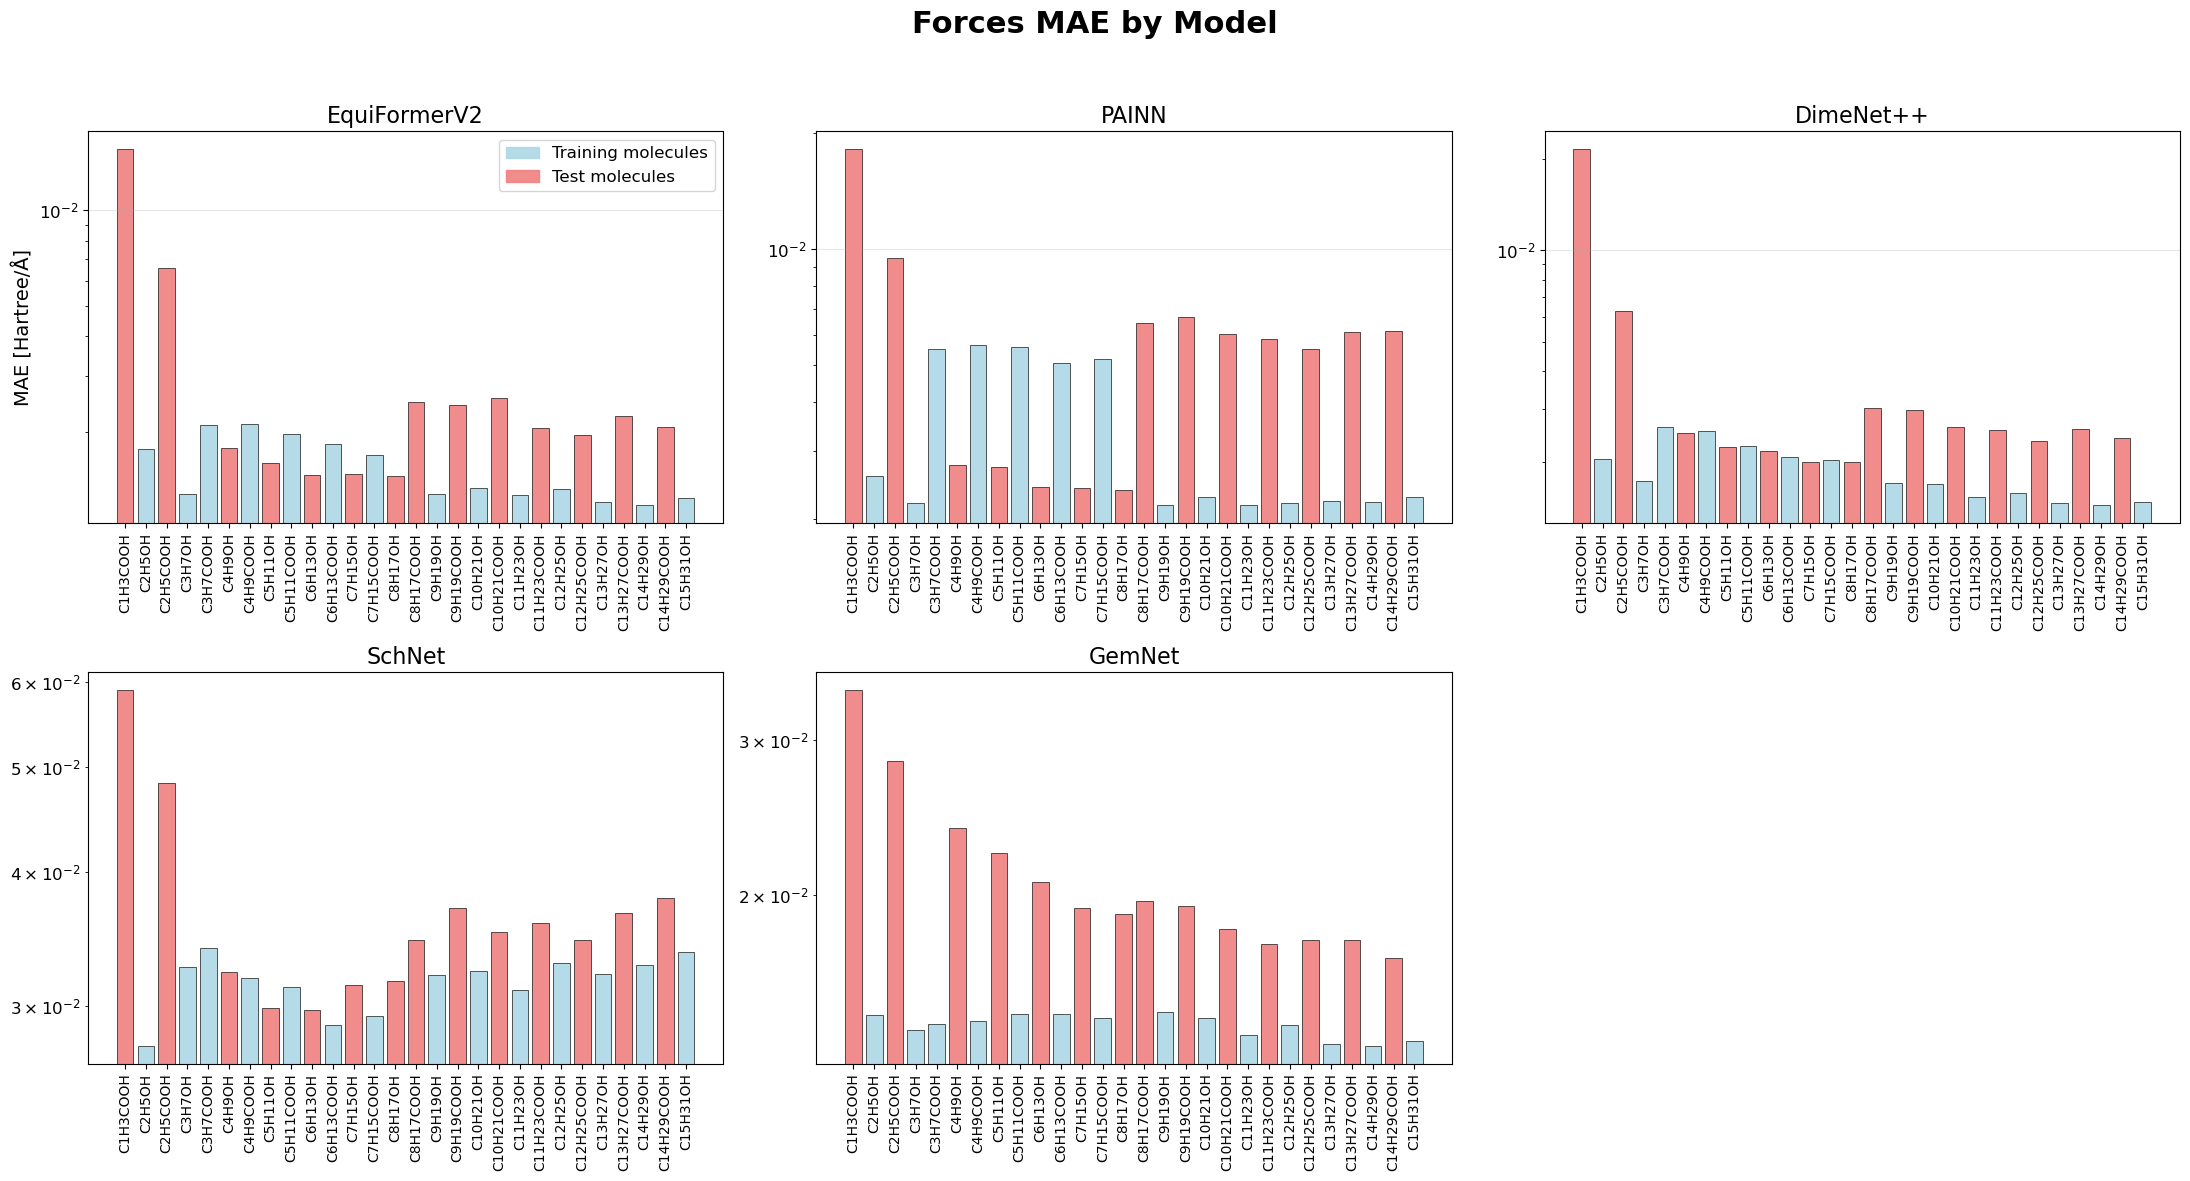

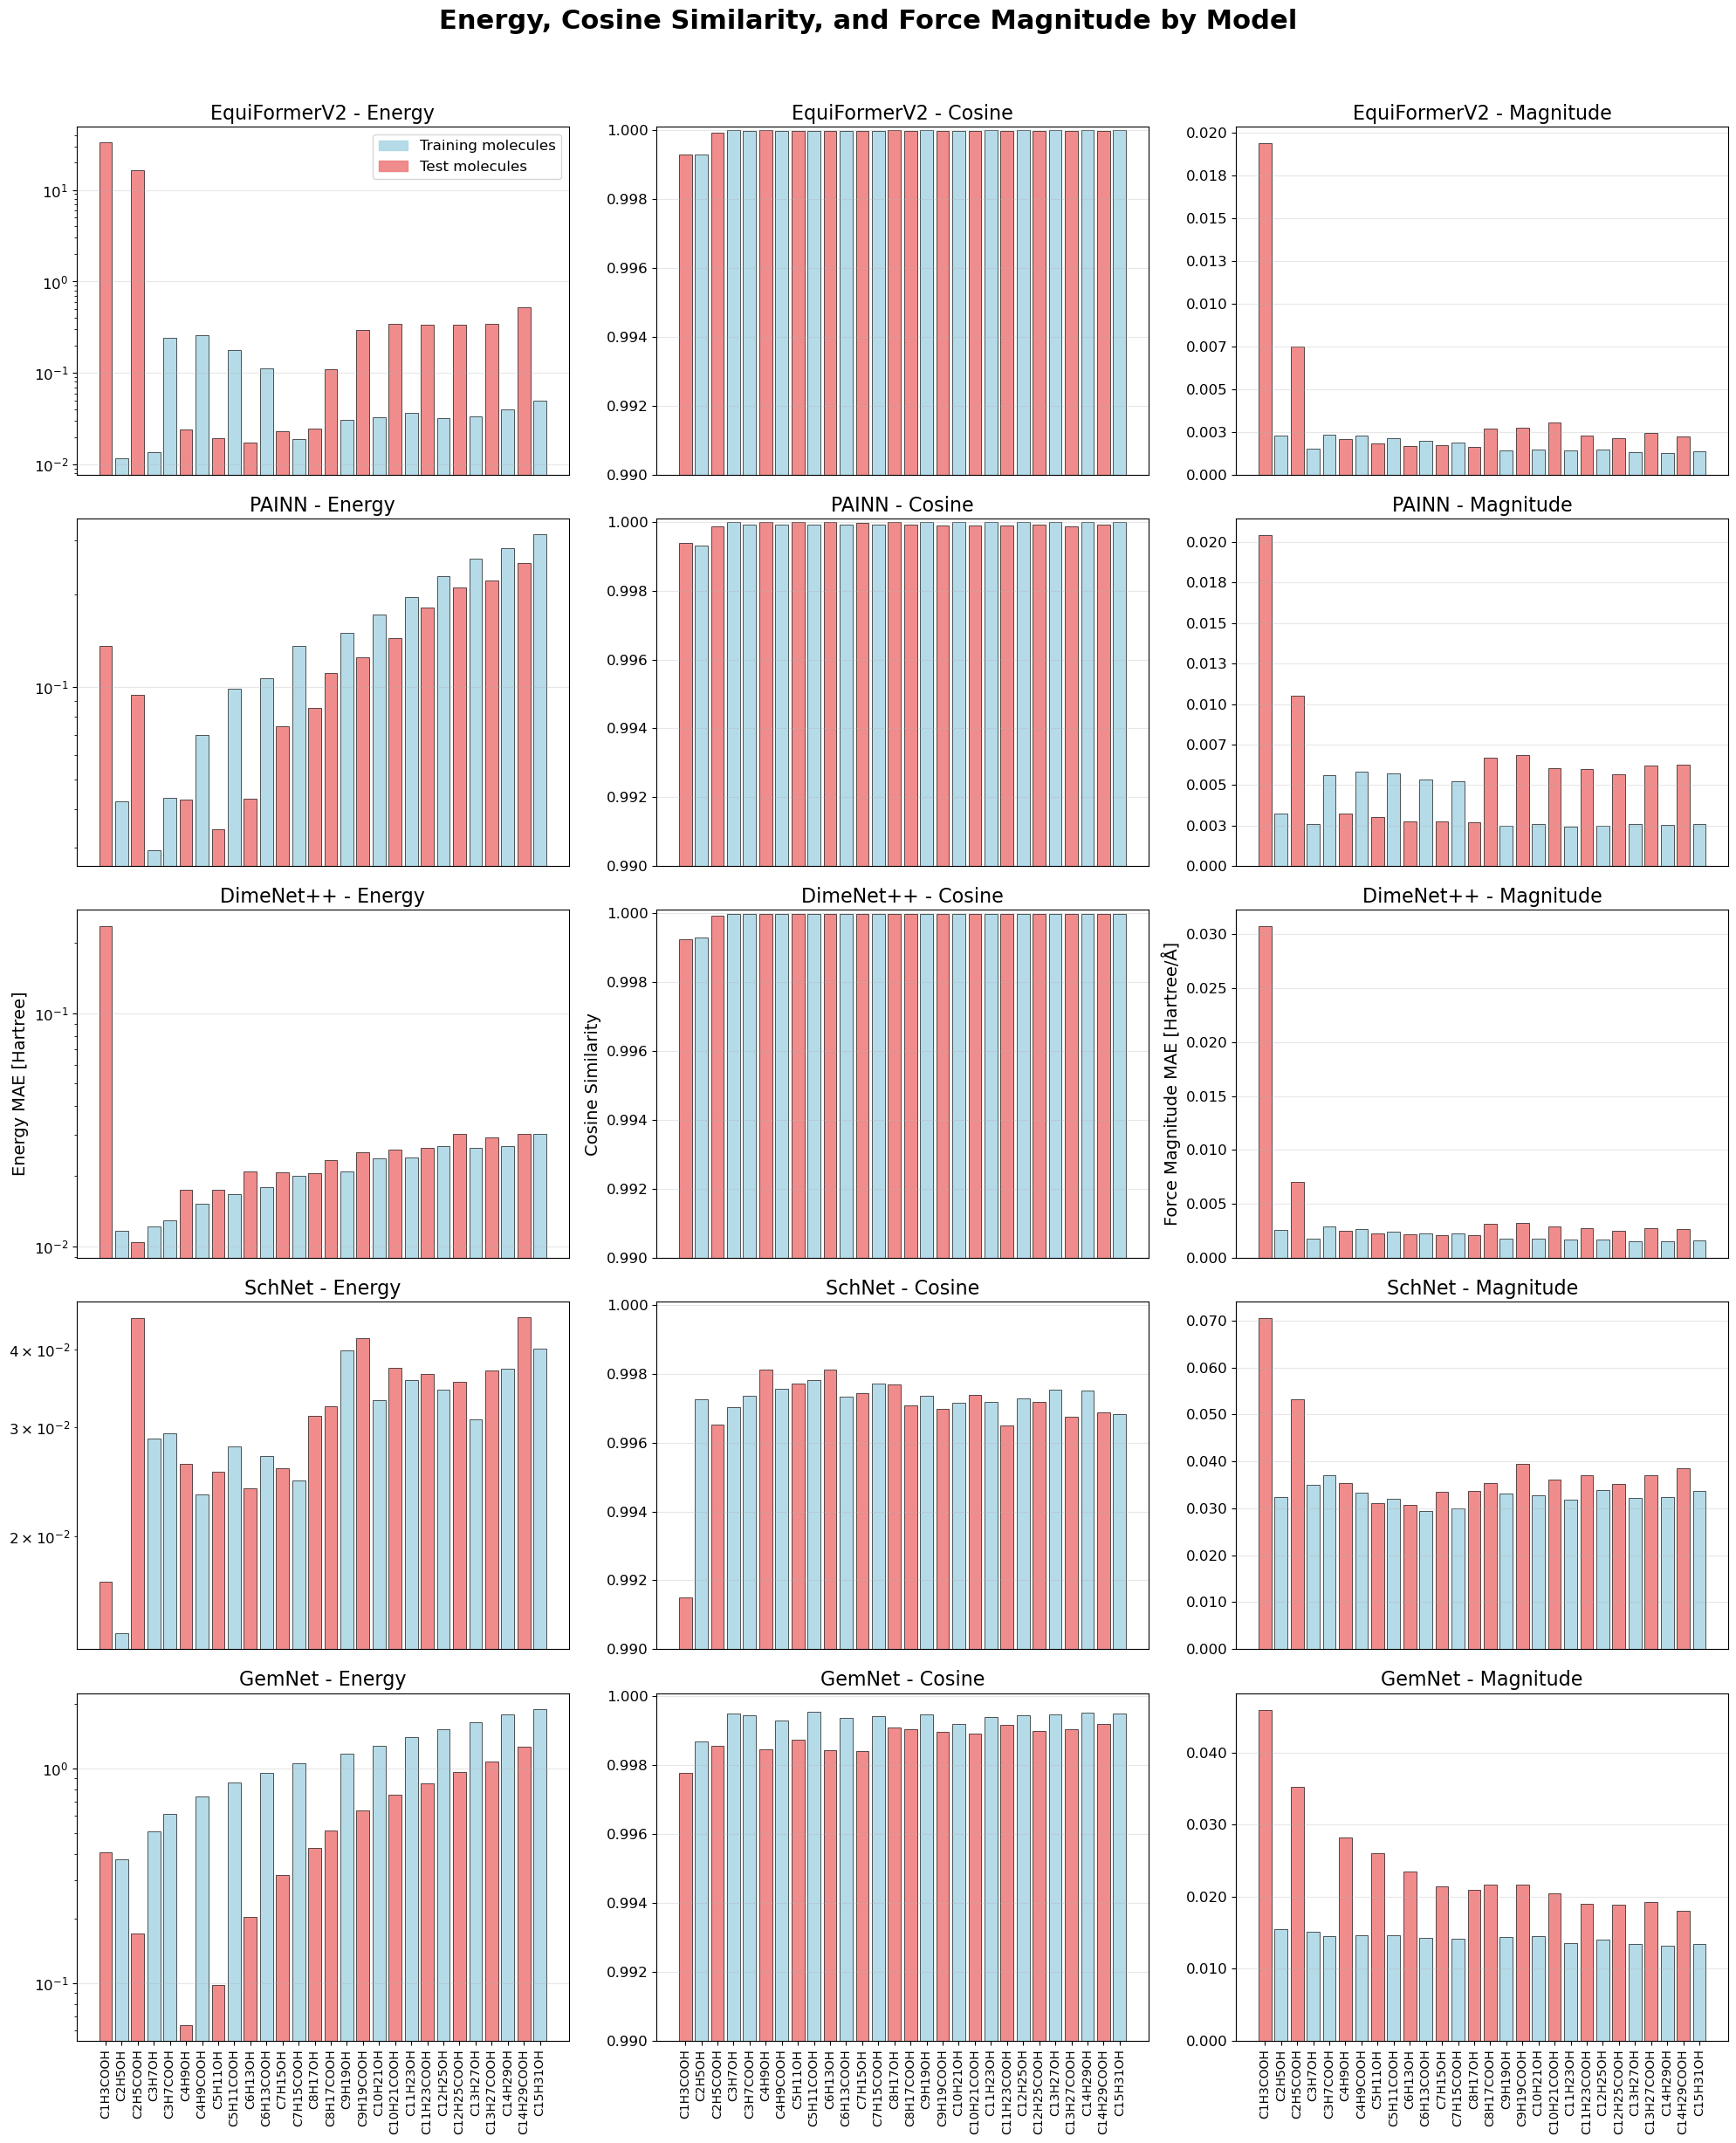

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Academic style
# plt.rcParams.update({
#     "font.family": "serif",
#     "font.serif": ["Times New Roman"],
#     "axes.labelsize": 14,
#     "axes.titlesize": 16,
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 12,
#     "legend.fontsize": 12,
# })

# Colors
train_color = "lightblue"
test_color = "lightcoral"

def get_bar_colors():
    return [train_color if idx in training_indices else test_color for idx in range(n_molecules)]

bar_colors = get_bar_colors()


# ---------------- FIGURE 1: Forces MAE (Main paper, 2x3 layout) ----------------
fig_forces, axes_forces = plt.subplots(2, 3, figsize=(22, 12))
fig_forces.suptitle('Forces MAE by Model', fontsize=22, fontweight='bold')

axes_forces = axes_forces.flatten()

for i, model in enumerate(models):
    ax = axes_forces[i]
    forces_data = forces_df_updated[forces_df_updated['Model'] == model]['MAE'].values
    
    ax.bar(x, forces_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_title(f'{model}', fontsize=16)
    ax.set_xticks(x)
    ax.set_xticklabels(molecule_names, rotation=90)
    ax.set_yscale('log')
    ax.grid(True, alpha=0.3, axis='y')
    
    if i == 0:
        ax.set_ylabel('MAE [eV/Å]')
        handles = [
            plt.Rectangle((0,0),1,1,color=train_color,alpha=0.9,label="Training molecules"),
            plt.Rectangle((0,0),1,1,color=test_color,alpha=0.9,label="Test molecules")
        ]
        ax.legend(handles=handles, loc='upper right')
    else:
        ax.set_ylabel('')

# Hide unused subplot if models < 6
for j in range(len(models), len(axes_forces)):
    fig_forces.delaxes(axes_forces[j])

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_forces_mae_grid.pdf',
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()



# ---------------- FIGURE 2: Appendix (Energy, Cosine, Magnitude, 5x3 layout) ----------------
fig, axes = plt.subplots(len(models), 3, figsize=(20, 25), sharex=False)

fig.suptitle("Energy, Cosine Similarity, and Force Magnitude by Model", fontsize=22, fontweight='bold')

for i, model in enumerate(models):
    # --- Energy ---
    ax = axes[i, 0]
    energy_data = energy_df_updated[energy_df_updated['Model'] == model]['MAE'].values
    ax.bar(x, energy_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_yscale('log')
    ax.set_title(f'{model} - Energy', fontsize=16)
    ax.grid(True, alpha=0.3, axis='y')
    if i == 0:
        handles = [
            plt.Rectangle((0,0),1,1,color=train_color,alpha=0.9,label="Training molecules"),
            plt.Rectangle((0,0),1,1,color=test_color,alpha=0.9,label="Test molecules")
        ]
        ax.legend(handles=handles, loc='upper right')
    if i == len(models)-1:
        ax.set_xticks(x)
        ax.set_xticklabels(molecule_names, rotation=90)
    else:
        ax.set_xticks([])

    if i == int(len(models)/2):
        ax.set_ylabel('Energy MAE [eV]')

    # --- Cosine ---
    ax = axes[i, 1]
    cosine_data = forces_df_updated[forces_df_updated['Model'] == model]['Cosine_Similarity'].values
    ax.bar(x, cosine_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_ylim(0.99, 1.0001)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, pos: f'{val:.3f}'))
    ax.set_title(f'{model} - Cosine', fontsize=16)
    ax.grid(True, alpha=0.3, axis='y')
    if i == len(models)-1:
        ax.set_xticks(x)
        ax.set_xticklabels(molecule_names, rotation=90)
    else:
        ax.set_xticks([])
    if i == int(len(models)/2):
        ax.set_ylabel('Cosine Similarity')

    # --- Magnitude ---
    ax = axes[i, 2]
    magnitude_data = forces_df_updated[forces_df_updated['Model'] == model]['Magnitude_MAE'].values
    ax.bar(x, magnitude_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, pos: f'{val:.3f}'))
    ax.set_title(f'{model} - Magnitude', fontsize=16)
    ax.grid(True, alpha=0.3, axis='y')
    if i == len(models)-1:
        ax.set_xticks(x)
        ax.set_xticklabels(molecule_names, rotation=90)
    else:
        ax.set_xticks([])
    if i == int(len(models)/2):
        ax.set_ylabel('Force Magnitude MAE [eV/Å]')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_appendix_energy_cosine_magnitude_grid.pdf',
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()


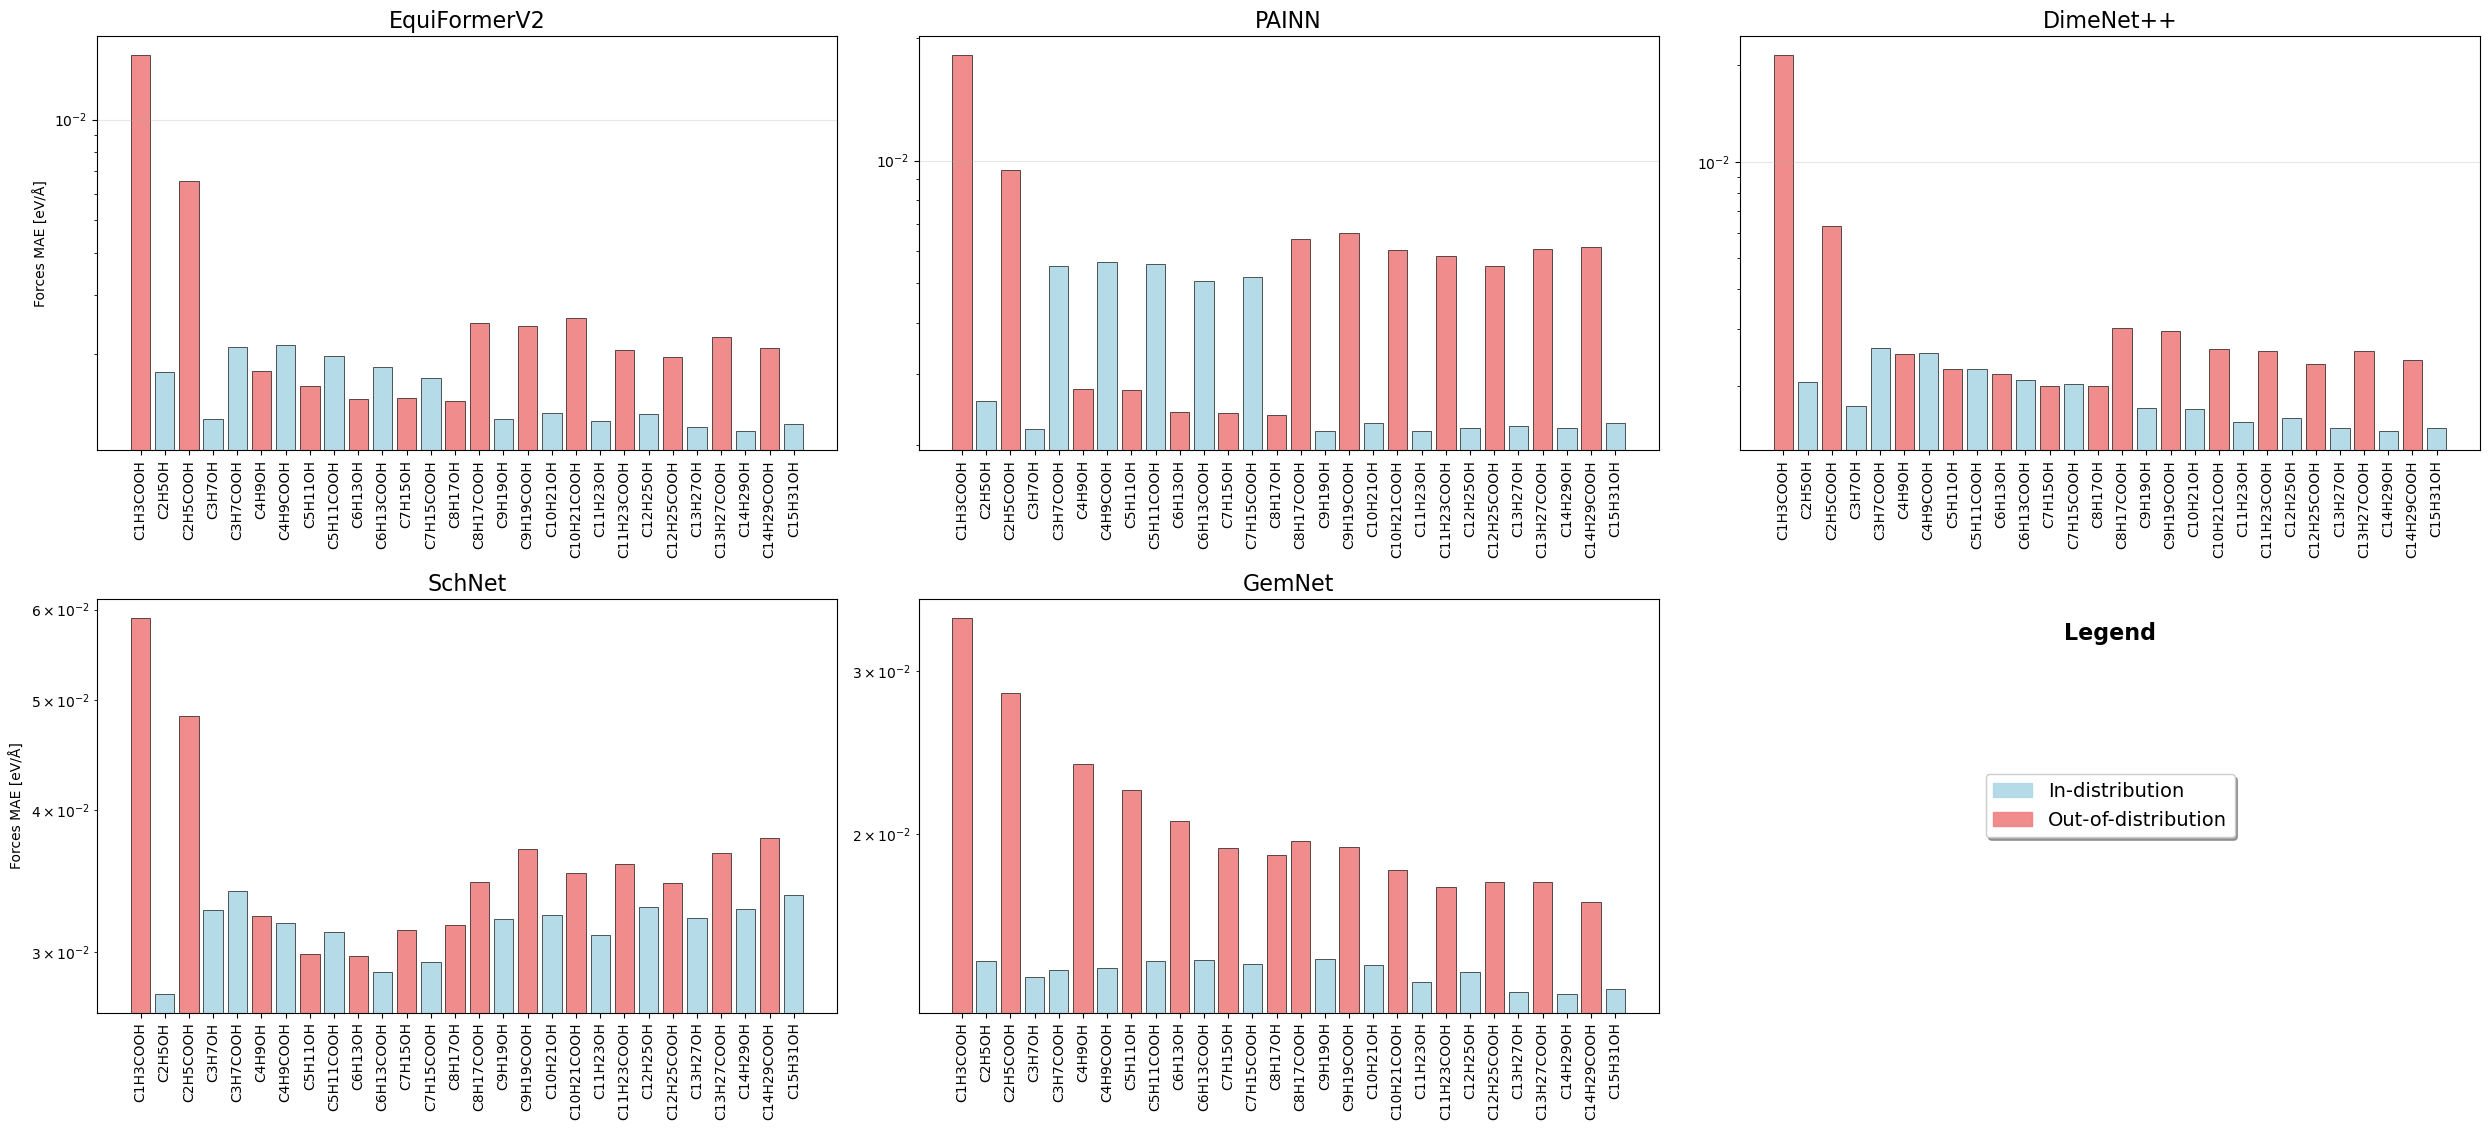

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Colors
train_color = "lightblue"
test_color = "lightcoral"

def get_bar_colors():
    return [train_color if idx in training_indices else test_color for idx in range(n_molecules)]

bar_colors = get_bar_colors()

# ---------------- FIGURE 1: Forces MAE (2x3 layout with legend in 6th position) ----------------
fig_forces = plt.figure(figsize=(25, 12))
# fig_forces.suptitle('Forces MAE by Model', fontsize=22, fontweight='bold')

# Create custom subplot layout: all 6 positions
subplot_positions = [
    (2, 3, 1), (2, 3, 2), (2, 3, 3),  # Top row
    (2, 3, 4), (2, 3, 5), (2, 3, 6)   # Bottom row
]

# Plot data in first 5 positions
for i, model in enumerate(models):
    ax = fig_forces.add_subplot(*subplot_positions[i])
    forces_data = forces_df_updated[forces_df_updated['Model'] == model]['MAE'].values
    
    ax.bar(x, forces_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_title(f'{model}', fontsize=16)
    ax.set_xticks(x)
    ax.set_xticklabels(molecule_names, rotation=90)
    ax.set_yscale('log')
    ax.grid(True, alpha=0.3, axis='y')
    
    if i == 0 or i == 3:
        ax.set_ylabel('Forces MAE [eV/Å]')
    else:
        ax.set_ylabel('')

# Use the 6th subplot position for legend
legend_ax = fig_forces.add_subplot(*subplot_positions[5])
legend_ax.axis('off')  # Turn off the axis

# Create legend elements
from matplotlib.patches import Rectangle

# Training/test legend only
train_patch = Rectangle((0,0),1,1,color=train_color,alpha=0.9,label="In-distribution")
test_patch = Rectangle((0,0),1,1,color=test_color,alpha=0.9,label="Out-of-distribution")

# Just use the distribution legend
all_handles = [train_patch, test_patch]
legend_ax.legend(handles=all_handles, loc='center', fontsize=14, frameon=True, 
                fancybox=True, shadow=True, ncol=1)

# Add a title to the legend area
legend_ax.text(0.5, 0.9, 'Legend', transform=legend_ax.transAxes, 
              fontsize=16, fontweight='bold', ha='center')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_forces_mae_grid.pdf',
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

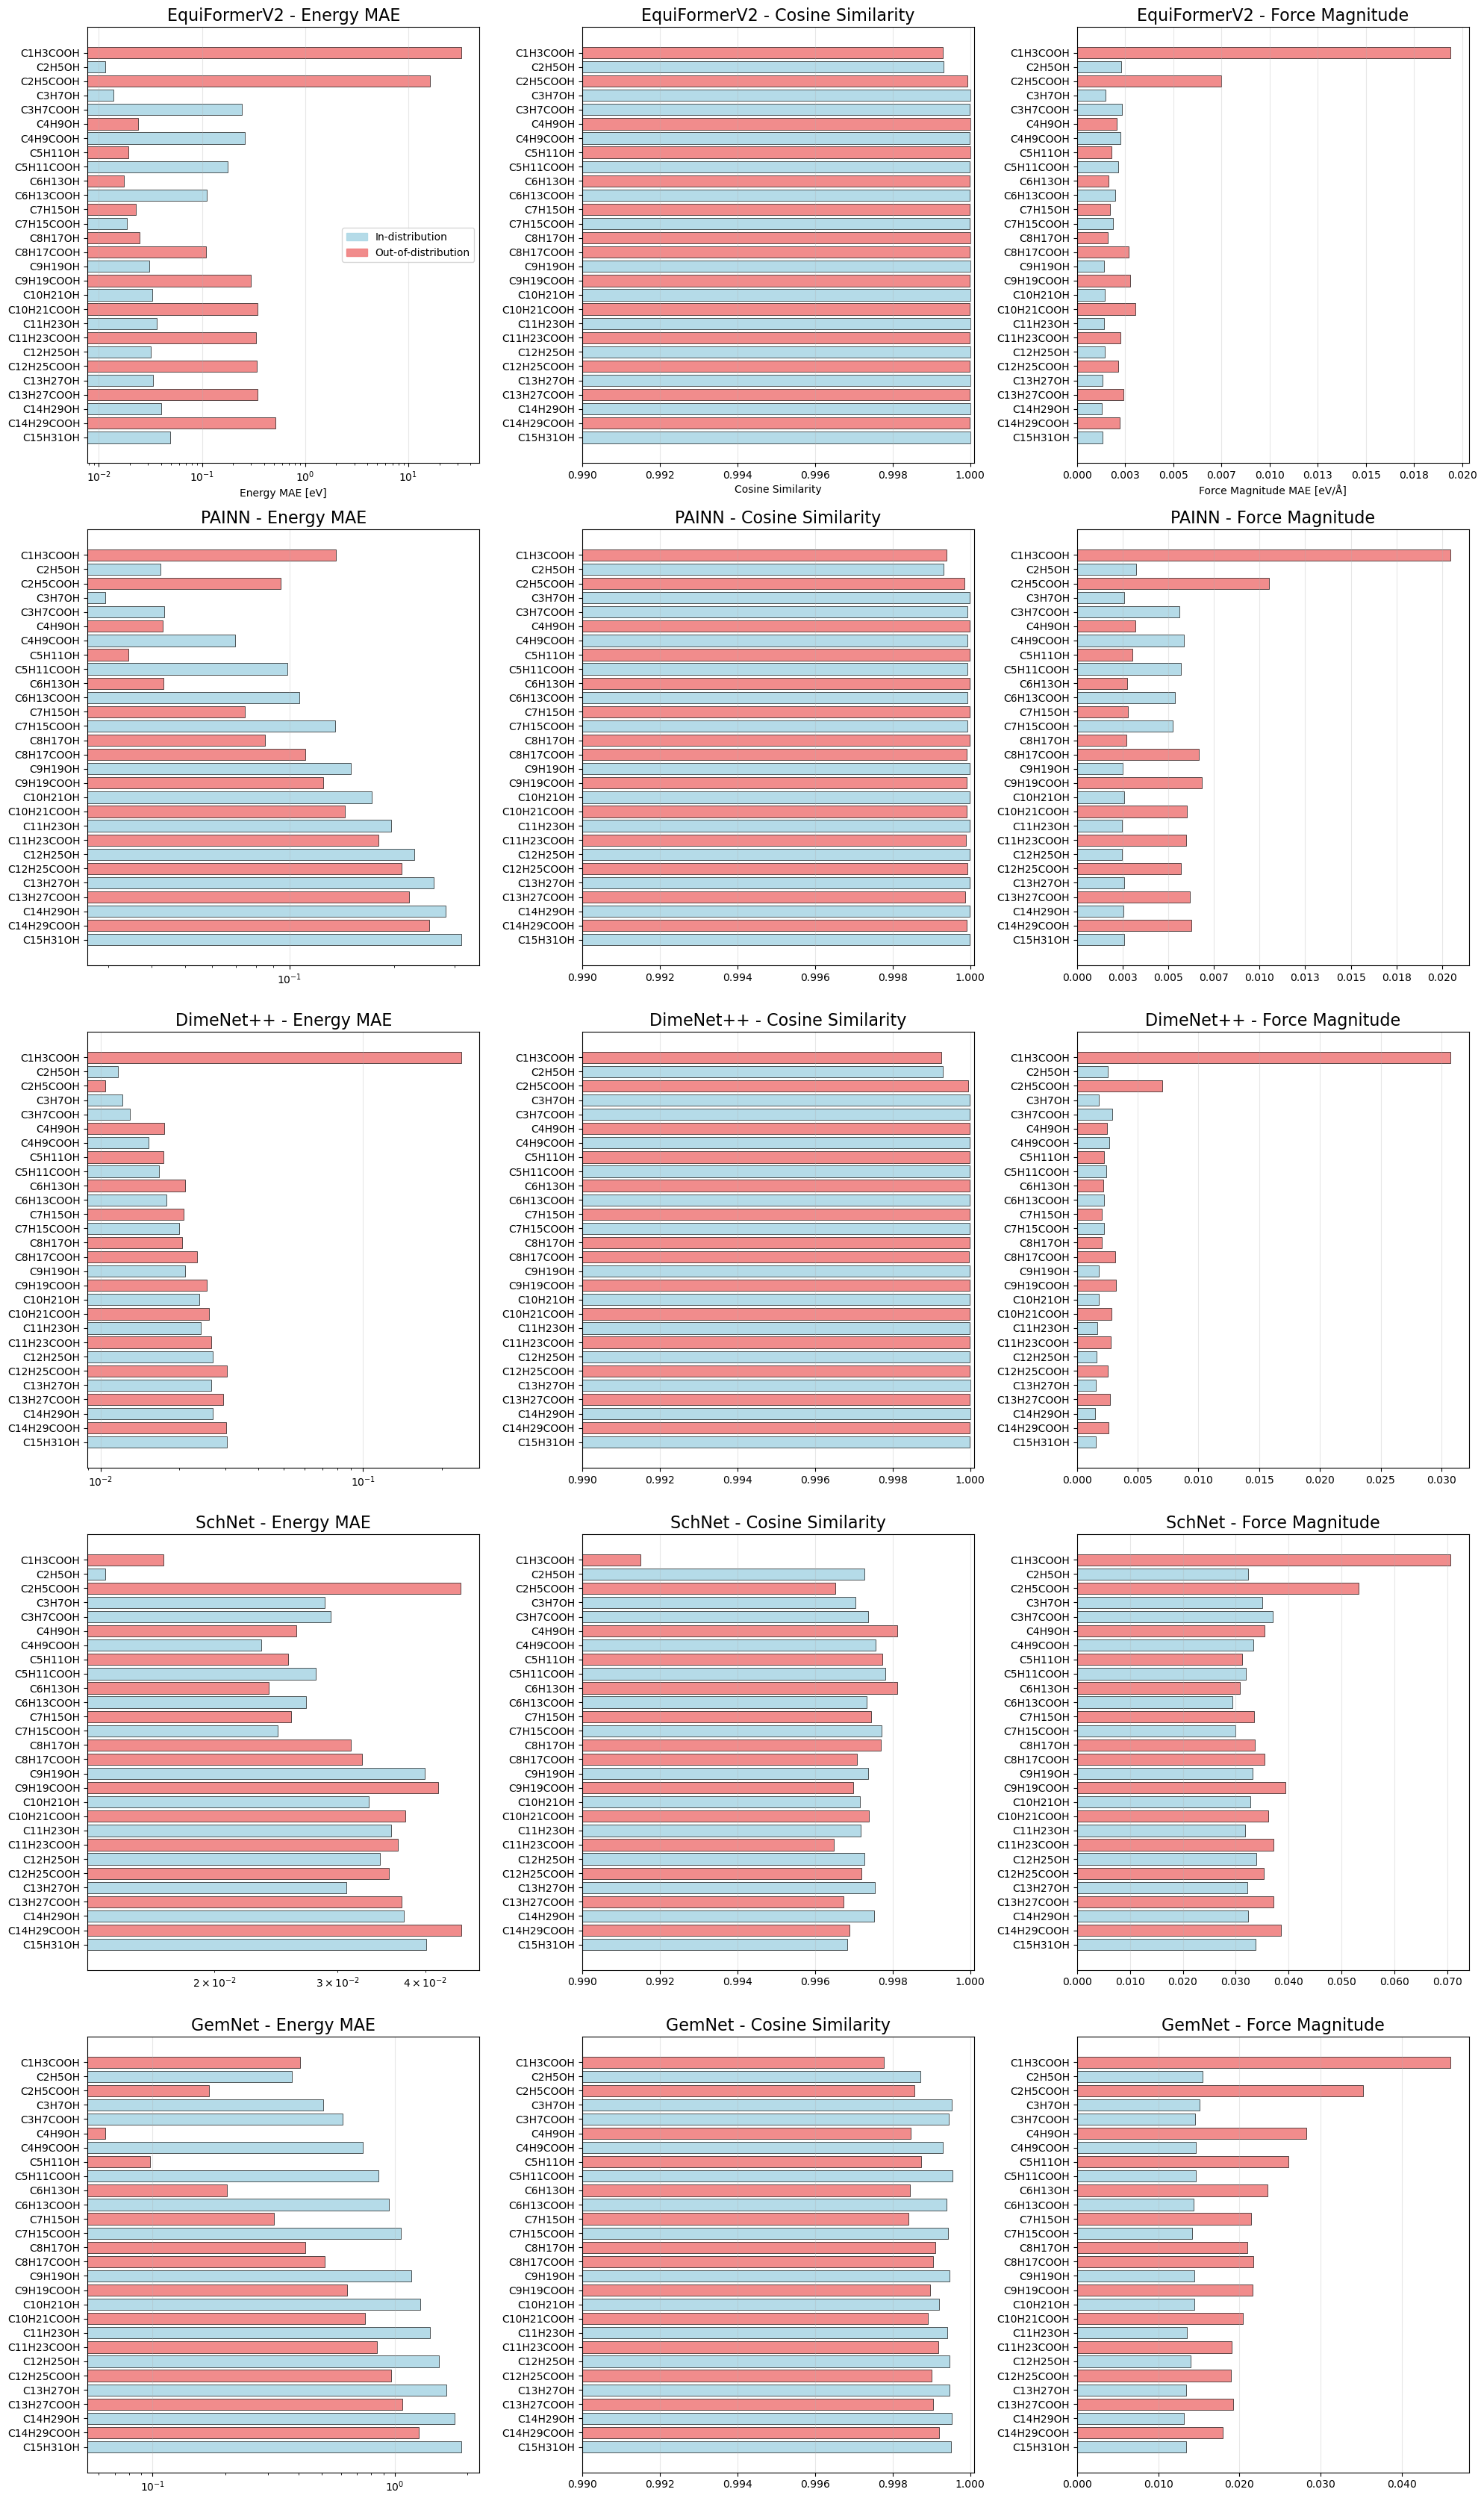

In [22]:
# ---------------- FIGURE 2: Appendix (5x3 layout with each subplot rotated 90 degrees) ----------------
fig, axes = plt.subplots(len(models), 3, figsize=(20, 35), sharex=False)

# fig.suptitle("Energy, Cosine Similarity, and Force Magnitude by Model", fontsize=22, fontweight='bold')

for i, model in enumerate(models):
    # --- Energy (Left column) ---
    ax = axes[i, 0]
    energy_data = energy_df_updated[energy_df_updated['Model'] == model]['MAE'].values
    
    # Horizontal bars (rotated 90 degrees)
    y_pos = np.arange(len(molecule_names))
    colors = [train_color if idx in training_indices else test_color for idx in range(n_molecules)]
    
    ax.barh(y_pos, energy_data, color=colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_xscale('log')
    ax.set_title(f'{model} - Energy MAE', fontsize=16)
    ax.grid(True, alpha=0.3, axis='x')
    
    # Set y-axis (now the molecule axis)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(molecule_names, fontsize=10)
    ax.invert_yaxis()  # To have molecules in correct order
    
    if i == 0:
        handles = [
            plt.Rectangle((0,0),1,1,color=train_color,alpha=0.9,label="In-distribution"),
            plt.Rectangle((0,0),1,1,color=test_color,alpha=0.9,label="Out-of-distribution")
        ]
        ax.legend(handles=handles, loc='right')
    
    if i  == 0:
        ax.set_xlabel('Energy MAE [eV]')

    # --- Cosine Similarity (Middle column) ---
    ax = axes[i, 1]
    cosine_data = forces_df_updated[forces_df_updated['Model'] == model]['Cosine_Similarity'].values
    
    ax.barh(y_pos, cosine_data, color=colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_xlim(0.99, 1.0001)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda val, pos: f'{val:.3f}'))
    ax.set_title(f'{model} - Cosine Similarity', fontsize=16)
    ax.grid(True, alpha=0.3, axis='x')
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(molecule_names, fontsize=10)
    ax.invert_yaxis()
    
    if i == 0:
        ax.set_xlabel('Cosine Similarity')

    # --- Force Magnitude MAE (Right column) ---
    ax = axes[i, 2]
    magnitude_data = forces_df_updated[forces_df_updated['Model'] == model]['Magnitude_MAE'].values
    
    ax.barh(y_pos, magnitude_data, color=colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda val, pos: f'{val:.3f}'))
    ax.set_title(f'{model} - Force Magnitude', fontsize=16)
    ax.grid(True, alpha=0.3, axis='x')
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(molecule_names, fontsize=10)
    ax.invert_yaxis()
    
    if i == 0:
        ax.set_xlabel('Force Magnitude MAE [eV/Å]')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_appendix_energy_cosine_magnitude_grid.pdf',
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

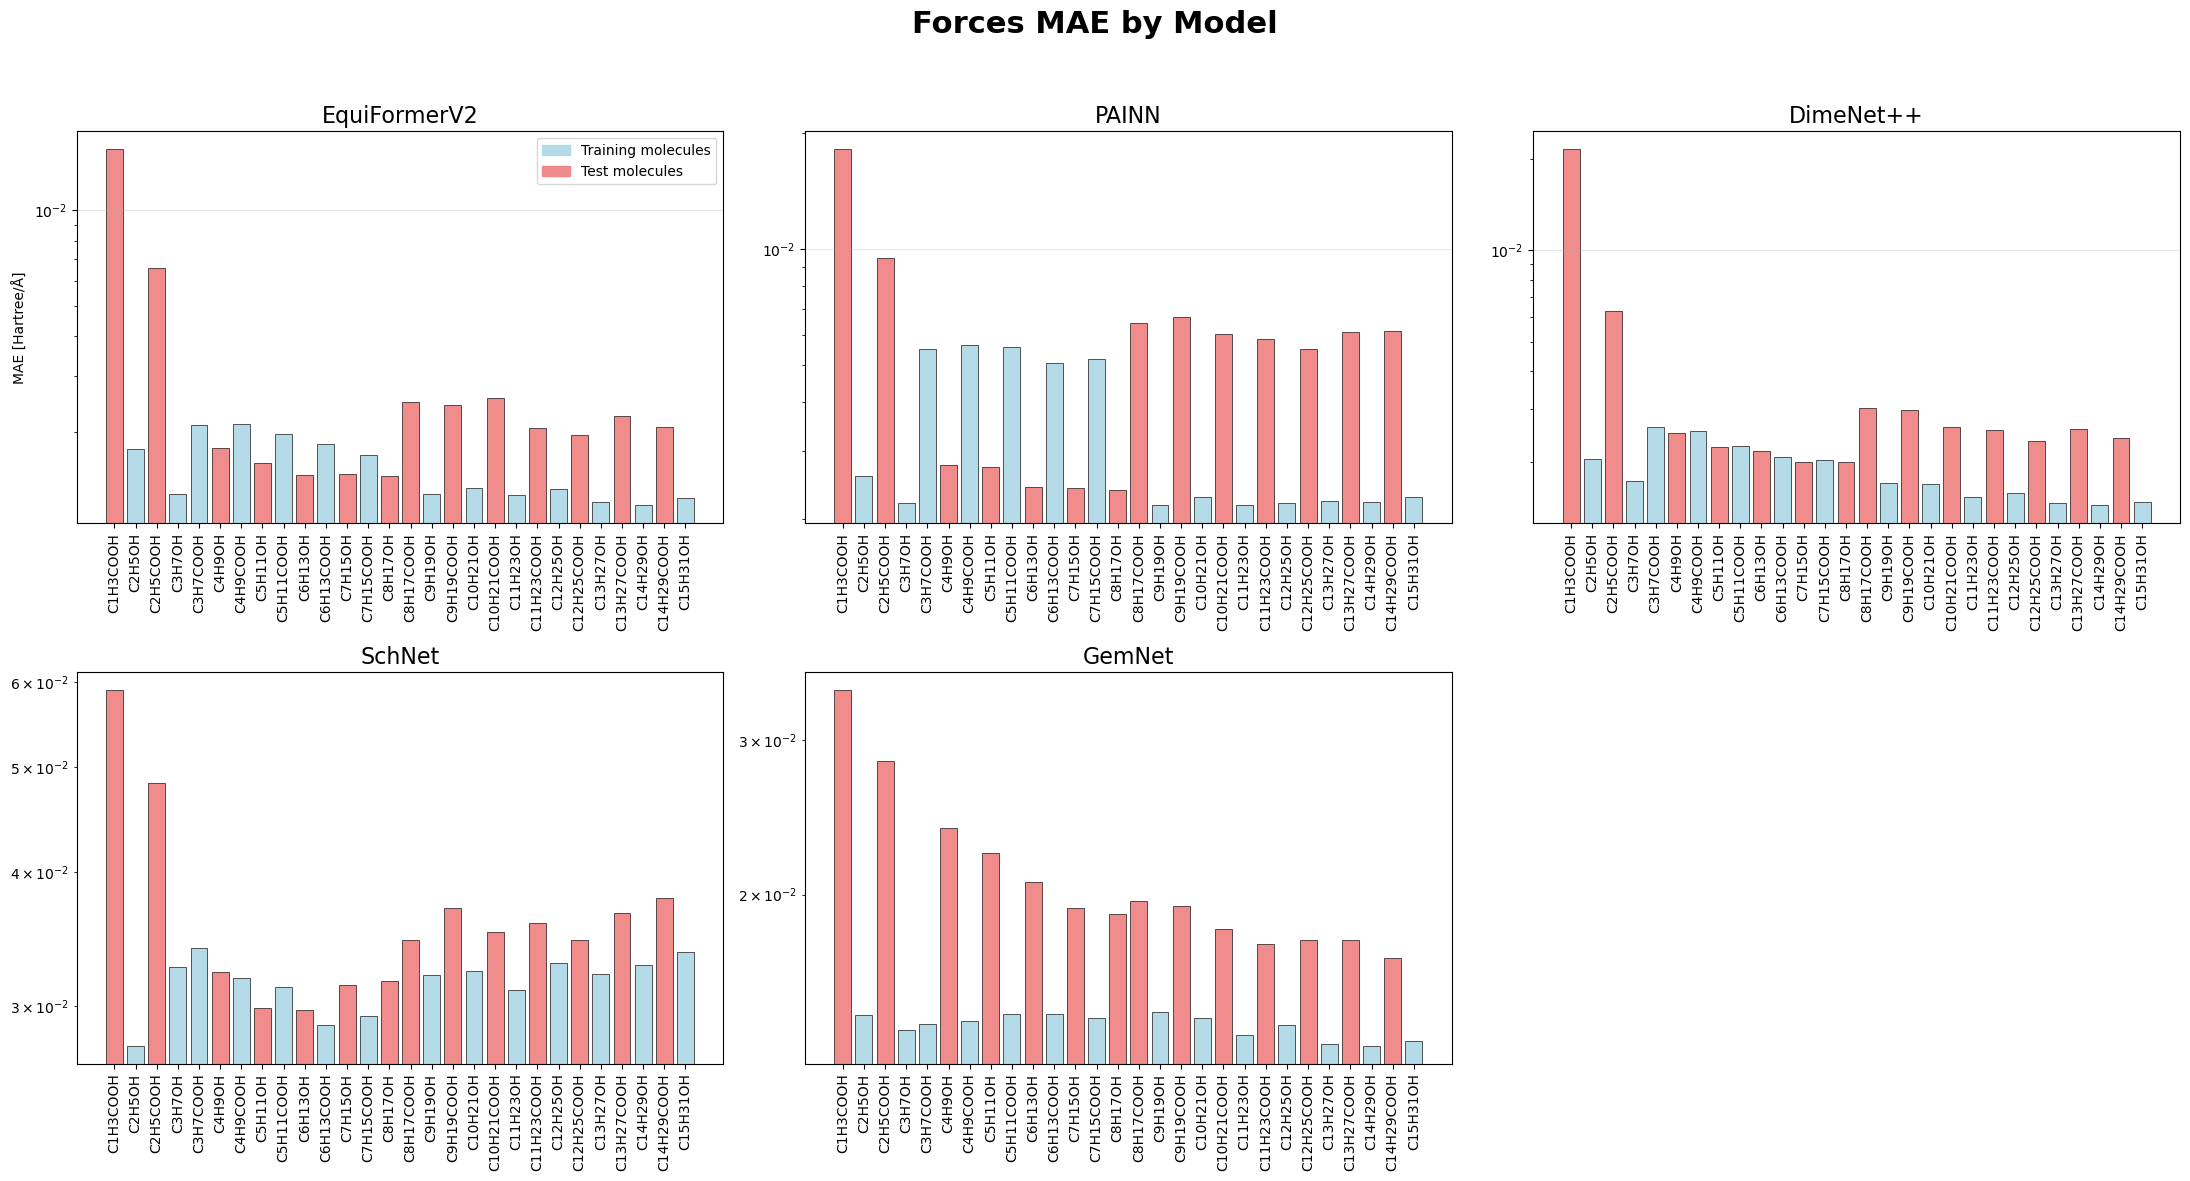

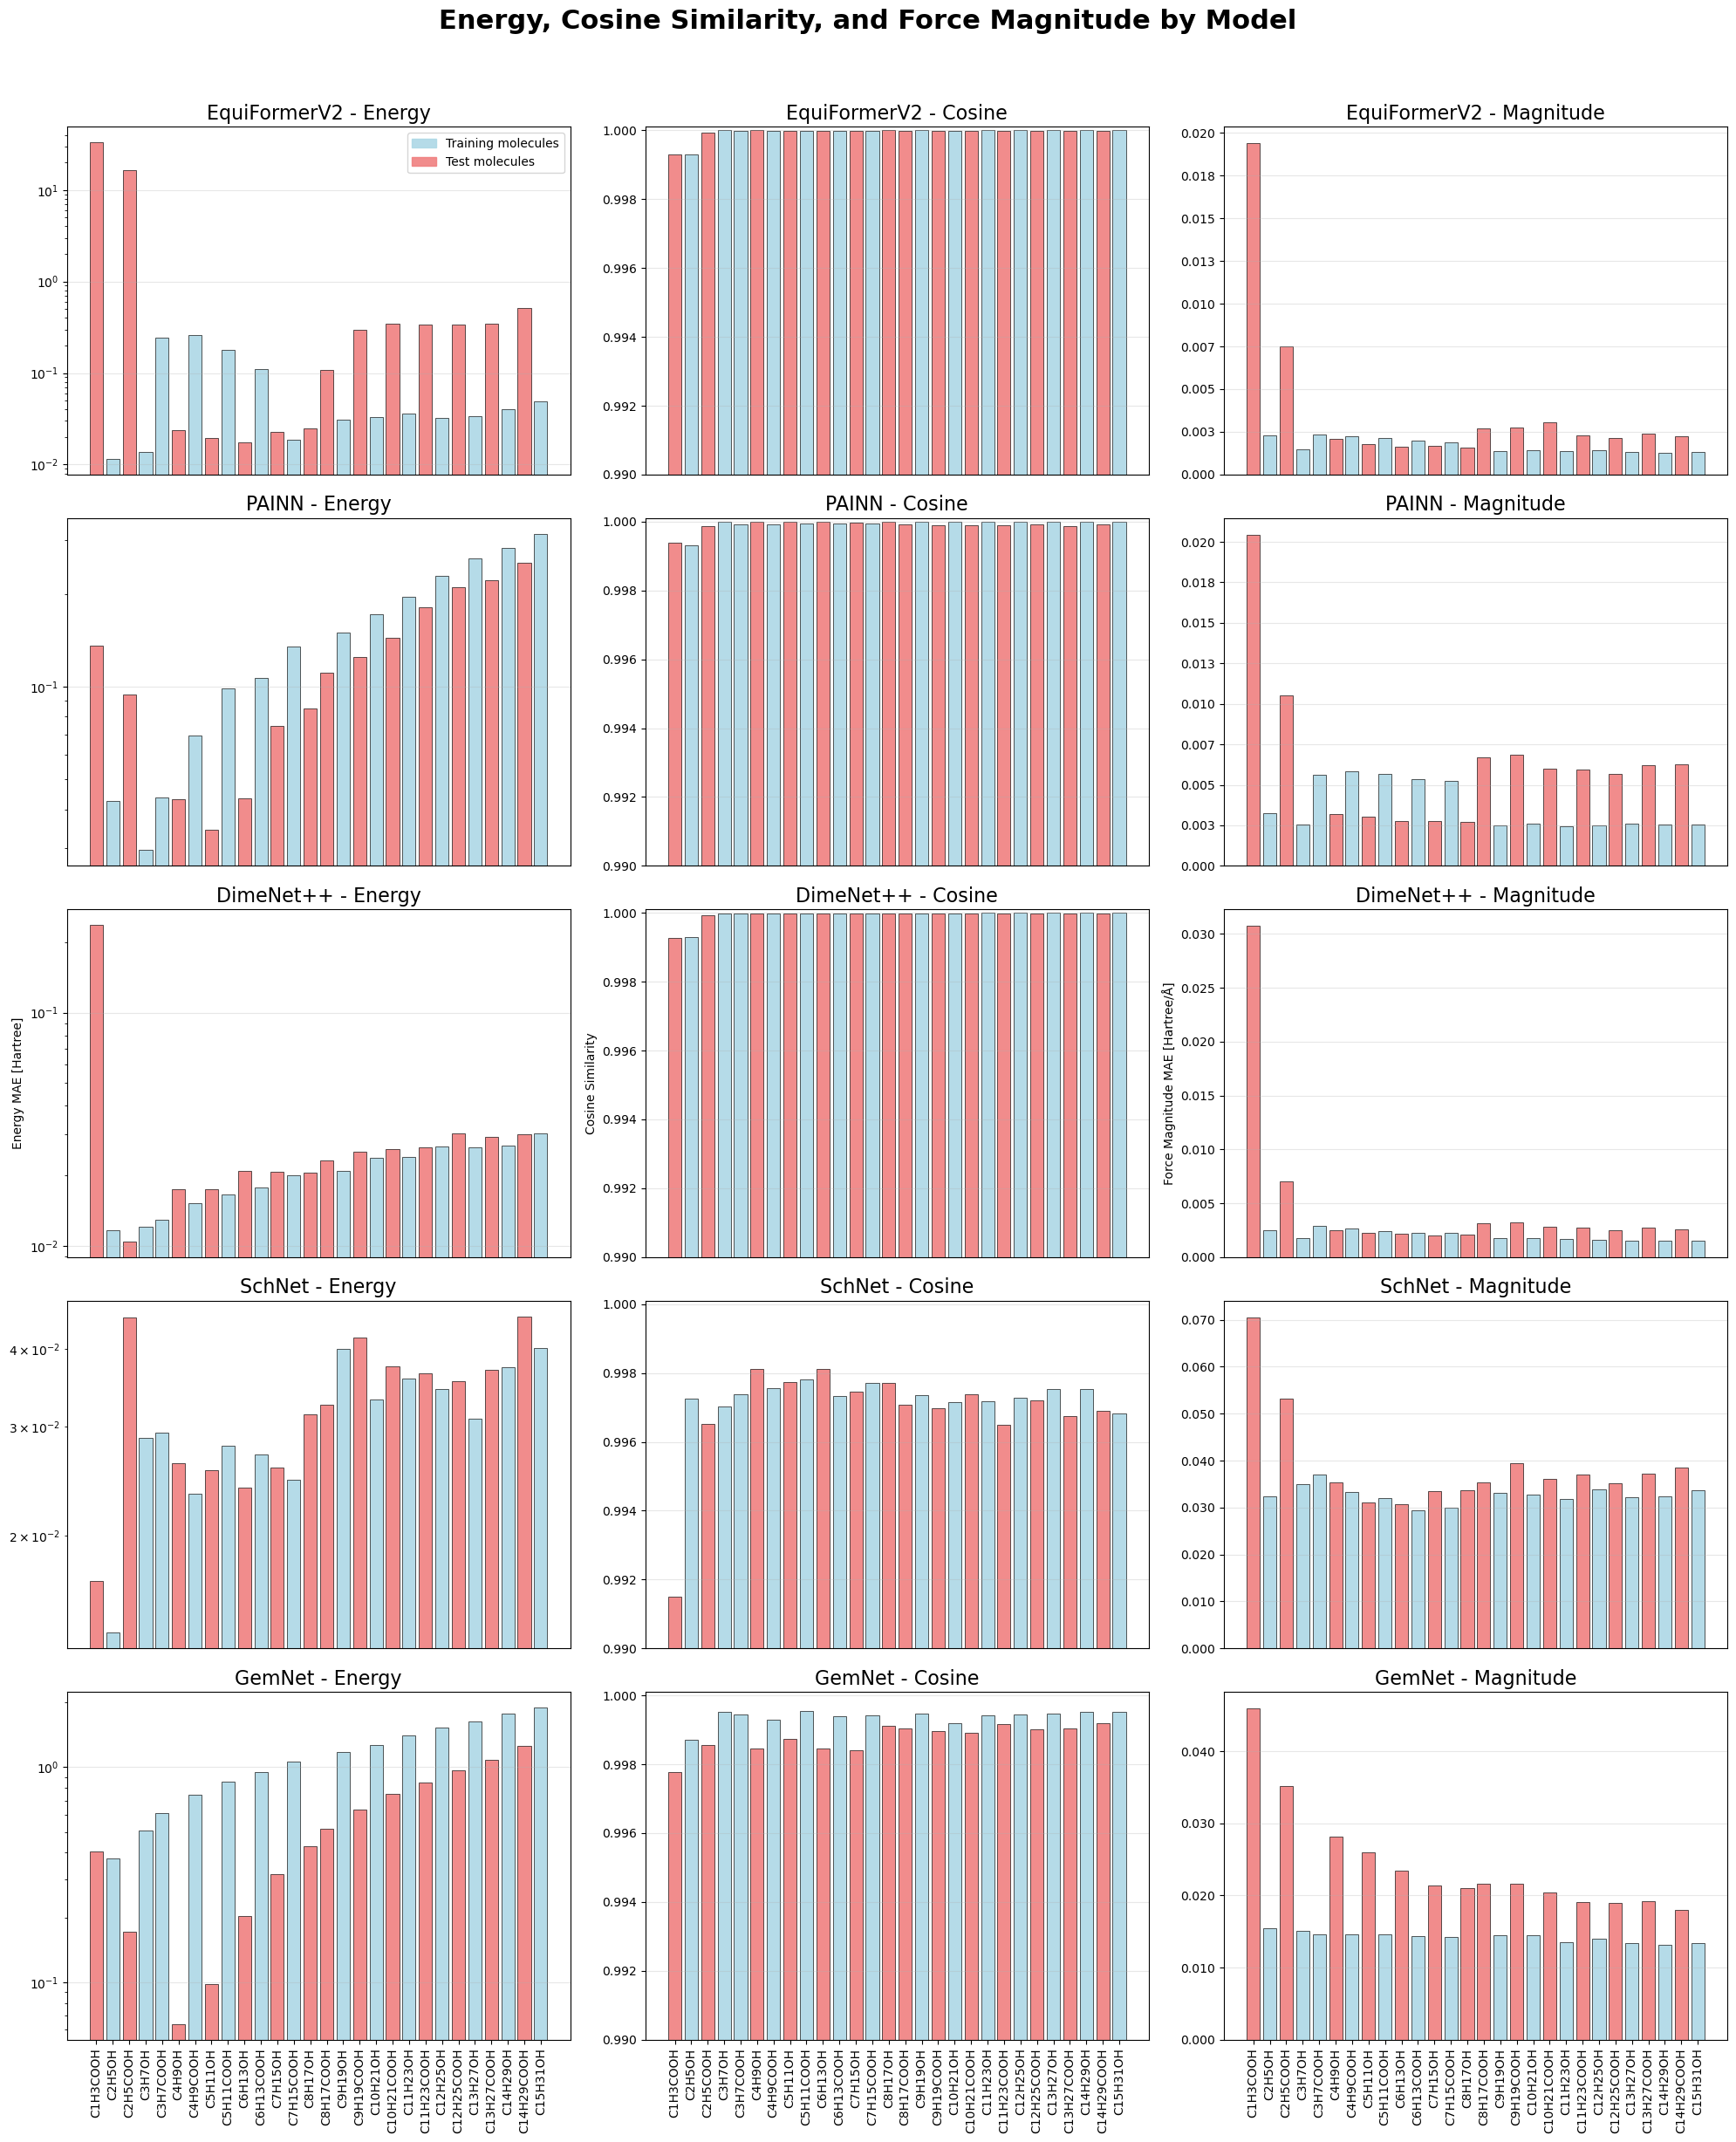

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Academic style
# plt.rcParams.update({
#     "font.family": "serif",
#     "font.serif": ["Times New Roman"],
#     "axes.labelsize": 14,
#     "axes.titlesize": 16,
#     "xtick.labelsize": 10,
#     "ytick.labelsize": 12,
#     "legend.fontsize": 12,
# })

# Colors
train_color = "lightblue"
test_color = "lightcoral"

def get_bar_colors():
    return [train_color if idx in training_indices else test_color for idx in range(n_molecules)]

bar_colors = get_bar_colors()


# ---------------- FIGURE 1: Forces MAE (Main paper, 2x3 layout) ----------------
fig_forces, axes_forces = plt.subplots(2, 3, figsize=(22, 12))
fig_forces.suptitle('Forces MAE by Model', fontsize=22, fontweight='bold')

axes_forces = axes_forces.flatten()

for i, model in enumerate(models):
    ax = axes_forces[i]
    forces_data = forces_df_updated[forces_df_updated['Model'] == model]['MAE'].values
    
    ax.bar(x, forces_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_title(f'{model}', fontsize=16)
    ax.set_xticks(x)
    ax.set_xticklabels(molecule_names, rotation=90)
    ax.set_yscale('log')
    ax.grid(True, alpha=0.3, axis='y')
    
    if i == 0:
        ax.set_ylabel('MAE [Hartree/Å]')
        handles = [
            plt.Rectangle((0,0),1,1,color=train_color,alpha=0.9,label="Training molecules"),
            plt.Rectangle((0,0),1,1,color=test_color,alpha=0.9,label="Test molecules")
        ]
        ax.legend(handles=handles, loc='upper right')
    else:
        ax.set_ylabel('')

# Hide unused subplot if models < 6
for j in range(len(models), len(axes_forces)):
    fig_forces.delaxes(axes_forces[j])

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_forces_mae_grid.pdf',
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()



# ---------------- FIGURE 2: Appendix (Energy, Cosine, Magnitude, 5x3 layout) ----------------
fig, axes = plt.subplots(len(models), 3, figsize=(20, 25), sharex=False)

fig.suptitle("Energy, Cosine Similarity, and Force Magnitude by Model", fontsize=22, fontweight='bold')

for i, model in enumerate(models):
    # --- Energy ---
    ax = axes[i, 0]
    energy_data = energy_df_updated[energy_df_updated['Model'] == model]['MAE'].values
    ax.bar(x, energy_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_yscale('log')
    ax.set_title(f'{model} - Energy', fontsize=16)
    ax.grid(True, alpha=0.3, axis='y')
    if i == 0:
        handles = [
            plt.Rectangle((0,0),1,1,color=train_color,alpha=0.9,label="Training molecules"),
            plt.Rectangle((0,0),1,1,color=test_color,alpha=0.9,label="Test molecules")
        ]
        ax.legend(handles=handles, loc='upper right')
    if i == len(models)-1:
        ax.set_xticks(x)
        ax.set_xticklabels(molecule_names, rotation=90)
    else:
        ax.set_xticks([])

    if i == int(len(models)/2):
        ax.set_ylabel('Energy MAE [Hartree]')

    # --- Cosine ---
    ax = axes[i, 1]
    cosine_data = forces_df_updated[forces_df_updated['Model'] == model]['Cosine_Similarity'].values
    ax.bar(x, cosine_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.set_ylim(0.99, 1.0001)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, pos: f'{val:.3f}'))
    ax.set_title(f'{model} - Cosine', fontsize=16)
    ax.grid(True, alpha=0.3, axis='y')
    if i == len(models)-1:
        ax.set_xticks(x)
        ax.set_xticklabels(molecule_names, rotation=90)
    else:
        ax.set_xticks([])
    if i == int(len(models)/2):
        ax.set_ylabel('Cosine Similarity')

    # --- Magnitude ---
    ax = axes[i, 2]
    magnitude_data = forces_df_updated[forces_df_updated['Model'] == model]['Magnitude_MAE'].values
    ax.bar(x, magnitude_data, color=bar_colors, alpha=0.9, edgecolor="black", linewidth=0.5)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, pos: f'{val:.3f}'))
    ax.set_title(f'{model} - Magnitude', fontsize=16)
    ax.grid(True, alpha=0.3, axis='y')
    if i == len(models)-1:
        ax.set_xticks(x)
        ax.set_xticklabels(molecule_names, rotation=90)
    else:
        ax.set_xticks([])
    if i == int(len(models)/2):
        ax.set_ylabel('Force Magnitude MAE [Hartree/Å]')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('generalisation_checkpoints/cross_length_functionality/figure_appendix_energy_cosine_magnitude_grid.pdf',
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()


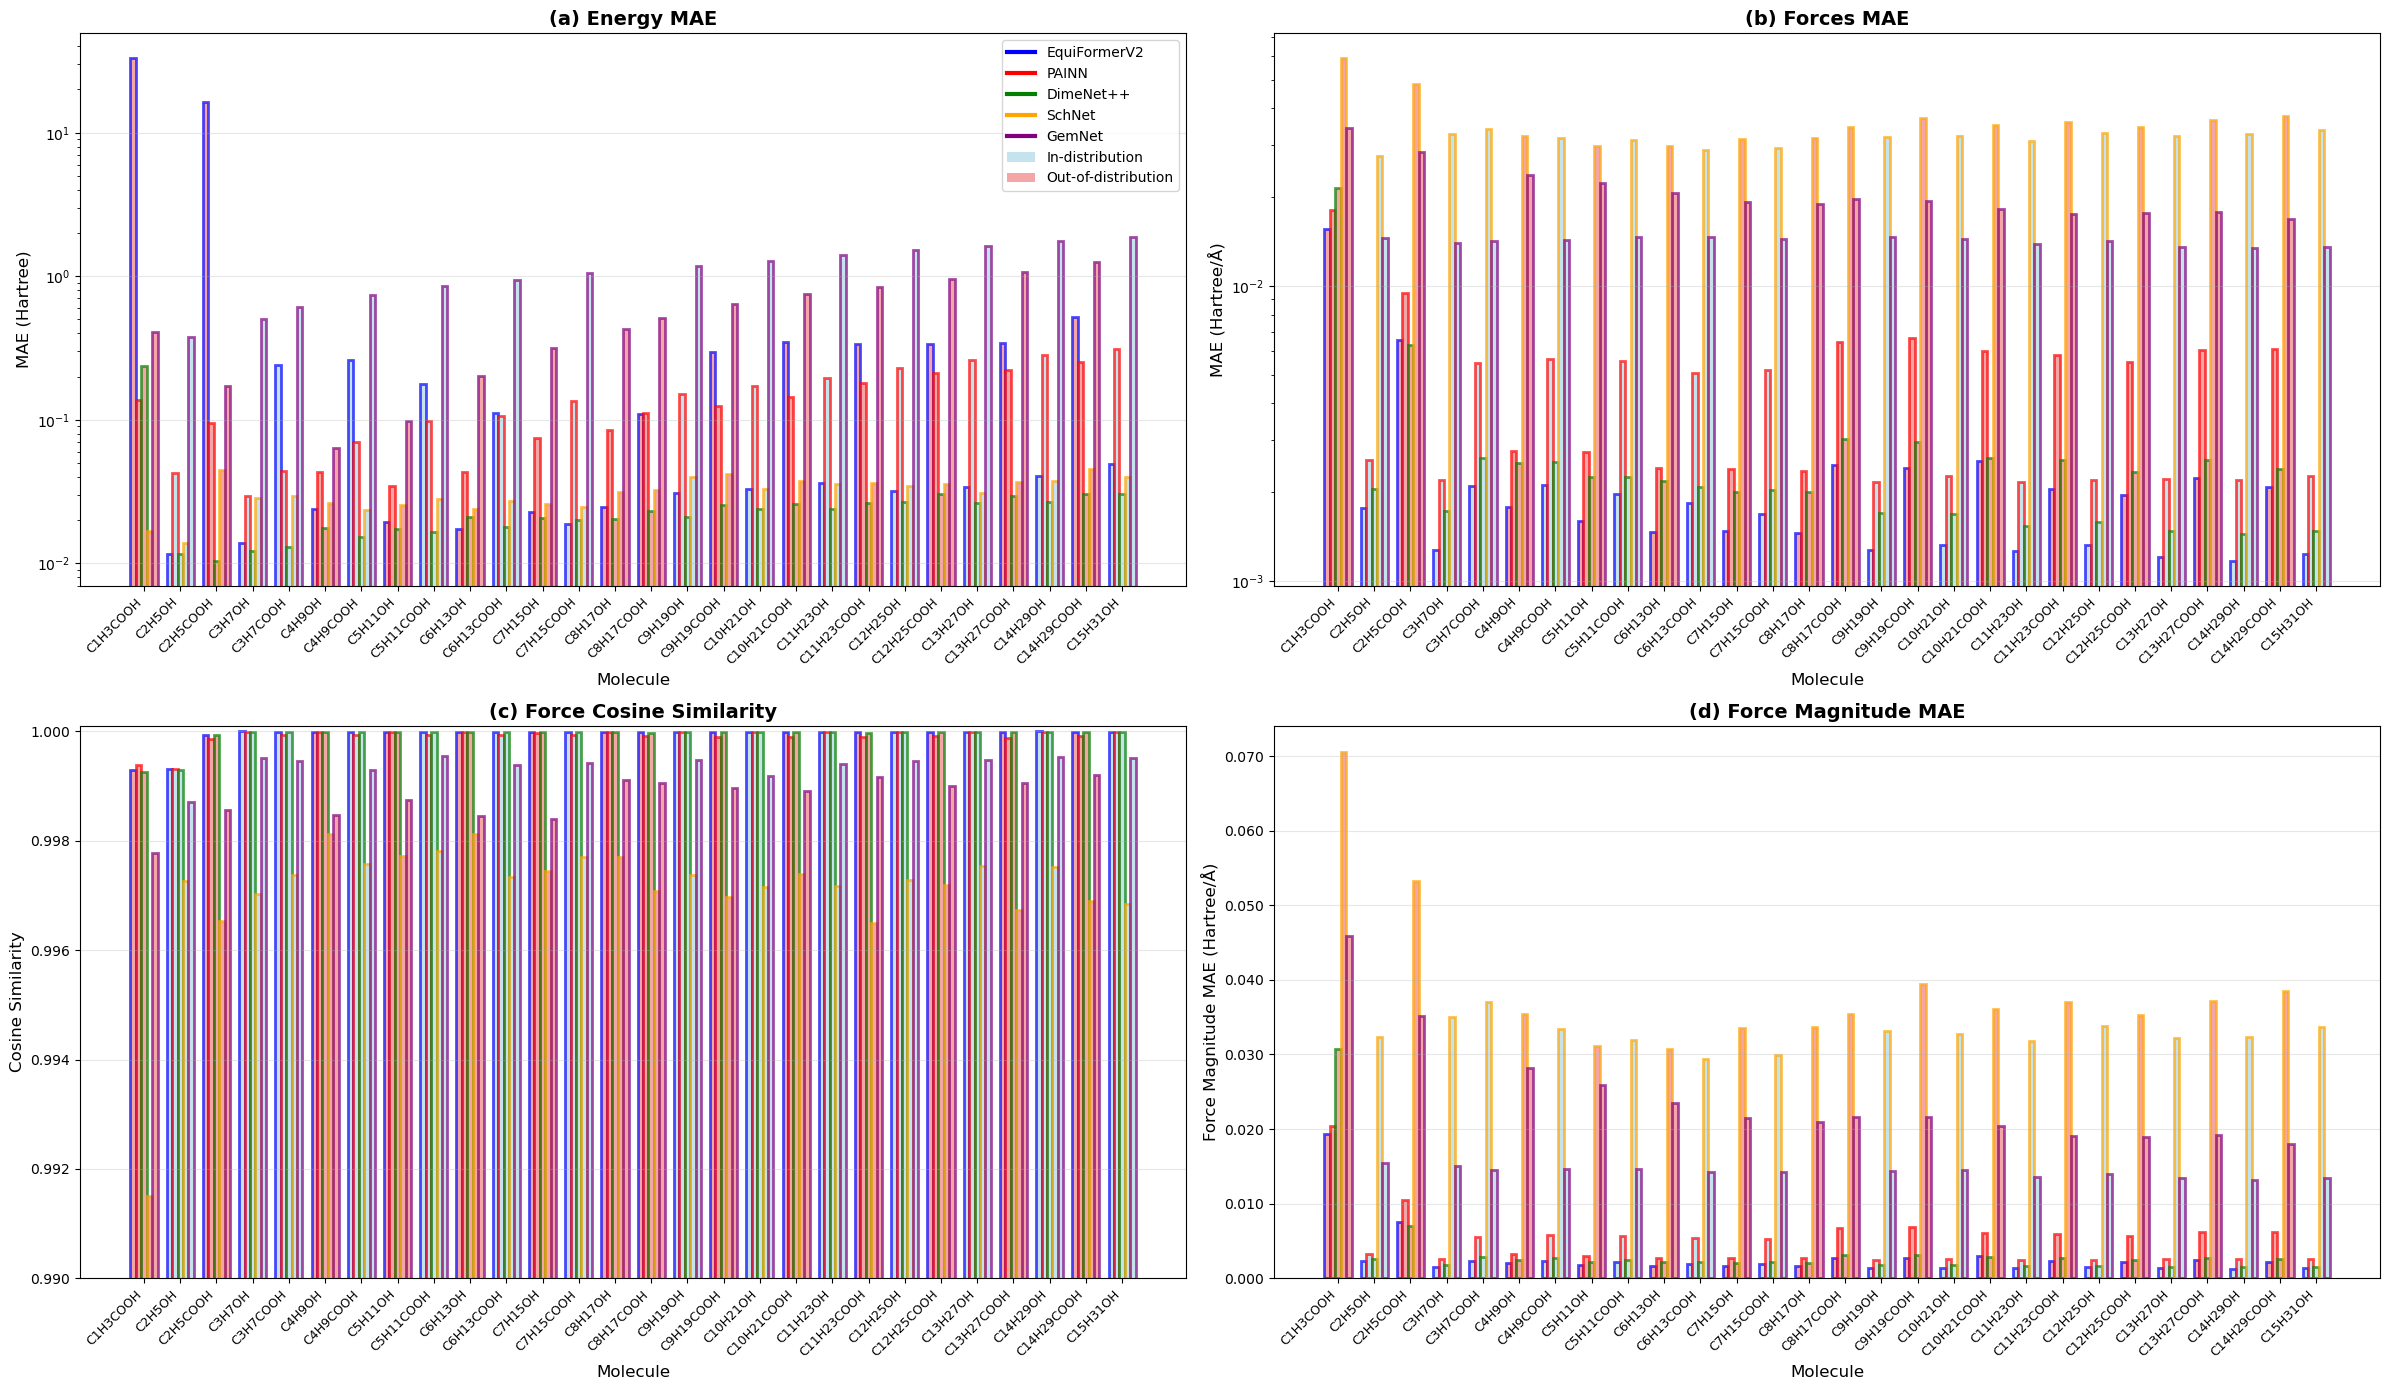

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import itertools
from typing import List

# Set up the figure with three subplots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(24, 14))

# Define molecule names
alcohols: List[str] = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]
acids: List[str] = [f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)]

molecule_names: List[str] = list(itertools.chain.from_iterable(zip(acids, alcohols)))

# Define training indices based on your specification
training_indices = []
test_indices = []

for i, molecule in enumerate(molecule_names):
    if 'COOH' in molecule:
        # Carboxylic acids
        carbon_count = int(molecule.split('H')[0][1:]) + 1  # +1 because COOH adds one carbon
        if 4 <= carbon_count <= 8:  # C3H7COOH to C7H15COOH corresponds to 4-8 total carbons
            training_indices.append(i)
        else:
            test_indices.append(i)
    else:
        # Alcohols
        carbon_count = int(molecule.split('H')[0][1:])
        if 4 <= carbon_count <= 8:  # C4H9OH to C8H17OH
            test_indices.append(i)
        else:
            training_indices.append(i)

# Bar chart parameters
n_molecules = len(molecule_names)
models = list(energy_df_updated['Model'].unique())
n_models = len(models)
bar_width = 0.15
x = np.arange(n_molecules)

# Create offset positions for each model's bars
offsets = np.linspace(-bar_width * (n_models - 1) / 2, bar_width * (n_models - 1) / 2, n_models)

# Subplot 1: Energy MAE
for i, model in enumerate(models):
    model_data = energy_df_updated[energy_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        y_values = model_data['MAE'].values
        
        # Create colors based on in-distribution vs out-of-distribution
        colors = ['lightblue' if idx in training_indices else 'lightcoral' for idx in range(n_molecules)]
        
        bars = ax1.bar(x + offsets[i], y_values, bar_width, 
                      color=colors, alpha=0.7, 
                      edgecolor=model_colors_updated[model], linewidth=2,
                      label=model if i == 0 else "")

ax1.set_xlabel('Molecule', fontsize=12)
ax1.set_ylabel('MAE (eV)', fontsize=12)
ax1.set_title('(a) Energy MAE', fontsize=14, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3, axis='y')

# Subplot 2: Forces MAE
for i, model in enumerate(models):
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        y_values = model_data['MAE'].values
        
        colors = ['lightblue' if idx in training_indices else 'lightcoral' for idx in range(n_molecules)]
        
        bars = ax2.bar(x + offsets[i], y_values, bar_width, 
                      color=colors, alpha=0.7, 
                      edgecolor=model_colors_updated[model], linewidth=2)

ax2.set_xlabel('Molecule', fontsize=12)
ax2.set_ylabel('MAE (eV/Å)', fontsize=12)
ax2.set_title('(b) Forces MAE', fontsize=14, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3, axis='y')

# Subplot 3: Cosine Similarity
for i, model in enumerate(models):
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    y_values = model_data['Cosine_Similarity'].values
    
    colors = ['lightblue' if idx in training_indices else 'lightcoral' for idx in range(n_molecules)]
    
    bars = ax3.bar(x + offsets[i], y_values, bar_width, 
                  color=colors, alpha=0.7, 
                  edgecolor=model_colors_updated[model], linewidth=2)

ax3.set_xlabel('Molecule', fontsize=12)
ax3.set_ylabel('Cosine Similarity', fontsize=12)
ax3.set_title('(c) Force Cosine Similarity', fontsize=14, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax3.set_ylim(0.99, 1.0001)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax3.grid(True, alpha=0.3, axis='y')

# Subplot 4: Force Magnitude MAE
for i, model in enumerate(models):
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    y_values = model_data['Magnitude_MAE'].values
    
    colors = ['lightblue' if idx in training_indices else 'lightcoral' for idx in range(n_molecules)]
    
    bars = ax4.bar(x + offsets[i], y_values, bar_width, 
                  color=colors, alpha=0.7, 
                  edgecolor=model_colors_updated[model], linewidth=2)

ax4.set_xlabel('Molecule', fontsize=12)
ax4.set_ylabel('Force Magnitude MAE (eV/Å)', fontsize=12)
ax4.set_title('(d) Force Magnitude MAE', fontsize=14, fontweight='bold')
ax4.set_xticks(x)
ax4.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax4.grid(True, alpha=0.3, axis='y')

# Create custom legend
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Model legend entries (using edge colors)
model_handles = [Line2D([0], [0], color=model_colors_updated[model], linewidth=3, label=model) 
                for model in models]

# Distribution legend entries
training_patch = Patch(facecolor='lightblue', alpha=0.7, label='In-distribution')
test_patch = Patch(facecolor='lightcoral', alpha=0.7, label='Out-of-distribution')

# Combine all legend entries
all_handles = model_handles + [training_patch, test_patch]
all_labels = models + ['In-distribution', 'Out-of-distribution']

# Add legend to the first subplot
ax1.legend(handles=all_handles, labels=all_labels, fontsize=10, loc='upper right')

plt.tight_layout()

# Save to PDF with selectable text
plt.savefig('generalisation_checkpoints/cross_length_functionality/cross_length_functionality_figure_1_bars.pdf', 
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

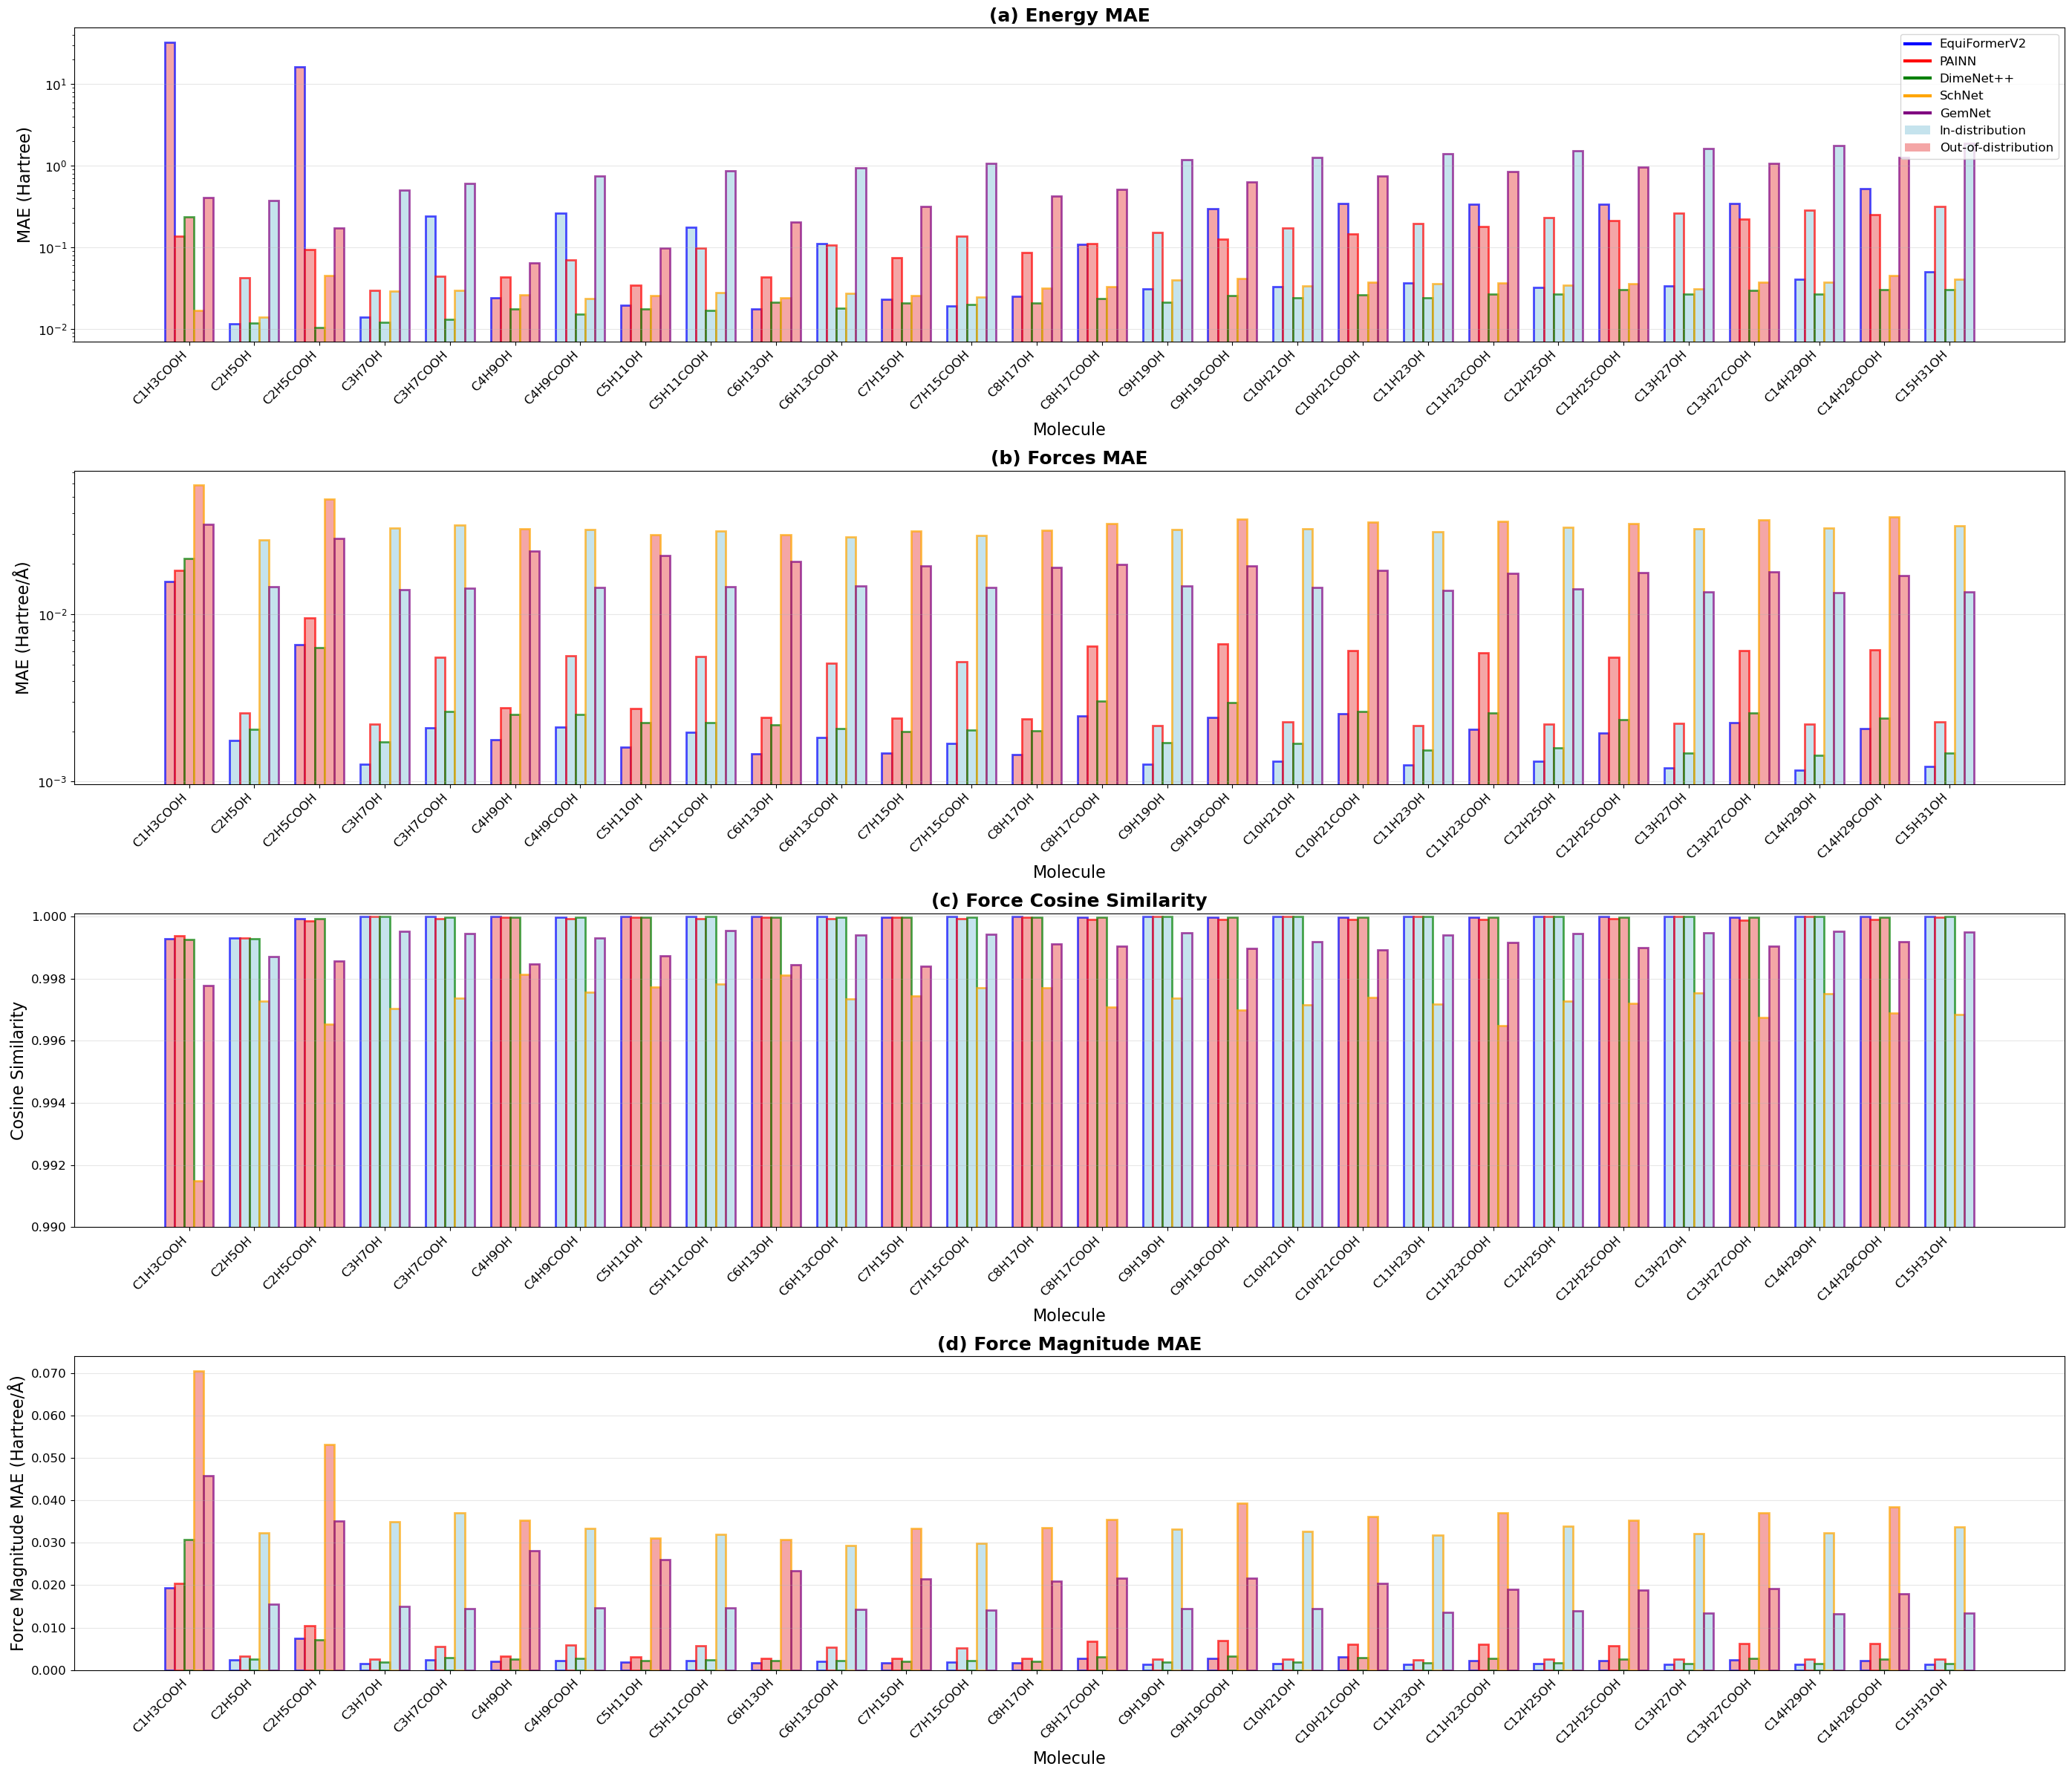

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import itertools
from typing import List

# Set up the figure with four vertical subplots
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(28, 24))

# Define molecule names
alcohols: List[str] = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]
acids: List[str] = [f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)]

molecule_names: List[str] = list(itertools.chain.from_iterable(zip(acids, alcohols)))

# Define training indices based on your specification
training_indices = []
test_indices = []

for i, molecule in enumerate(molecule_names):
    if 'COOH' in molecule:
        # Carboxylic acids
        carbon_count = int(molecule.split('H')[0][1:]) + 1  # +1 because COOH adds one carbon
        if 4 <= carbon_count <= 8:  # C3H7COOH to C7H15COOH corresponds to 4-8 total carbons
            training_indices.append(i)
        else:
            test_indices.append(i)
    else:
        # Alcohols
        carbon_count = int(molecule.split('H')[0][1:])
        if 4 <= carbon_count <= 8:  # C4H9OH to C8H17OH
            test_indices.append(i)
        else:
            training_indices.append(i)

# Bar chart parameters
n_molecules = len(molecule_names)
models = list(energy_df_updated['Model'].unique())
n_models = len(models)
bar_width = 0.15
x = np.arange(n_molecules)

# Create offset positions for each model's bars
offsets = np.linspace(-bar_width * (n_models - 1) / 2, bar_width * (n_models - 1) / 2, n_models)

# Subplot 1: Energy MAE
for i, model in enumerate(models):
    model_data = energy_df_updated[energy_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        y_values = model_data['MAE'].values
        
        # Create colors based on in-distribution vs out-of-distribution
        colors = ['lightblue' if idx in training_indices else 'lightcoral' for idx in range(n_molecules)]
        
        bars = ax1.bar(x + offsets[i], y_values, bar_width, 
                      color=colors, alpha=0.7, 
                      edgecolor=model_colors_updated[model], linewidth=2,
                      label=model if i == 0 else "")

ax1.set_xlabel('Molecule', fontsize=16)
ax1.set_ylabel('MAE (eV)', fontsize=16)
ax1.set_title('(a) Energy MAE', fontsize=18, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=12)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3, axis='y')
ax1.tick_params(axis='both', which='major', labelsize=12)

# Subplot 2: Forces MAE
for i, model in enumerate(models):
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        y_values = model_data['MAE'].values
        
        colors = ['lightblue' if idx in training_indices else 'lightcoral' for idx in range(n_molecules)]
        
        bars = ax2.bar(x + offsets[i], y_values, bar_width, 
                      color=colors, alpha=0.7, 
                      edgecolor=model_colors_updated[model], linewidth=2)

ax2.set_xlabel('Molecule', fontsize=16)
ax2.set_ylabel('MAE (eV/Å)', fontsize=16)
ax2.set_title('(b) Forces MAE', fontsize=18, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=12)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3, axis='y')
ax2.tick_params(axis='both', which='major', labelsize=12)

# Subplot 3: Cosine Similarity
for i, model in enumerate(models):
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    y_values = model_data['Cosine_Similarity'].values
    
    colors = ['lightblue' if idx in training_indices else 'lightcoral' for idx in range(n_molecules)]
    
    bars = ax3.bar(x + offsets[i], y_values, bar_width, 
                  color=colors, alpha=0.7, 
                  edgecolor=model_colors_updated[model], linewidth=2)

ax3.set_xlabel('Molecule', fontsize=16)
ax3.set_ylabel('Cosine Similarity', fontsize=16)
ax3.set_title('(c) Force Cosine Similarity', fontsize=18, fontweight='bold')
ax3.set_xticks(x)
ax3.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=12)
ax3.set_ylim(0.99, 1.0001)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax3.grid(True, alpha=0.3, axis='y')
ax3.tick_params(axis='both', which='major', labelsize=12)

# Subplot 4: Force Magnitude MAE
for i, model in enumerate(models):
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    y_values = model_data['Magnitude_MAE'].values
    
    colors = ['lightblue' if idx in training_indices else 'lightcoral' for idx in range(n_molecules)]
    
    bars = ax4.bar(x + offsets[i], y_values, bar_width, 
                  color=colors, alpha=0.7, 
                  edgecolor=model_colors_updated[model], linewidth=2)

ax4.set_xlabel('Molecule', fontsize=16)
ax4.set_ylabel('Force Magnitude MAE (eV/Å)', fontsize=16)
ax4.set_title('(d) Force Magnitude MAE', fontsize=18, fontweight='bold')
ax4.set_xticks(x)
ax4.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=12)
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax4.grid(True, alpha=0.3, axis='y')
ax4.tick_params(axis='both', which='major', labelsize=12)

# Create custom legend
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Model legend entries (using edge colors)
model_handles = [Line2D([0], [0], color=model_colors_updated[model], linewidth=3, label=model) 
                for model in models]

# Distribution legend entries
training_patch = Patch(facecolor='lightblue', alpha=0.7, label='In-distribution')
test_patch = Patch(facecolor='lightcoral', alpha=0.7, label='Out-of-distribution')

# Combine all legend entries
all_handles = model_handles + [training_patch, test_patch]
all_labels = models + ['In-distribution', 'Out-of-distribution']

# Add legend to the first subplot
ax1.legend(handles=all_handles, labels=all_labels, fontsize=12, loc='upper right')

plt.tight_layout()

# Save to PDF with selectable text
plt.savefig('generalisation_checkpoints/cross_length_functionality/cross_length_functionality_figure_2_bars.pdf', 
            format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

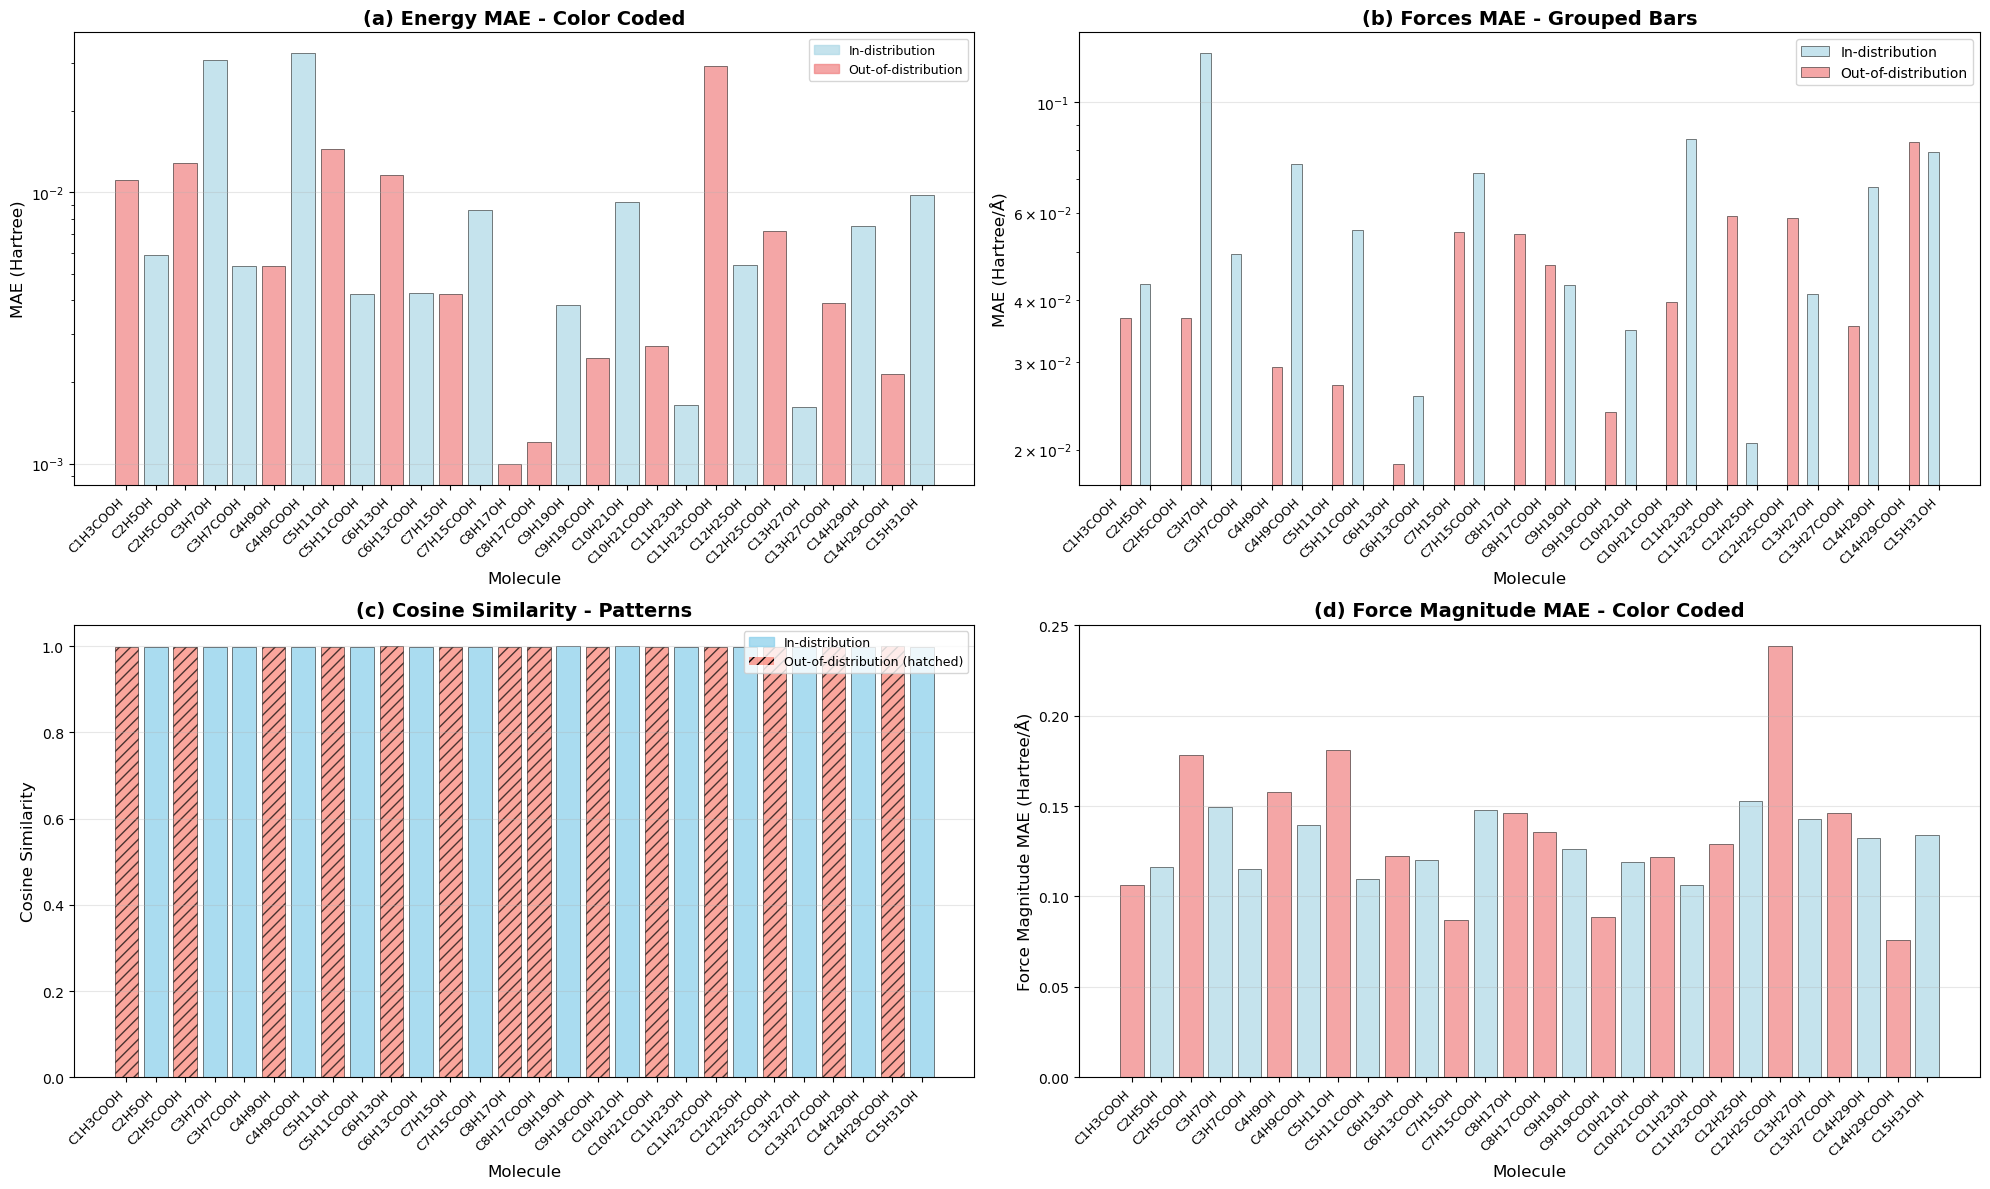

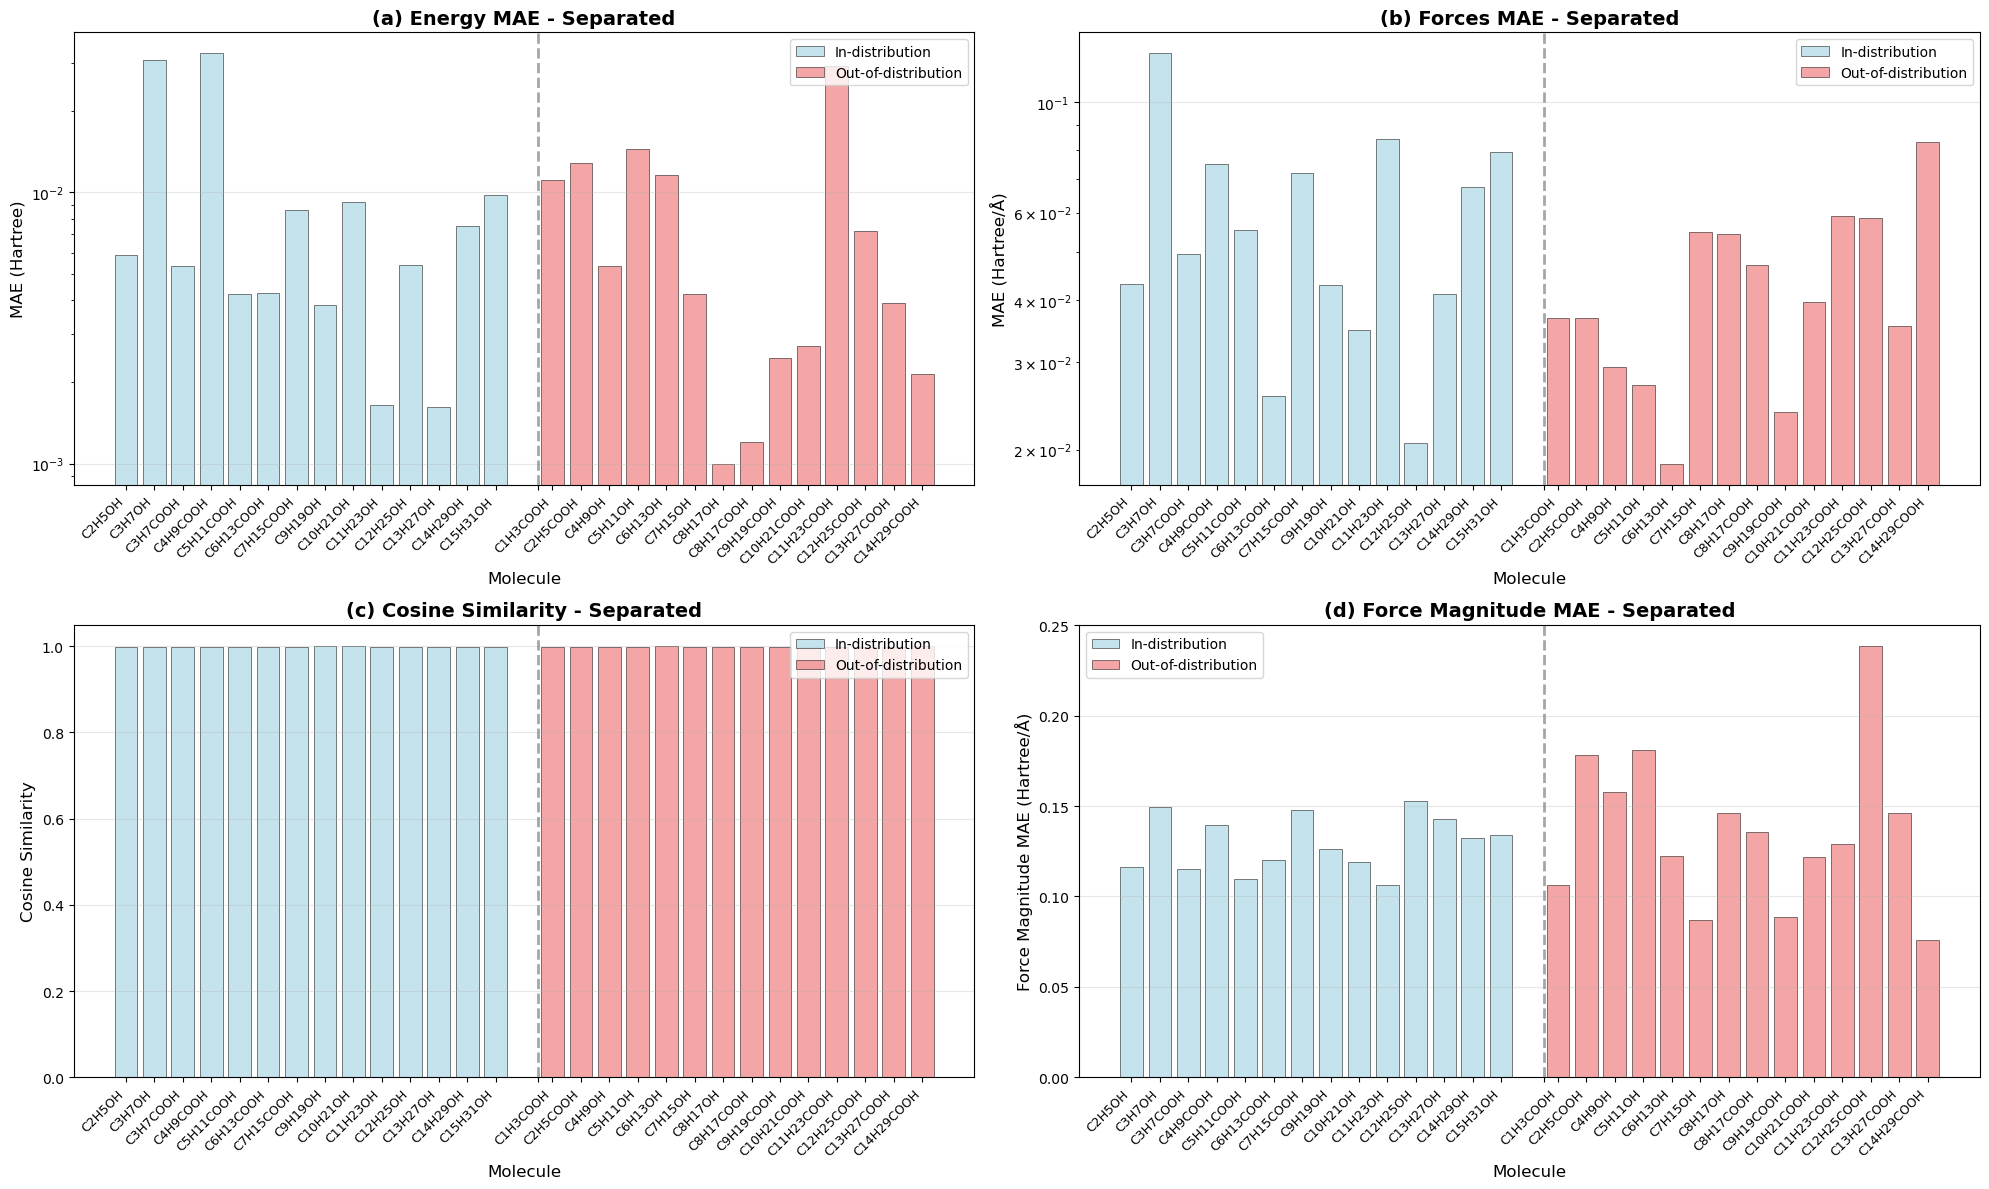

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import itertools
from typing import List

# Set up the figure with three subplots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 12))

# Define molecule names
alcohols: List[str] = [f"C{i}H{2*i+1}OH" for i in range(2, 16)]
acids: List[str] = [f"C{i-1}H{2*i-1}COOH" for i in range(2, 16)]

molecule_names: List[str] = list(itertools.chain.from_iterable(zip(acids, alcohols)))

# Define training indices based on your specification
training_indices = []
test_indices = []

for i, molecule in enumerate(molecule_names):
    if 'COOH' in molecule:
        # Carboxylic acids
        carbon_count = int(molecule.split('H')[0][1:]) + 1  # +1 because COOH adds one carbon
        if 4 <= carbon_count <= 8:  # C3H7COOH to C7H15COOH corresponds to 4-8 total carbons
            training_indices.append(i)
        else:
            test_indices.append(i)
    else:
        # Alcohols
        carbon_count = int(molecule.split('H')[0][1:])
        if 4 <= carbon_count <= 8:  # C4H9OH to C8H17OH
            test_indices.append(i)
        else:
            training_indices.append(i)

# Create distribution indicator arrays
distribution_indicator = ['In-dist' if i in training_indices else 'Out-of-dist' for i in range(len(molecule_names))]

# Method 1: Different bar colors for in-distribution vs out-of-distribution
def plot_bars_with_color_coding(ax, y_data, model_name, title, ylabel, log_scale=False):
    bar_width = 0.8
    x_pos = np.arange(len(molecule_names))
    
    # Create colors array based on distribution
    colors = ['lightblue' if i in training_indices else 'lightcoral' for i in range(len(molecule_names))]
    
    bars = ax.bar(x_pos, y_data, bar_width, color=colors, alpha=0.7, 
                  edgecolor='black', linewidth=0.5)
    
    ax.set_xlabel('Molecule', fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
    if log_scale:
        ax.set_yscale('log')
    ax.grid(True, alpha=0.3, axis='y')
    
    return bars

# Method 2: Grouped bars by distribution type
def plot_grouped_bars(ax, y_data, model_name, title, ylabel, log_scale=False):
    # Separate data by distribution type
    in_dist_data = [y_data[i] if i in training_indices else 0 for i in range(len(y_data))]
    out_dist_data = [y_data[i] if i in test_indices else 0 for i in range(len(y_data))]
    
    bar_width = 0.35
    x_pos = np.arange(len(molecule_names))
    
    # Only show bars where data exists
    in_dist_mask = np.array(in_dist_data) > 0
    out_dist_mask = np.array(out_dist_data) > 0
    
    bars1 = ax.bar(x_pos[in_dist_mask] - bar_width/2, np.array(in_dist_data)[in_dist_mask], 
                   bar_width, label='In-distribution', color='lightblue', alpha=0.7,
                   edgecolor='black', linewidth=0.5)
    bars2 = ax.bar(x_pos[out_dist_mask] + bar_width/2, np.array(out_dist_data)[out_dist_mask], 
                   bar_width, label='Out-of-distribution', color='lightcoral', alpha=0.7,
                   edgecolor='black', linewidth=0.5)
    
    ax.set_xlabel('Molecule', fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
    if log_scale:
        ax.set_yscale('log')
    ax.grid(True, alpha=0.3, axis='y')
    ax.legend()
    
    return bars1, bars2

# Method 3: Hatched patterns for distribution types
def plot_bars_with_patterns(ax, y_data, model_name, title, ylabel, log_scale=False):
    bar_width = 0.8
    x_pos = np.arange(len(molecule_names))
    
    # Create pattern and color arrays
    patterns = [None if i in training_indices else '///' for i in range(len(molecule_names))]
    colors = ['skyblue' if i in training_indices else 'salmon' for i in range(len(molecule_names))]
    
    bars = []
    for i, (x, y, pattern, color) in enumerate(zip(x_pos, y_data, patterns, colors)):
        bar = ax.bar(x, y, bar_width, color=color, alpha=0.7, 
                     hatch=pattern, edgecolor='black', linewidth=0.5)
        bars.append(bar)
    
    ax.set_xlabel('Molecule', fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
    if log_scale:
        ax.set_yscale('log')
    ax.grid(True, alpha=0.3, axis='y')
    
    return bars

# Example usage - you'll need to replace these with your actual data
# For demonstration, I'm creating sample data
np.random.seed(42)
sample_energy_data = np.random.lognormal(-5, 1, len(molecule_names))
sample_forces_data = np.random.lognormal(-3, 0.5, len(molecule_names))
sample_cosine_data = 0.999 + np.random.normal(0, 0.0005, len(molecule_names))
sample_magnitude_data = np.random.lognormal(-2, 0.3, len(molecule_names))

# Apply different methods to each subplot
# Method 1: Color coding
plot_bars_with_color_coding(ax1, sample_energy_data, 'Model', 
                           '(a) Energy MAE - Color Coded', 'MAE (eV)', log_scale=True)

# Method 2: Grouped bars
plot_grouped_bars(ax2, sample_forces_data, 'Model',
                 '(b) Forces MAE - Grouped Bars', 'MAE (eV/Å)', log_scale=True)

# Method 3: Hatched patterns
plot_bars_with_patterns(ax3, sample_cosine_data, 'Model',
                       '(c) Cosine Similarity - Patterns', 'Cosine Similarity')

# Method 1 again for consistency
plot_bars_with_color_coding(ax4, sample_magnitude_data, 'Model',
                           '(d) Force Magnitude MAE - Color Coded', 'Force Magnitude MAE (eV/Å)')

# Add custom legend for Method 1 and 3 (color coding and patterns)
from matplotlib.patches import Patch
in_dist_patch = Patch(color='lightblue', alpha=0.7, label='In-distribution')
out_dist_patch = Patch(color='lightcoral', alpha=0.7, label='Out-of-distribution')
pattern_patch = Patch(facecolor='salmon', hatch='///', alpha=0.7, label='Out-of-distribution (hatched)')

# Add legend to first subplot
ax1.legend(handles=[in_dist_patch, out_dist_patch], loc='upper right', fontsize=9)

# Add legend with patterns to third subplot
ax3.legend(handles=[Patch(color='skyblue', alpha=0.7, label='In-distribution'),
                   pattern_patch], loc='upper right', fontsize=9)

plt.tight_layout()
plt.savefig('bar_plot_distribution_methods.pdf', format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

# Additional Method 4: Side-by-side comparison plots
fig2, ((ax5, ax6), (ax7, ax8)) = plt.subplots(2, 2, figsize=(20, 12))

def create_separated_bar_plots(ax, y_data, title, ylabel, log_scale=False):
    """Create two separate bar plots side by side for in-dist vs out-of-dist"""
    
    # Separate data
    in_dist_molecules = [molecule_names[i] for i in training_indices]
    in_dist_values = [y_data[i] for i in training_indices]
    out_dist_molecules = [molecule_names[i] for i in test_indices]
    out_dist_values = [y_data[i] for i in test_indices]
    
    # Create positions
    x_in = np.arange(len(in_dist_molecules))
    x_out = np.arange(len(out_dist_molecules)) + len(in_dist_molecules) + 1
    
    # Plot bars
    ax.bar(x_in, in_dist_values, color='lightblue', alpha=0.7, 
           label='In-distribution', edgecolor='black', linewidth=0.5)
    ax.bar(x_out, out_dist_values, color='lightcoral', alpha=0.7,
           label='Out-of-distribution', edgecolor='black', linewidth=0.5)
    
    # Add vertical separator
    separator_pos = len(in_dist_molecules) + 0.5
    ax.axvline(x=separator_pos, color='gray', linestyle='--', linewidth=2, alpha=0.7)
    
    # Set labels and formatting
    all_molecules = in_dist_molecules + [''] + out_dist_molecules
    all_positions = list(x_in) + [separator_pos] + list(x_out)
    
    ax.set_xlabel('Molecule', fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xticks(all_positions)
    ax.set_xticklabels(all_molecules, rotation=45, ha='right', fontsize=9)
    if log_scale:
        ax.set_yscale('log')
    ax.grid(True, alpha=0.3, axis='y')
    ax.legend()

# Apply Method 4 to second figure
create_separated_bar_plots(ax5, sample_energy_data, 
                          '(a) Energy MAE - Separated', 'MAE (eV)', log_scale=True)
create_separated_bar_plots(ax6, sample_forces_data,
                          '(b) Forces MAE - Separated', 'MAE (eV/Å)', log_scale=True)
create_separated_bar_plots(ax7, sample_cosine_data,
                          '(c) Cosine Similarity - Separated', 'Cosine Similarity')
create_separated_bar_plots(ax8, sample_magnitude_data,
                          '(d) Force Magnitude MAE - Separated', 'Force Magnitude MAE (eV/Å)')

plt.tight_layout()
plt.savefig('generalisation_checkpoints/cross_length_functionality/bar_plot_separated_distribution.pdf', format='pdf', bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

In [74]:
import pickle

# Save your dictionaries
data_to_save = {
    'energy_df_updated': energy_df_updated,
    'forces_df_updated': forces_df_updated,
    'model_colors_updated': model_colors_updated
}
# Save
with open('generalisation_checkpoints/cross_length_functionality/plot_data.pkl', 'wb') as f:
    pickle.dump(data_to_save, f)


In [1]:
%cd ..

/home/masoud/Projects/SCAI


KeyError: 'Force_Magnitude_MAE'

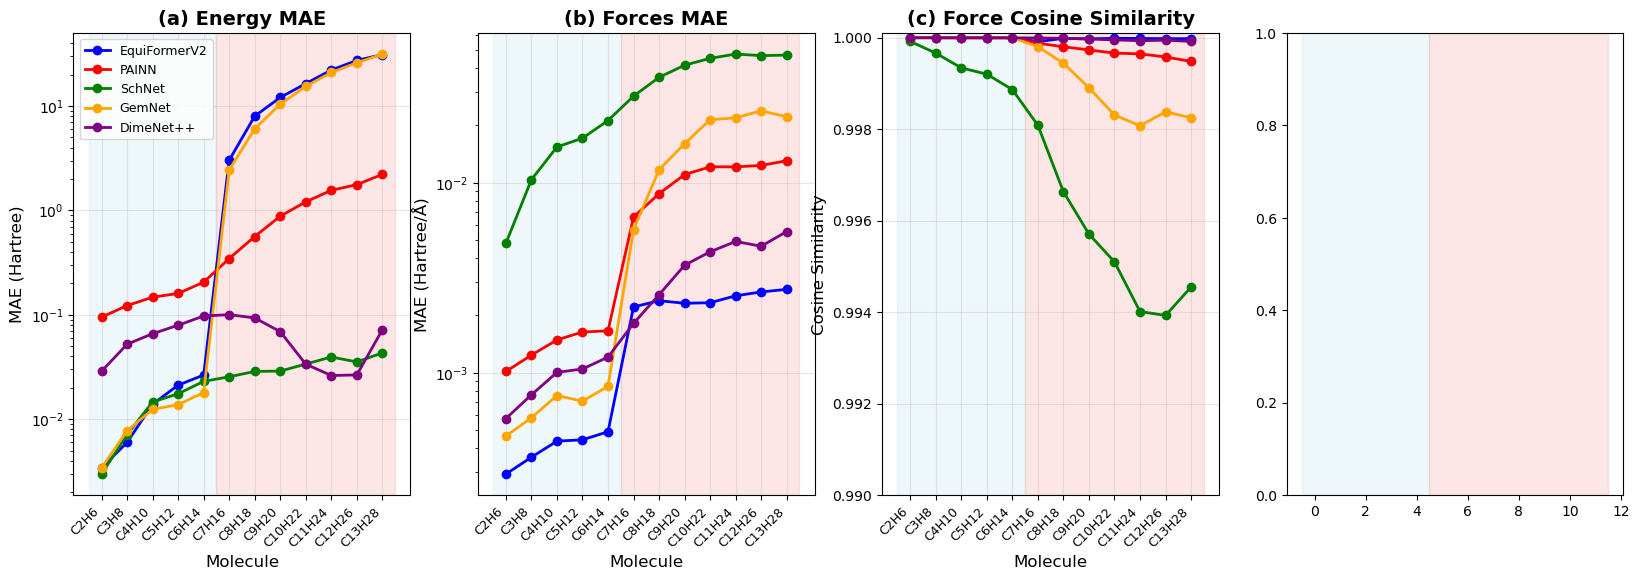

In [ ]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42  # Enable selectable text in PDF

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Set up the figure with three subplots
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(20, 6))

# Define molecule names
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']

# Subplot 1: Energy MAE
ax1.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue')
ax1.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral')
for model in energy_df_updated['Model'].unique():
    model_data = energy_df_updated[energy_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(molecule_names))
        y_coords = model_data['MAE'].values
        ax1.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model], label=model)
ax1.set_xlabel('Molecule', fontsize=12)
ax1.set_ylabel('MAE (eV)', fontsize=12)
ax1.set_title('(a) Energy MAE', fontsize=14, fontweight='bold')
ax1.set_xticks(range(len(molecule_names)))
ax1.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax1.set_yscale('log')
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=9)

# Subplot 2: Forces MAE
ax2.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue')
ax2.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral')
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    if not model_data['MAE'].isna().all():
        x_coords = range(len(molecule_names))
        y_coords = model_data['MAE'].values
        ax2.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
                color=model_colors_updated[model])
ax2.set_xlabel('Molecule', fontsize=12)
ax2.set_ylabel('MAE (eV/Å)', fontsize=12)
ax2.set_title('(b) Forces MAE', fontsize=14, fontweight='bold')
ax2.set_xticks(range(len(molecule_names)))
ax2.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax2.set_yscale('log')
ax2.grid(True, alpha=0.3)

# Subplot 3: Cosine Similarity
ax3.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue')
ax3.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral')
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    x_coords = range(len(molecule_names))
    y_coords = model_data['Cosine_Similarity'].values
    ax3.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax3.set_xlabel('Molecule', fontsize=12)
ax3.set_ylabel('Cosine Similarity', fontsize=12)
ax3.set_title('(c) Force Cosine Similarity', fontsize=14, fontweight='bold')
ax3.set_xticks(range(len(molecule_names)))
ax3.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax3.set_ylim(0.99, 1.0001)
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax3.grid(True, alpha=0.3)


# Subplot 4: Force Magnitude MAE
ax4.axvspan(-0.5, 4.5, alpha=0.2, color='lightblue')
ax4.axvspan(4.5, 11.5, alpha=0.2, color='lightcoral')
for model in forces_df_updated['Model'].unique():
    model_data = forces_df_updated[forces_df_updated['Model'] == model]
    x_coords = range(len(molecule_names))
    y_coords = model_data['Force_Magnitude_MAE'].values
    ax4.plot(x_coords, y_coords, marker='o', markersize=6, linewidth=2, 
            color=model_colors_updated[model])
ax4.set_xlabel('Molecule', fontsize=12)
ax4.set_ylabel('Force Magnitude MAE (eV/Å)', fontsize=12)
ax4.set_title('(d) Force Magnitude MAE', fontsize=14, fontweight='bold')
ax4.set_xticks(range(len(molecule_names)))
ax4.set_xticklabels(molecule_names, rotation=45, ha='right', fontsize=9)
ax4.set_ylim(0.99, 1.0001)
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.3f}'))
ax4.grid(True, alpha=0.3)

# Add training/test labels only once
ax1.text(2, ax1.get_ylim()[1]*0.9, 'In-distribution', ha='center', fontsize=10, fontweight='bold', color='blue')
ax1.text(8, ax1.get_ylim()[1]*0.9, 'Out-of-distribution', ha='center', fontsize=10, fontweight='bold', color='red')

plt.tight_layout()




In [82]:
import pickle

# Save your dictionaries
data_to_save = {
    'energy_df_updated': energy_df_updated,
    'forces_df_updated': forces_df_updated,
    'model_colors_updated': model_colors_updated
}

# Save
with open('generalisation_checkpoints/length_generalisation/plot_data.pkl', 'wb') as f:
    pickle.dump(data_to_save, f)



In [5]:
import pickle
# Load later
with open('generalisation_checkpoints/length_generalisation/plot_data.pkl', 'rb') as f:
    loaded_data = pickle.load(f)
    
energy_df_updated = loaded_data['energy_df_updated']
forces_df_updated = loaded_data['forces_df_updated']
model_colors_updated = loaded_data['model_colors_updated']

In [ ]:
# Create updated MAE plot with all models including the new one
fig_mae_updated = go.Figure()

# Add traces for each model including the new one
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    # Skip models with all NaN values
    if not model_data['MAE'].isna().all():
        fig_mae_updated.add_trace(go.Scatter(
            x=model_data['Molecule'],  # Use molecule symbols instead of indices
            y=model_data['MAE'],
            mode='markers+lines',
            name=model,
            line=dict(color=model_colors_updated[model]),
            marker=dict(size=8, color=model_colors_updated[model])
        ))

# Update layout for MAE plot
fig_mae_updated.update_layout(
    title="Mean Absolute Error (MAE) For Length Generalization",
    xaxis_title="Molecule",
    yaxis_title="MAE (eV)",
    template="plotly_white",
    font=dict(size=12),
    legend=dict(
        x=0.02,
        y=0.8,
        xanchor='left',
        yanchor='top',
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        borderwidth=1
    ),
    width=900,
    height=500
)

# Add background rectangles - blue for train data, red for test data
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']
num_molecules = len(molecule_names)

# Train data background (first 5 molecules: C2H6 to C6H14)
fig_mae_updated.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=0, y1=1,
              fillcolor="LightSkyBlue", opacity=0.2,
              layer="below", line_width=0, yref="paper")

# Test data background (last 7 molecules: C7H16 to C13H28)  
fig_mae_updated.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=0, y1=1,
              fillcolor="LightCoral", opacity=0.2,
              layer="below", line_width=0, yref="paper")

# Rotate x-axis labels for better readability
fig_mae_updated.update_xaxes(tickangle=45)

# Set y-axis to log scale for better visualization
fig_mae_updated.update_yaxes(type="log")  

fig_mae_updated.show()

In [56]:
# Create updated Cosine Similarity plot with all models including the new one
fig_cos_updated = go.Figure()

# Add traces for each model including the new one
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    # Include all data since NaN values have been replaced with 0
    fig_cos_updated.add_trace(go.Scatter(
        x=model_data['Molecule'],  # Use molecule symbols instead of indices
        y=model_data['Cosine_Similarity'],
        mode='markers+lines',
        name=model,
        line=dict(color=model_colors_updated[model]),
        marker=dict(size=8, color=model_colors_updated[model])
    ))

# Update layout for Cosine Similarity plot
fig_cos_updated.update_layout(
    title="Mean Cosine Similarity Across Molecules for Different Models (Updated)",
    xaxis_title="Molecule",
    yaxis_title="Mean Cosine Similarity",
    template="plotly_white",
    font=dict(size=12),
    legend=dict(
        x=0.02,
        y=0.12,
        xanchor='left',
        yanchor='bottom',
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        borderwidth=1
    ),
    width=900,
    height=500
)

# Add background rectangles - blue for train data, red for test data
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']
num_molecules = len(molecule_names)

# Train data background (first 5 molecules: C2H6 to C6H14)
fig_cos_updated.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=0, y1=1,
              fillcolor="LightSkyBlue", opacity=0.2,
              layer="below", line_width=0, yref="paper")

# Test data background (last 7 molecules: C7H16 to C13H28)
fig_cos_updated.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=0, y1=1,
              fillcolor="LightCoral", opacity=0.2,
              layer="below", line_width=0, yref="paper")

# Rotate x-axis labels for better readability
fig_cos_updated.update_xaxes(tickangle=45)

# Set y-axis range to focus on the data range
y_min = 0.99
y_max = 1.0001
fig_cos_updated.update_yaxes(range=[y_min, y_max], tickformat=".4f")

fig_cos_updated.show()



In [87]:
# Save figures into HTML and PNG files
fig_mae_updated.write_html("figures/mae_per_molecule_all_models.html")
# fig_mae_updated.write_image("figures/mae_per_molecule_all_models.png")
fig_cos_updated.write_html("figures/cosine_similarity_per_molecule_all_models.html")
# fig_cos_updated.write_image("figures/cosine_similarity_per_molecule_all_models.png")

In [ ]:
# Create updated combined side-by-side subplots with all models including the new one
fig_combined_updated = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Mean Absolute Error (MAE)', 'Mean Cosine Similarity'),
    horizontal_spacing=0.1
)

# Add MAE traces to first subplot
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    if not model_data['MAE'].isna().all():
        fig_combined_updated.add_trace(
            go.Scatter(
                x=model_data['Molecule'],  # Use molecule symbols instead of indices
                y=model_data['MAE'],
                mode='markers+lines',
                name=model,
                line=dict(color=model_colors_updated[model]),
                marker=dict(size=6, color=model_colors_updated[model]),
                showlegend=True
            ),
            row=1, col=1
        )

# Add Cosine Similarity traces to second subplot
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    fig_combined_updated.add_trace(
        go.Scatter(
            x=model_data['Molecule'],  # Use molecule symbols instead of indices
            y=model_data['Cosine_Similarity'],
            mode='markers+lines',
            name=model,
            line=dict(color=model_colors_updated[model]),
            marker=dict(size=6, color=model_colors_updated[model]),
            showlegend=False  # Don't duplicate legend
        ),
        row=1, col=2
    )

# Calculate proper Y-axis range for MAE
y_min_mae = df_updated['MAE'].min() * 0.9  # Add 10% padding below
y_max_mae = df_updated['MAE'].max() * 1.1  # Add 10% padding above

# Add background rectangles - blue for train data, red for test data
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']
num_molecules = len(molecule_names)

# Train data background for both subplots (first 5 molecules: C2H6 to C6H14)
fig_combined_updated.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=y_min_mae, y1=y_max_mae,
              fillcolor="LightSkyBlue", opacity=0.2,
              layer="below", line_width=0, row=1, col=1)
fig_combined_updated.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=0, y1=1,
              fillcolor="LightSkyBlue", opacity=0.2,
              layer="below", line_width=0, yref="paper", row=1, col=2)

# Test data background for both subplots (last 7 molecules: C7H16 to C13H28)
fig_combined_updated.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=y_min_mae, y1=y_max_mae,
              fillcolor="LightCoral", opacity=0.2,
              layer="below", line_width=0, row=1, col=1)
fig_combined_updated.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=0, y1=1,
              fillcolor="LightCoral", opacity=0.2,
              layer="below", line_width=0, yref="paper", row=1, col=2)

# Update x-axes
fig_combined_updated.update_xaxes(
    title_text="Molecule",
    tickangle=45,
    row=1, col=1
)
fig_combined_updated.update_xaxes(
    title_text="Molecule",
    tickangle=45,
    row=1, col=2
)

# Update y-axes - MAE with linear scale and proper formatting
fig_combined_updated.update_yaxes(
    title_text="MAE (eV)", 
    range=[y_min_mae, y_max_mae],
    tickformat=".6f",
    row=1, col=1
)
fig_combined_updated.update_yaxes(
    title_text="Mean Cosine Similarity", 
    range=[0, 1.0001],
    tickformat=".4f",
    row=1, col=2
)

# Update layout
fig_combined_updated.update_layout(
    title="Model Performance Comparison Across Molecules (Updated with New Model)",
    template="plotly_white",
    font=dict(size=12),
    width=1400,
    height=600,
    legend=dict(
        x=1.02,
        y=1,
        xanchor='left',
        yanchor='top'
    )
)

fig_combined_updated.show()

In [56]:
# Create updated summary table with all models including the new one
summary_data_updated = []

for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    # Calculate averages
    avg_mae = model_data['MAE'].mean()
    avg_cosine = model_data['Cosine_Similarity'].mean()
    
    # Calculate standard deviations
    std_mae = model_data['MAE'].std()
    std_cosine = model_data['Cosine_Similarity'].std()
    
    # Count valid predictions (non-zero cosine similarity values)
    valid_predictions = len(model_data[model_data['Cosine_Similarity'] > 0])
    
    summary_data_updated.append({
        'Model': model,
        'Avg_MAE': avg_mae,
        'Std_MAE': std_mae,
        'Avg_Cosine_Similarity': avg_cosine,
        'Std_Cosine_Similarity': std_cosine,
        'Valid_Predictions': valid_predictions
    })

summary_df_updated = pd.DataFrame(summary_data_updated)
summary_df_updated = summary_df_updated.sort_values('Avg_MAE')

print("Updated Model Performance Summary:")
print("=" * 80)
for _, row in summary_df_updated.iterrows():
    print(f"Model: {row['Model']}")
    print(f"  Average MAE: {row['Avg_MAE']:.6f} ± {row['Std_MAE']:.6f}")
    print(f"  Average Cosine Similarity: {row['Avg_Cosine_Similarity']:.6f} ± {row['Std_Cosine_Similarity']:.6f}")
    print(f"  Valid Predictions (Cosine > 0): {row['Valid_Predictions']}/12")
    print("-" * 40)

# Display the updated summary DataFrame
summary_df_updated

Updated Model Performance Summary:
Model: EquiFormerV2
  Average MAE: 0.001450 ± 0.000996
  Average Cosine Similarity: 0.999969 ± 0.000031
  Valid Predictions (Cosine > 0): 12/12
----------------------------------------
Model: DPP
  Average MAE: 0.002735 ± 0.001967
  Average Cosine Similarity: 0.999970 ± 0.000037
  Valid Predictions (Cosine > 0): 12/12
----------------------------------------
Model: PAINN
  Average MAE: 0.006941 ± 0.005236
  Average Cosine Similarity: 0.999807 ± 0.000192
  Valid Predictions (Cosine > 0): 12/12
----------------------------------------
Model: eSCN
  Average MAE: 0.145015 ± 0.150214
  Average Cosine Similarity: 0.902948 ± 0.103727
  Valid Predictions (Cosine > 0): 12/12
----------------------------------------
Model: SchNet
  Average MAE: 0.683694 ± 0.007152
  Average Cosine Similarity: 0.000000 ± 0.000000
  Valid Predictions (Cosine > 0): 0/12
----------------------------------------


,Model,Avg_MAE,Std_MAE,Avg_Cosine_Similarity,Std_Cosine_Similarity,Valid_Predictions
4,EquiFormerV2,0.001450,0.000996,0.999969,0.000031,12
1,DPP,0.002735,0.001967,0.999970,0.000037,12
0,PAINN,0.006941,0.005236,0.999807,0.000192,12
2,eSCN,0.145015,0.150214,0.902948,0.103727,12
3,SchNet,0.683694,0.007152,0.000000,0.000000,0


In [46]:
# Process the results dictionary to create DataFrames for plotting
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

# Extract data from the results dictionary
plot_data = []
molecule_names = [f"C{i+2}H{2*(i+2)+2}" if i < 5 else f"C{i+7}H{2*(i+7)+2}" for i in range(12)]

for model_name, model_results in metrics.items():
    for i, result in enumerate(model_results):
        # Replace NaN cosine similarity with 0
        cosine_sim = result['Mean_Cosine_Similarity']
        if pd.isna(cosine_sim):
            cosine_sim = 0
            
        plot_data.append({
            'Model': model_name,
            'Molecule_Index': i + 1,
            'Molecule': molecule_names[i],
            'MAE': result['MAE'],
            'Cosine_Similarity': cosine_sim
        })

df = pd.DataFrame(plot_data)
print("Data processed successfully!")
print(f"Total data points: {len(df)}")
print(f"Models: {df['Model'].unique()}")
df.head()

Data processed successfully!
Total data points: 48
Models: ['PAINN' 'DPP' 'eSCN' 'SchNet']


,Model,Molecule_Index,Molecule,MAE,Cosine_Similarity
0,PAINN,1,C2H6,0.000979,0.999999
1,PAINN,2,C3H8,0.001212,0.999998
2,PAINN,3,C4H10,0.001416,0.999996
3,PAINN,4,C5H12,0.001559,0.999995
4,PAINN,5,C6H14,0.001643,0.999995


In [ ]:
# Create MAE plot
fig_mae = go.Figure()

# Color palette for different models
colors = ['blue', 'red', 'green', 'orange', 'purple']
model_colors = {model: colors[i] for i, model in enumerate(df['Model'].unique())}

# Add traces for each model
for model in df['Model'].unique():
    model_data = df[df['Model'] == model]
    
    # Skip models with all NaN values (like SchNet with zero predictions)
    if not model_data['MAE'].isna().all():
        fig_mae.add_trace(go.Scatter(
            x=model_data['Molecule'],  # Use molecule symbols instead of indices
            y=model_data['MAE'],
            mode='markers+lines',
            name=model,
            line=dict(color=model_colors[model]),
            marker=dict(size=8, color=model_colors[model])
        ))

# Calculate proper Y-axis range from actual data (using df for original data)
y_min_mae = df['MAE'].min() * 0.9  # Add 10% padding below
y_max_mae = df['MAE'].max() * 1.1  # Add 10% padding above

# Update layout for MAE plot
fig_mae.update_layout(
    title="Mean Absolute Error (MAE) Across Molecules for Different Models",
    xaxis_title="Molecule",
    yaxis_title="MAE (eV)",
    template="plotly_white",
    font=dict(size=12),
    legend=dict(
        x=0.02,
        y=0.98,
        xanchor='left',
        yanchor='top',
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        borderwidth=1
    ),
    width=900,
    height=500
)

# Rotate x-axis labels for better readability
fig_mae.update_xaxes(tickangle=45)

# Set y-axis to linear scale with proper range and formatting
fig_mae.update_yaxes(
    range=[y_min_mae, y_max_mae],
    tickformat=".6f"  # Show 6 decimal places to avoid scientific notation
)

fig_mae.show()

In [48]:
# Create Cosine Similarity plot
fig_cos = go.Figure()

# Add traces for each model (now including models with 0 cosine similarity)
for model in df['Model'].unique():
    model_data = df[df['Model'] == model]
    
    # Now we include all data since NaN values have been replaced with 0
    fig_cos.add_trace(go.Scatter(
        x=model_data['Molecule'],  # Use molecule symbols instead of indices
        y=model_data['Cosine_Similarity'],
        mode='markers+lines',
        name=model,
        line=dict(color=model_colors[model]),
        marker=dict(size=8, color=model_colors[model])
    ))

# Update layout for Cosine Similarity plot
fig_cos.update_layout(
    title="Mean Cosine Similarity Across Molecules for Different Models",
    xaxis_title="Molecule",
    yaxis_title="Mean Cosine Similarity",
    template="plotly_white",
    font=dict(size=12),
    legend=dict(
        x=0.02,
        y=0.02,
        xanchor='left',
        yanchor='bottom',
        bgcolor='rgba(255, 255, 255, 0.8)',
        bordercolor='rgba(0, 0, 0, 0.2)',
        borderwidth=1
    ),
    width=900,
    height=500
)

# Rotate x-axis labels for better readability
fig_cos.update_xaxes(tickangle=45)

# Set y-axis range to focus on the data range (now starting from 0)
y_min = 0
y_max = 1.0001
fig_cos.update_yaxes(range=[y_min, y_max], tickformat=".4f")

fig_cos.show()

In [ ]:
# Create combined side-by-side subplots
fig_combined = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Mean Absolute Error (MAE)', 'Mean Cosine Similarity'),
    horizontal_spacing=0.1
)

# Add MAE traces to first subplot
for model in df['Model'].unique():
    model_data = df[df['Model'] == model]
    
    if not model_data['MAE'].isna().all():
        fig_combined.add_trace(
            go.Scatter(
                x=model_data['Molecule'],  # Use molecule symbols instead of indices
                y=model_data['MAE'],
                mode='markers+lines',
                name=model,
                line=dict(color=model_colors[model]),
                marker=dict(size=6, color=model_colors[model]),
                showlegend=True
            ),
            row=1, col=1
        )

# Add Cosine Similarity traces to second subplot (now including all models since NaN replaced with 0)
for model in df['Model'].unique():
    model_data = df[df['Model'] == model]
    
    fig_combined.add_trace(
        go.Scatter(
            x=model_data['Molecule'],  # Use molecule symbols instead of indices
            y=model_data['Cosine_Similarity'],
            mode='markers+lines',
            name=model,
            line=dict(color=model_colors[model]),
            marker=dict(size=6, color=model_colors[model]),
            showlegend=False  # Don't duplicate legend
        ),
        row=1, col=2
    )

# Calculate proper Y-axis range for MAE
y_min_mae = df['MAE'].min() * 0.9  # Add 10% padding below
y_max_mae = df['MAE'].max() * 1.1  # Add 10% padding above

# Update x-axes
fig_combined.update_xaxes(
    title_text="Molecule",
    tickangle=45,
    row=1, col=1
)
fig_combined.update_xaxes(
    title_text="Molecule",
    tickangle=45,
    row=1, col=2
)

# Update y-axes - MAE with linear scale and proper formatting
fig_combined.update_yaxes(
    title_text="MAE (eV)", 
    range=[y_min_mae, y_max_mae],
    tickformat=".6f",
    row=1, col=1
)
fig_combined.update_yaxes(
    title_text="Mean Cosine Similarity", 
    range=[0, 1.0001],  # Now starting from 0 instead of min value
    tickformat=".4f",
    row=1, col=2
)

# Update layout
fig_combined.update_layout(
    title="Model Performance Comparison Across Molecules",
    template="plotly_white",
    font=dict(size=12),
    width=1400,
    height=600,
    legend=dict(
        x=1.02,
        y=1,
        xanchor='left',
        yanchor='top'
    )
)

fig_combined.show()

In [ ]:
# Create a summary table showing average performance across all molecules
summary_data = []

for model in df['Model'].unique():
    model_data = df[df['Model'] == model]
    
    # Calculate averages (now including 0 values for cosine similarity)
    avg_mae = model_data['MAE'].mean()
    avg_cosine = model_data['Cosine_Similarity'].mean()
    
    # Calculate standard deviations
    std_mae = model_data['MAE'].std()
    std_cosine = model_data['Cosine_Similarity'].std()
    
    # Count valid predictions (non-zero cosine similarity values)
    valid_predictions = len(model_data[model_data['Cosine_Similarity'] > 0])
    
    summary_data.append({
        'Model': model,
        'Avg_MAE': avg_mae,
        'Std_MAE': std_mae,
        'Avg_Cosine_Similarity': avg_cosine,
        'Std_Cosine_Similarity': std_cosine,
        'Valid_Predictions': valid_predictions
    })

summary_df = pd.DataFrame(summary_data)
summary_df = summary_df.sort_values('Avg_MAE')

print("Model Performance Summary:")
print("=" * 80)
for _, row in summary_df.iterrows():
    print(f"Model: {row['Model']}")
    print(f"  Average MAE: {row['Avg_MAE']:.6f} ± {row['Std_MAE']:.6f}")
    print(f"  Average Cosine Similarity: {row['Avg_Cosine_Similarity']:.6f} ± {row['Std_Cosine_Similarity']:.6f}")
    print(f"  Valid Predictions (Cosine > 0): {row['Valid_Predictions']}/12")
    print("-" * 40)

# Display the summary DataFrame
summary_df

In [ ]:
config = yaml.safe_load(open("configs/Experiment-1-length-test/dataset.yml", "r"))
ckpt_path = "checkpoints/2025-08-05-15-51-44/checkpoint.pt"

In [ ]:
calculators = OCPCalculator(
    checkpoint_path=ckpt_path,
    cpu=False,
    trainer="equiformerv2_forces"
    )


In [ ]:
data = AseReadMultiStructureDataset({"src": "databases/Experiment-1/single",
                                     'pattern': '*.traj',
                                     'a2g_args': {'r_energy': True, 'r_forces': True},
                                     'key_mapping': {'atoms': 'atomic_numbers'}})
symbols = [ase.data.chemical_symbols[z.item()] for z in data[0].atomic_numbers]

In [ ]:
labels = []
preds = []

for idx, molecule in enumerate(data):
    atoms = Atoms(
        symbols=symbols,
        positions=molecule.pos.numpy(),
        cell=molecule.cell.numpy().reshape(3, 3),
        pbc=molecule.pbc.numpy()
        )
    labels.append(molecule.forces.numpy())

    atoms.calc = calculators
    # energy = atoms.get_potential_energy()
    forces = atoms.get_forces()
    preds.append(forces)

In [ ]:
metrics_res = calculate_force_metrics(labels, preds)

#### For C6H14

In [ ]:
metrics_res

#### For C5H12

In [ ]:
metrics_res

#### For C4H10

In [ ]:
metrics_res

#### For C3H8

In [ ]:
metrics_res

#### For C2H6

In [ ]:
metrics_res

#### For C13H28

In [ ]:
metrics_res

#### For C12H26

In [ ]:
metrics_res

#### For C11H24

In [ ]:
metrics_res

#### For C10H22

In [ ]:
metrics_res

#### For C9H20

In [ ]:
metrics_res

#### For C8H18

In [ ]:
metrics_res

In [ ]:
# Append it to a csv file
import pandas as pd
results_df = pd.DataFrame({
    "Molecule": ["C8H18"],
    "MAE (eV)": [metrics_res["MAE"]],
    "Mean Cosine Sim": [metrics_res["Mean_Cosine_Similarity"]],
    "Mean Force Mag": [metrics_res["Mean_Pred_Magnitude"]]
})
results_df.to_csv("force_metrics_results.csv", index=False)

#### For C7H14

In [ ]:
metrics_res

#### 

In [ ]:
data[0].atomic_numbers

In [ ]:
# Make a csv file with the results
import pandas as pd
results_df = pd.DataFrame({
    "Molecule": ["C7H16"],
    "MAE (eV)": [metrics_res["MAE"]],
    "Mean Cosine Sim": [metrics_res["Mean_Cosine_Similarity"]],
    "Mean Force Mag": [metrics_res["Mean_Pred_Magnitude"]]
})
results_df.to_csv("force_metrics_results.csv", index=False)

In [ ]:
from torch import nn
MAE = nn.L1Loss()
CS = nn.CosineSimilarity(dim=1, eps=1e-6)
mae_list = []
# cos_sim_list = []
for prd, gt in zip(preds, labels):
    prd = torch.tensor(prd, dtype=torch.float32)
    gt = torch.tensor(gt, dtype=torch.float32)
    mae = MAE(prd, gt)
    # cos_sim = CS(prd, gt)
    mae_list.append(mae.item())
    # cos_sim_list.append(cos_sim.item())


In [ ]:
mae_list

In [ ]:
data[0].pos.numpy() - data[10].pos.numpy()

### Ploting

In [ ]:
# Load the csv file and plot a line plot with plotly
import pandas as pd
import plotly.express as px
results_df = pd.read_csv("force_metrics_results.csv")
fig = px.line(results_df, x="Molecule", y=["MAE (eV)"], # , "Mean Cosine Sim", "Mean Force Mag"
              title="Force Prediction Metrics per Molecule",
              labels={"MAE (eV)": "Mean Absolute Error (eV)", "Molecule": "Molecule"})

# Set Y-axis range to focus on the specified data range and precision
y_min = 0.0002
y_max = 0.0030
fig.update_yaxes(tickformat=".5f", range=[y_min, y_max])

# Put a box on first 5 molecules
fig.update_traces(mode='markers+lines', marker=dict(size=10))

# Get the number of molecules for proper indexing
num_molecules = len(results_df)

# Set a background color for first 5 molecules (C2H6 to C6H14)
fig.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=y_min, y1=y_max,
              fillcolor="LightSkyBlue", opacity=0.3,
              layer="below", line_width=0)

# Set another box on last 7 molecules (C7H16 to C13H28)
fig.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=y_min, y1=y_max,
              fillcolor="LightCoral", opacity=0.3,
              layer="below", line_width=0)

fig.update_layout(xaxis_title="Molecule", yaxis_title="Mean Absolute Error (eV)")
# Set a theme for academic publication
fig.update_layout(template="plotly_white", font=dict(size=14))

# Rotate x-axis labels for better readability
fig.update_xaxes(tickangle=45)

fig.show()
# fig.write_html("force_metrics_results.html")
# fig.write_image("force_metrics_results.png")

In [ ]:
results_df["Mean Cosine Sim"]

In [ ]:
# Load the csv file and create subplots with plotly
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

results_df = pd.read_csv("force_metrics_results.csv")

# Create subplots with secondary y-axis or separate subplots
# Option 1: Vertically stacked subplots
fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=('Mean Absolute Error (eV)', 'Mean Cosine Similarity'),
    vertical_spacing=0.1
)

# Get the number of molecules for proper indexing
num_molecules = len(results_df)

# Add MAE plot to first subplot
fig.add_trace(
    go.Scatter(x=results_df["Molecule"], y=results_df["MAE (eV)"],
               mode='markers+lines', marker=dict(size=10),
               name="MAE", line=dict(color='blue')),
    row=1, col=1
)

# Add Mean Cosine Sim plot to second subplot
fig.add_trace(
    go.Scatter(x=results_df["Molecule"], y=results_df["Mean Cosine Sim"],
               mode='markers+lines', marker=dict(size=10),
               name="Cosine Sim", line=dict(color='red')),
    row=2, col=1
)

# Set Y-axis ranges for each subplot
# MAE subplot
y_min_mae = 0.0002
y_max_mae = 0.0030
fig.update_yaxes(tickformat=".5f", range=[y_min_mae, y_max_mae], row=1, col=1)

# Cosine Sim subplot
y_min_cos = results_df["Mean Cosine Sim"].min() * 0.999995
y_max_cos = results_df["Mean Cosine Sim"].max() * 1.000005
fig.update_yaxes(tickformat=".8f", range=[y_min_cos, y_max_cos], row=2, col=1)

# Add background rectangles for MAE subplot
fig.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=y_min_mae, y1=y_max_mae,
              fillcolor="LightSkyBlue", opacity=0.3,
              layer="below", line_width=0, row=1, col=1)
fig.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=y_min_mae, y1=y_max_mae,
              fillcolor="LightCoral", opacity=0.3,
              layer="below", line_width=0, row=1, col=1)

# Add background rectangles for Cosine Sim subplot
fig.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=y_min_cos, y1=y_max_cos,
              fillcolor="LightSkyBlue", opacity=0.3,
              layer="below", line_width=0, row=2, col=1)
fig.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=y_min_cos, y1=y_max_cos,
              fillcolor="LightCoral", opacity=0.3,
              layer="below", line_width=0, row=2, col=1)

# Update layout
fig.update_layout(
    title="Force Prediction Metrics per Molecule",
    template="plotly_white",
    font=dict(size=14),
    height=800,  # Increase height for better visibility
    showlegend=False
)

# Rotate x-axis labels for both subplots
fig.update_xaxes(tickangle=45, row=1, col=1)
fig.update_xaxes(tickangle=45, row=2, col=1, title_text="Molecule")

fig.show()
# fig.write_html("force_metrics_results_subplots.html")
# fig.write_image("force_metrics_results_subplots.png")

In [ ]:
# Option 2: Single plot with secondary y-axis (overlapping plots)
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

results_df = pd.read_csv("force_metrics_results.csv")

# Create figure with secondary y-axis
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Add MAE trace on primary y-axis
fig.add_trace(
    go.Scatter(x=results_df["Molecule"], y=results_df["MAE (eV)"],
               mode='markers+lines', marker=dict(size=10, color='blue'),
               name="MAE (eV)", line=dict(color='blue')),
    secondary_y=False,
)

# Add Cosine Similarity trace on secondary y-axis
fig.add_trace(
    go.Scatter(x=results_df["Molecule"], y=results_df["Mean Cosine Sim"],
               mode='markers+lines', marker=dict(size=10, color='red'),
               name="Mean Cosine Sim", line=dict(color='red')),
    secondary_y=True,
)

# Get the number of molecules for proper indexing
num_molecules = len(results_df)

# Set y-axes titles and ranges
fig.update_yaxes(title_text="MAE (eV)", tickformat=".4f", 
                 range=[0.0002, 0.0030], secondary_y=False)
fig.update_yaxes(title_text="Mean Cosine Similarity", tickformat=".5f",
                 range=[results_df["Mean Cosine Sim"].min() * 0.999995, 
                        results_df["Mean Cosine Sim"].max() * 1.000005], 
                 secondary_y=True)

# Add background rectangles
fig.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=0, y1=1,
              fillcolor="LightSkyBlue", opacity=0.2,
              layer="below", line_width=0, yref="paper")
fig.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=0, y1=1,
              fillcolor="LightCoral", opacity=0.2,
              layer="below", line_width=0, yref="paper")

# Update layout with legend positioned inside the plot
fig.update_layout(
    title="Force Prediction Metrics per Molecule (Dual Y-Axis)",
    template="plotly_white",
    font=dict(size=14),
    xaxis_title="Molecule",
    legend=dict(
        x=0.06,  # Position legend inside the plot area (left side)
        y=0.48,  # Position at the top
        xanchor='left',
        yanchor='bottom',
        bgcolor='rgba(255, 255, 255, 0.8)',  # Semi-transparent white background
        bordercolor='rgba(0, 0, 0, 0.2)',    # Light border
        borderwidth=1
    )
)

# Rotate x-axis labels
fig.update_xaxes(tickangle=45)

fig.show()
# fig.write_html("force_metrics_results_dual_axis.html")
# fig.write_image("force_metrics_results_dual_axis.png")

In [ ]:
# Option 3: Side-by-side subplots
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

results_df = pd.read_csv("force_metrics_results.csv")

# Create side-by-side subplots
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=('Mean Absolute Error (eV)', 'Mean Cosine Similarity'),
    horizontal_spacing=0.1
)

# Get the number of molecules for proper indexing
num_molecules = len(results_df)

# Add MAE plot to first subplot
fig.add_trace(
    go.Scatter(x=results_df["Molecule"], y=results_df["MAE (eV)"],
               mode='markers+lines', marker=dict(size=8),
               name="MAE", line=dict(color='blue')),
    row=1, col=1
)

# Add Mean Cosine Sim plot to second subplot
fig.add_trace(
    go.Scatter(x=results_df["Molecule"], y=results_df["Mean Cosine Sim"],
               mode='markers+lines', marker=dict(size=8),
               name="Cosine Sim", line=dict(color='red')),
    row=1, col=2
)

# Set Y-axis ranges for each subplot
# MAE subplot
y_min_mae = 0.0002
y_max_mae = 0.0030
fig.update_yaxes(tickformat=".4f", range=[y_min_mae, y_max_mae], row=1, col=1)

# Cosine Sim subplot
y_min_cos = results_df["Mean Cosine Sim"].min() * 0.999995
y_max_cos = results_df["Mean Cosine Sim"].max() * 1.000005
fig.update_yaxes(tickformat=".5f", range=[y_min_cos, y_max_cos], row=1, col=2)

# Add background rectangles for MAE subplot
fig.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=y_min_mae, y1=y_max_mae,
              fillcolor="LightSkyBlue", opacity=0.3,
              layer="below", line_width=0, row=1, col=1)
fig.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=y_min_mae, y1=y_max_mae,
              fillcolor="LightCoral", opacity=0.3,
              layer="below", line_width=0, row=1, col=1)

# Add background rectangles for Cosine Sim subplot
fig.add_shape(type="rect",
              x0=-0.5, x1=4.5, y0=y_min_cos, y1=y_max_cos,
              fillcolor="LightSkyBlue", opacity=0.3,
              layer="below", line_width=0, row=1, col=2)
fig.add_shape(type="rect",
              x0=4.5, x1=num_molecules-0.5, y0=y_min_cos, y1=y_max_cos,
              fillcolor="LightCoral", opacity=0.3,
              layer="below", line_width=0, row=1, col=2)

# Update layout
fig.update_layout(
    title="Force Prediction Metrics per Molecule",
    template="plotly_white",
    font=dict(size=14),
    width=1200,  # Increase width for better visibility
    height=500,
    showlegend=False
)

# Rotate x-axis labels and add titles
fig.update_xaxes(tickangle=45, title_text="Molecule", row=1, col=1)
fig.update_xaxes(tickangle=45, title_text="Molecule", row=1, col=2)

fig.show()
# fig.write_html("force_metrics_results_sidebyside.html")
# fig.write_image("force_metrics_results_sidebyside.png")

In [ ]:
# Combined all plots in a 2x2 grid
from plotly.subplots import make_subplots

fig_all = make_subplots(
    rows=2, cols=2,
    subplot_titles=[
        'Original MAE',
        'Original Cosine Similarity', 
        'Updated MAE',
        'Updated Cosine Similarity'
    ],
    vertical_spacing=0.12,
    horizontal_spacing=0.08
)

# Plot 1: Original MAE (top-left)
for model in ['PAINN', 'DPP', 'eSCN', 'SchNet', 'GemNet']:
    if model in metrics:
        model_data = df[df['Model'] == model]
        
        if not model_data['MAE'].isna().all():
            fig_all.add_trace(
                go.Scatter(
                    x=model_data['Molecule'],
                    y=model_data['MAE'],
                    mode='markers+lines',
                    name=f"{model} (orig)",
                    line=dict(color=model_colors[model]),
                    marker=dict(size=6, color=model_colors[model]),
                    showlegend=True
                ),
                row=1, col=1
            )

# Plot 2: Original Cosine Similarity (top-right)
for model in ['PAINN', 'DPP', 'eSCN', 'SchNet', 'GemNet']:
    if model in metrics:
        model_data = df[df['Model'] == model]
        
        fig_all.add_trace(
            go.Scatter(
                x=model_data['Molecule'],
                y=model_data['Cosine_Similarity'],
                mode='markers+lines',
                name=f"{model} (orig)",
                line=dict(color=model_colors[model]),
                marker=dict(size=6, color=model_colors[model]),
                showlegend=False
            ),
            row=1, col=2
        )

# Plot 3: Updated MAE (bottom-left)  
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    if not model_data['MAE'].isna().all():
        fig_all.add_trace(
            go.Scatter(
                x=model_data['Molecule'],
                y=model_data['MAE'],
                mode='markers+lines',
                name=f"{model} (updated)",
                line=dict(color=model_colors_updated[model]),
                marker=dict(size=6, color=model_colors_updated[model]),
                showlegend=True
            ),
            row=2, col=1
        )

# Plot 4: Updated Cosine Similarity (bottom-right)
for model in df_updated['Model'].unique():
    model_data = df_updated[df_updated['Model'] == model]
    
    fig_all.add_trace(
        go.Scatter(
            x=model_data['Molecule'],
            y=model_data['Cosine_Similarity'],
            mode='markers+lines',
            name=f"{model} (updated)",
            line=dict(color=model_colors_updated[model]),
            marker=dict(size=6, color=model_colors_updated[model]),
            showlegend=False
        ),
        row=2, col=2
    )

# Calculate proper Y-axis ranges for MAE plots
y_min_mae_orig = df['MAE'].min() * 0.9 if not df['MAE'].isna().all() else 0.0001
y_max_mae_orig = df['MAE'].max() * 1.1 if not df['MAE'].isna().all() else 0.001
y_min_mae_updated = df_updated['MAE'].min() * 0.9
y_max_mae_updated = df_updated['MAE'].max() * 1.1

# Add background rectangles for all 4 subplots
molecule_names = ['C2H6', 'C3H8', 'C4H10', 'C5H12', 'C6H14', 'C7H16', 'C8H18', 'C9H20', 'C10H22', 'C11H24', 'C12H26', 'C13H28']
num_molecules = len(molecule_names)

# Train data background (first 5 molecules: C2H6 to C6H14) - all 4 subplots
# MAE plots use actual data range
fig_all.add_shape(type="rect",
                 x0=-0.5, x1=4.5, y0=y_min_mae_orig, y1=y_max_mae_orig,
                 fillcolor="LightSkyBlue", opacity=0.2,
                 layer="below", line_width=0, row=1, col=1)
fig_all.add_shape(type="rect",
                 x0=-0.5, x1=4.5, y0=y_min_mae_updated, y1=y_max_mae_updated,
                 fillcolor="LightSkyBlue", opacity=0.2,
                 layer="below", line_width=0, row=2, col=1)
# Cosine similarity plots use paper reference
fig_all.add_shape(type="rect",
                 x0=-0.5, x1=4.5, y0=0, y1=1,
                 fillcolor="LightSkyBlue", opacity=0.2,
                 layer="below", line_width=0, yref="paper", row=1, col=2)
fig_all.add_shape(type="rect",
                 x0=-0.5, x1=4.5, y0=0, y1=1,
                 fillcolor="LightSkyBlue", opacity=0.2,
                 layer="below", line_width=0, yref="paper", row=2, col=2)

# Test data background (last 7 molecules: C7H16 to C13H28) - all 4 subplots
fig_all.add_shape(type="rect",
                 x0=4.5, x1=num_molecules-0.5, y0=y_min_mae_orig, y1=y_max_mae_orig,
                 fillcolor="LightCoral", opacity=0.2,
                 layer="below", line_width=0, row=1, col=1)
fig_all.add_shape(type="rect",
                 x0=4.5, x1=num_molecules-0.5, y0=y_min_mae_updated, y1=y_max_mae_updated,
                 fillcolor="LightCoral", opacity=0.2,
                 layer="below", line_width=0, row=2, col=1)
fig_all.add_shape(type="rect",
                 x0=4.5, x1=num_molecules-0.5, y0=0, y1=1,
                 fillcolor="LightCoral", opacity=0.2,
                 layer="below", line_width=0, yref="paper", row=1, col=2)
fig_all.add_shape(type="rect",
                 x0=4.5, x1=num_molecules-0.5, y0=0, y1=1,
                 fillcolor="LightCoral", opacity=0.2,
                 layer="below", line_width=0, yref="paper", row=2, col=2)

# Update x-axes for all subplots
for row in [1, 2]:
    for col in [1, 2]:
        fig_all.update_xaxes(
            title_text="Molecule",
            tickangle=45,
            row=row, col=col
        )

# Update y-axes with linear scale for MAE plots
fig_all.update_yaxes(
    title_text="MAE (eV)", 
    range=[y_min_mae_orig, y_max_mae_orig],
    tickformat=".6f",
    row=1, col=1
)
fig_all.update_yaxes(
    title_text="MAE (eV)", 
    range=[y_min_mae_updated, y_max_mae_updated],
    tickformat=".6f",
    row=2, col=1
)

# Cosine similarity plots (right column) - linear scale
fig_all.update_yaxes(
    title_text="Mean Cosine Similarity", 
    range=[0, 1.0001],
    tickformat=".4f",
    row=1, col=2
)
fig_all.update_yaxes(
    title_text="Mean Cosine Similarity", 
    range=[0, 1.0001],
    tickformat=".4f",
    row=2, col=2
)

# Update layout
fig_all.update_layout(
    title="Complete Model Performance Comparison - Original vs Updated",
    template="plotly_white",
    font=dict(size=10),
    width=1600,
    height=1200,
    legend=dict(
        x=1.02,
        y=1,
        xanchor='left',
        yanchor='top'
    )
)

fig_all.show()